<a href="https://colab.research.google.com/github/kawastony/quadratic-midpoint-tool-and-integral-calculus-tool/blob/main/Fusion2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Single Colab cell: load TCV L-H database and compute mismatch
!pip install -q h5py

import h5py
import numpy as np
import matplotlib.pyplot as plt

# Upload lhdatabase.h5 first, or mount and set path
path = "/content/lhdatabase.h5"   # change if needed

with h5py.File(path, "r") as f:
    print("Keys:", list(f.keys()))
    def walk(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name}: shape={obj.shape}, dtype={obj.dtype}")
    f.visititems(walk)

# --- edit the dataset paths below after inspecting the printout ---
# Example (replace with actual paths from the printout):
# with h5py.File(path, "r") as f:
#     P = f["power"][:]          # input power
#     Q = f["confinement"][:]    # internal response

# Placeholder once paths are known:
# dQ_dP = np.gradient(Q, P)
# peak = np.argmax(np.abs(dQ_dP))
# print(f"Mismatch peak at P = {P[peak]:.3f}, height = {dQ_dP[peak]:.3f}")
# plt.plot(P, dQ_dP)
# plt.xlabel("P"); plt.ylabel("dQ/dP"); plt.title("Mismatch")
# plt.show()

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/content/lhdatabase.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
# Single Colab cell: download TCV L-H database and inspect
!pip install -q h5py
!wget -q -O /content/lhdatabase.h5 "https://zenodo.org/records/14996664/files/lhdatabase.h5"

import h5py

with h5py.File("/content/lhdatabase.h5", "r") as f:
    print("Keys:", list(f.keys()))
    def walk(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name}: shape={obj.shape}, dtype={obj.dtype}")
    f.visititems(walk)

Keys: ['A', 'ABEAM', 'AMIN', 'BAFFLES', 'BENMHD', 'BENMHD_A', 'BT', 'CFI_A', 'CFI_AS', 'CHIEFF', 'COND', 'DELTA', 'DELTAL', 'DELTAU', 'DWMHDMW', 'DWMHDMWSTD', 'DWMHDMWSTD_A', 'DWMHDMW_A', 'FLUXGAS', 'FRINGES', 'GAPOUT', 'GASTOT', 'HDR', 'HDRSTD', 'HERATE', 'HETOT', 'ILH', 'IP', 'KAPPA', 'MDBTSM', 'MISSION', 'NEL', 'NEL20', 'NEL20STD', 'NELSTD', 'NEUTRATE', 'NNG', 'PDHEII', 'PDIV', 'PDIV150', 'PECH', 'PLH', 'PLMW', 'PLMWSTD', 'PMID', 'PNBI', 'PNBIMW_A', 'POHMSMOOTH', 'POHMSMOOTHMW_A', 'PRAD', 'PRADCORE', 'PRyter', 'PTOTMW', 'PTOTMW_A', 'PTOTMW_ASTD', 'Q95', 'Q95STD', 'RGEO', 'RMAG', 'SEEDING', 'SHOT', 'SHOTDATE', 'SHOTYEAR', 'SPLASMA', 'THL', 'TIME', 'VOL', 'WMHD', 'WMHD_A', 'WMHD_ASTD', 'WMHD_STD', 'Z', 'ZEFF', 'ZEFF_A', 'ZGEO', 'ZMAG', 'cH', 'cHe', 'nRyter']
A: shape=(1, 92), dtype=float64
ABEAM: shape=(1, 92), dtype=float64
AMIN: shape=(1, 92), dtype=float64
BAFFLES: shape=(1, 92), dtype=float64
BENMHD: shape=(1, 92), dtype=float64
BENMHD_A: shape=(1, 92), dtype=float64
BT: shape=(1,

Shots: 92
Power range: 0.40 – 1.21 MW
Mismatch peak at P = 1.079 MW, height = 3955095869.292
Mean PLH = 0.336 MW


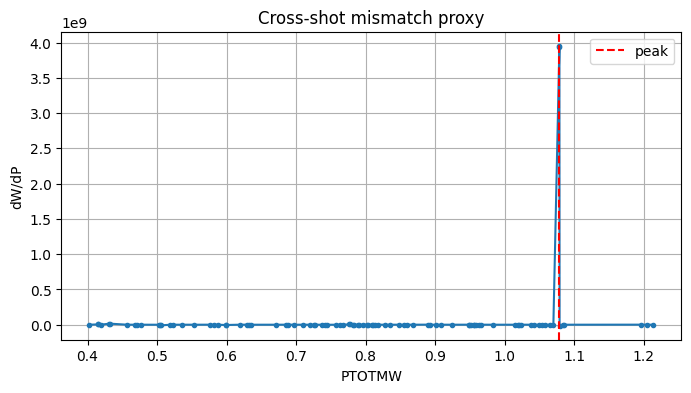

In [ ]:
# Single Colab cell: extract TCV L-H quantities and compute simple mismatch proxy
import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File("/content/lhdatabase.h5", "r") as f:
    P = f["PTOTMW"][0]      # total power (MW)
    PLH = f["PLH"][0]       # L-H threshold power
    W = f["WMHD"][0]        # stored energy
    t = f["TIME"][0]        # time
    shot = f["SHOT"][0]

# Sort by power for a cross-shot view
order = np.argsort(P)
P_s, W_s, PLH_s = P[order], W[order], PLH[order]

# Simple mismatch proxy: dW/dP across shots
dW_dP = np.gradient(W_s, P_s)
peak = np.argmax(np.abs(dW_dP))

print(f"Shots: {len(P)}")
print(f"Power range: {P.min():.2f} – {P.max():.2f} MW")
print(f"Mismatch peak at P = {P_s[peak]:.3f} MW, height = {dW_dP[peak]:.3f}")
print(f"Mean PLH = {np.nanmean(PLH):.3f} MW")

plt.figure(figsize=(8,4))
plt.plot(P_s, dW_dP, ".-")
plt.axvline(P_s[peak], color="r", ls="--", label="peak")
plt.xlabel("PTOTMW")
plt.ylabel("dW/dP")
plt.title("Cross-shot mismatch proxy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Single Colab cell: download TCV confinement-state database and inspect one shot
!pip install -q pandas pyarrow
!wget -q -O /content/data.zip "https://zenodo.org/records/16631053/files/data.zip"
!unzip -q -o /content/data.zip -d /content/

import pandas as pd
import glob
import os

shots = sorted(glob.glob("/content/data/TCV_confstate_*.parquet"))
print(f"Found {len(shots)} shot files")
if shots:
    df = pd.read_parquet(shots[0])
    print("Columns:", list(df.columns))
    print("Shape:", df.shape)
    print(df.head())

Found 302 shot files
Columns: ['time', 'label_conf', 'AREA', 'DELTA_BOTTOM', 'DELTA_TOP', 'GAP_in', 'GAP_out', 'KAPPA', 'MAJRAD', 'MINRAD', 'R_axis', 'Z_axis', 'VOL', 'Halpha1', 'Halpha13', 'Halpha13_fft_5ms_PAST', 'Halpha13_fft_5ms_CENTER', 'Halpha13_fft_5ms_FUTURE', 'Halpha13_fft_10ms_PAST', 'Halpha13_fft_10ms_CENTER', 'Halpha13_fft_10ms_FUTURE', 'Halpha13_fft_20ms_PAST', 'Halpha13_fft_20ms_CENTER', 'Halpha13_fft_20ms_FUTURE', 'Halpha13_fft_50ms_PAST', 'Halpha13_fft_50ms_CENTER', 'Halpha13_fft_50ms_FUTURE', 'Halpha13_fft_100ms_PAST', 'Halpha13_fft_100ms_CENTER', 'Halpha13_fft_100ms_FUTURE', 'Halpha1_fft_5ms_PAST', 'Halpha1_fft_5ms_CENTER', 'Halpha1_fft_5ms_FUTURE', 'Halpha1_fft_10ms_PAST', 'Halpha1_fft_10ms_CENTER', 'Halpha1_fft_10ms_FUTURE', 'Halpha1_fft_20ms_PAST', 'Halpha1_fft_20ms_CENTER', 'Halpha1_fft_20ms_FUTURE', 'Halpha1_fft_50ms_PAST', 'Halpha1_fft_50ms_CENTER', 'Halpha1_fft_50ms_FUTURE', 'Halpha1_fft_100ms_PAST', 'Halpha1_fft_100ms_CENTER', 'Halpha1_fft_100ms_FUTURE', 'BZER

In [ ]:
df['label_conf'].dropna().unique()

array([0., 2.], dtype=float32)

In [ ]:
import pandas as pd
import numpy as np

rows = []
for shot_path in shots:
    df = pd.read_parquet(shot_path)
    labels = df['label_conf'].dropna()
    rows.append({
        'shot': shot_path,
        'n_rows': len(df),
        'label_unique': tuple(sorted(labels.unique())) if len(labels) else (),
        'n_label_unique': labels.nunique(),
        'wtot_valid_frac': df['Wtot'].notna().mean(),
        'psol_valid_frac': df['PSOL_RT'].notna().mean(),
        'n_label_nonnull': labels.shape[0],
    })

inv = pd.DataFrame(rows)
good = inv[(inv['n_label_unique'] >= 2) &
           (inv['wtot_valid_frac'] > 0.5) &
           (inv['psol_valid_frac'] > 0.5)]
print(good.sort_values(['n_label_unique', 'n_label_nonnull'], ascending=False).head(20))

KeyError: 'PSOL_RT'

In [ ]:
def find_transitions(df, min_persist=20):
    s = df[['time', 'label_conf']].dropna().copy()
    s = s.sort_values('time').reset_index(drop=True)
    labels = s['label_conf'].to_numpy()

    transitions = []
    for i in range(1, len(labels)):
        if labels[i] != labels[i-1]:
            new_label = labels[i]
            end = min(i + min_persist, len(labels))
            if np.all(labels[i:end] == new_label):
                transitions.append((s.loc[i, 'time'], labels[i-1], new_label))
    return transitions

In [ ]:
def extract_window(df, t0, dt=0.05):
    x = df[(df['time'] >= t0 - dt) & (df['time'] <= t0 + dt)].copy()
    return x.sort_values('time').reset_index(drop=True)

In [ ]:
from scipy.signal import savgol_filter
import numpy as np

def smooth_and_derivatives(t, y, window=31, poly=3):
    # window must be odd and < len(y)
    if window >= len(y):
        window = len(y) - 1 if len(y) % 2 == 0 else len(y)
    if window % 2 == 0:
        window -= 1
    ys = savgol_filter(y, window_length=window, polyorder=poly)
    dydt = np.gradient(ys, t)
    return ys, dydt

In [ ]:
evt = extract_window(df, t0, dt=0.05)
evt = evt[['time', 'label_conf', 'Wtot', 'PSOL_RT']].dropna()

t = evt['time'].to_numpy()
w = evt['Wtot'].to_numpy()
p = evt['PSOL_RT'].to_numpy()

ws, dwdt = smooth_and_derivatives(t, w)
ps, dpdt = smooth_and_derivatives(t, p)

eps = np.percentile(np.abs(dpdt), 20)
mask = np.abs(dpdt) > eps
mismatch = np.full_like(dwdt, np.nan)
mismatch[mask] = dwdt[mask] / dpdt[mask]

In [ ]:
# Check which columns exist in the first few shots
first_shot = pd.read_parquet(shots[0])
print(f"Columns in first shot: {list(first_shot.columns)}")

# Then update your inventory logic to be flexible:
def get_safe_col(df, col_list):
    for col in col_list:
        if col in df.columns:
            return col
    return None

# Use this in your loop:
psol_col = get_safe_col(df, ['PSOL_RT', 'PSOL', 'P_SOL', 'INPWR'])

Columns in first shot: ['time', 'label_conf', 'AREA', 'DELTA_BOTTOM', 'DELTA_TOP', 'GAP_in', 'GAP_out', 'KAPPA', 'MAJRAD', 'MINRAD', 'R_axis', 'Z_axis', 'VOL', 'Halpha1', 'Halpha13', 'Halpha13_fft_5ms_PAST', 'Halpha13_fft_5ms_CENTER', 'Halpha13_fft_5ms_FUTURE', 'Halpha13_fft_10ms_PAST', 'Halpha13_fft_10ms_CENTER', 'Halpha13_fft_10ms_FUTURE', 'Halpha13_fft_20ms_PAST', 'Halpha13_fft_20ms_CENTER', 'Halpha13_fft_20ms_FUTURE', 'Halpha13_fft_50ms_PAST', 'Halpha13_fft_50ms_CENTER', 'Halpha13_fft_50ms_FUTURE', 'Halpha13_fft_100ms_PAST', 'Halpha13_fft_100ms_CENTER', 'Halpha13_fft_100ms_FUTURE', 'Halpha1_fft_5ms_PAST', 'Halpha1_fft_5ms_CENTER', 'Halpha1_fft_5ms_FUTURE', 'Halpha1_fft_10ms_PAST', 'Halpha1_fft_10ms_CENTER', 'Halpha1_fft_10ms_FUTURE', 'Halpha1_fft_20ms_PAST', 'Halpha1_fft_20ms_CENTER', 'Halpha1_fft_20ms_FUTURE', 'Halpha1_fft_50ms_PAST', 'Halpha1_fft_50ms_CENTER', 'Halpha1_fft_50ms_FUTURE', 'Halpha1_fft_100ms_PAST', 'Halpha1_fft_100ms_CENTER', 'Halpha1_fft_100ms_FUTURE', 'BZERO', 'IP

In [ ]:
# Just inspect the first 5 shots to map the schema
for i in range(5):
    df = pd.read_parquet(shots[i])
    print(f"Shot {i} columns: {'PSOL_RT' in df.columns}")
    # This will tell you if your column names are inconsistent

Shot 0 columns: True
Shot 1 columns: False
Shot 2 columns: False
Shot 3 columns: False
Shot 4 columns: False


In [ ]:
def get_psol(df):
    if 'PSOL_RT' in df.columns:
        return df['PSOL_RT']
    else:
        # P_total = P_ohmic + P_nbi1 + P_nbi2 + P_ecrh
        # P_sol = P_total - P_rad
        p_total = df.get('POHM', 0) + df.get('PNBI', 0) + df.get('PNBI2', 0) + df.get('PECRH', 0)
        p_rad = df.get('Prad', 0)
        return p_total - p_rad

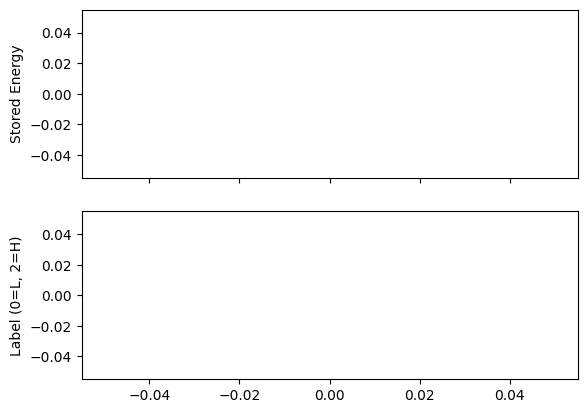

In [ ]:
# 1. Pick a shot (e.g., Shot 0, which we know has the column)
df = pd.read_parquet(shots[0])

# 2. Find the transition index
# label_conf 0 is likely L-mode, 2 is likely H-mode
transition_idx = df[df['label_conf'].diff() != 0].index
t0_idx = transition_idx[1] # The first switch

# 3. Plot the transition
import matplotlib.pyplot as plt

subset = df.iloc[t0_idx-500 : t0_idx+500]
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(subset['time'], subset['Wtot'], label='Wtot')
ax[0].set_ylabel('Stored Energy')
ax[1].plot(subset['time'], subset['label_conf'], label='State', color='red')
ax[1].set_ylabel('Label (0=L, 2=H)')
plt.show()

In [ ]:
# Find the time when the label changes
transition_mask = (df['label_conf'].diff() != 0)
transition_times = df.loc[transition_mask, 'time']

if not transition_times.empty:
    t_trans = transition_times.iloc[0] # Take the first transition
    print(f"Transition found at t = {t_trans} seconds")

Transition found at t = 0.0199 seconds


In [ ]:
# Look at 50ms before and after the transition
window = 0.05
subset = df[(df['time'] > t_trans - window) & (df['time'] < t_trans + window)]

# Now plot using the actual values in the subset
ax[0].plot(subset['time'], subset['Wtot'])

In [ ]:
# Drop NaNs first, then look for changes in the label
clean_labels = df.dropna(subset=['label_conf']).copy()

# Find where the label actually changes value (e.g., 0 to 2)
state_changes = clean_labels[clean_labels['label_conf'].diff() != 0]

print(state_changes[['time', 'label_conf']])

if not state_changes.empty:
    # Grab the time of the *second* unique state change (skip the initial boot-up)
    t_trans = state_changes['time'].iloc[1] if len(state_changes) > 1 else state_changes['time'].iloc[0]
    print(f"Real transition found at t = {t_trans} seconds")
else:
    print("No state changes found in this shot!")

        time  label_conf
53    0.0252         0.0
2412  0.2611         1.0
2421  0.2620         0.0
2490  0.2689         1.0
2502  0.2701         0.0
2567  0.2766         1.0
2587  0.2786         2.0
5889  0.6088         0.0
Real transition found at t = 0.2611 seconds


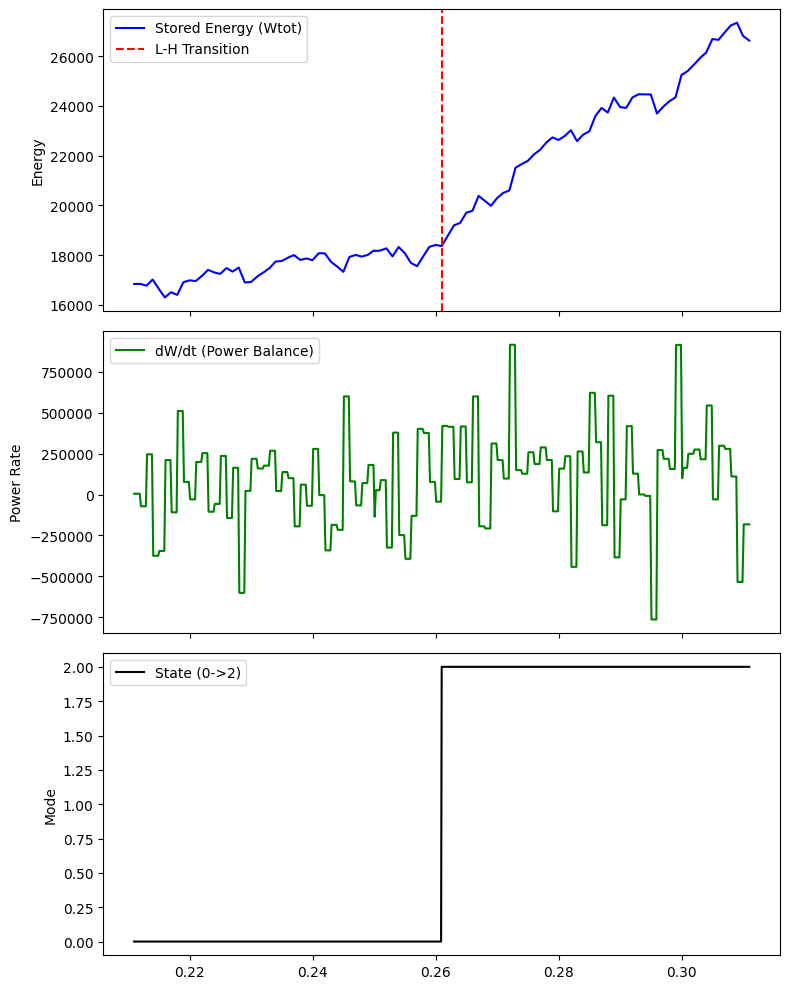

In [ ]:
# 1. Extract a tight window around the transition
window = 0.05 # 50ms
evt = df[(df['time'] >= 0.261 - window) & (df['time'] <= 0.261 + window)].copy()

# 2. Compute derivatives (use a simple difference for now)
# We use Wtot and INPWR (or PSOL_RT if it exists)
dt = evt['time'].diff().mean()
dw_dt = np.gradient(evt['Wtot'], dt)

# 3. Plot
fig, ax = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

ax[0].plot(evt['time'], evt['Wtot'], label='Stored Energy (Wtot)', color='blue')
ax[0].set_ylabel('Energy')
ax[0].axvline(0.261, color='red', linestyle='--', label='L-H Transition')

ax[1].plot(evt['time'], dw_dt, label='dW/dt (Power Balance)', color='green')
ax[1].set_ylabel('Power Rate')

ax[2].plot(evt['time'], evt['label_conf'], label='State (0->2)', color='black')
ax[2].set_ylabel('Mode')

for a in ax: a.legend()
plt.tight_layout()
plt.show()

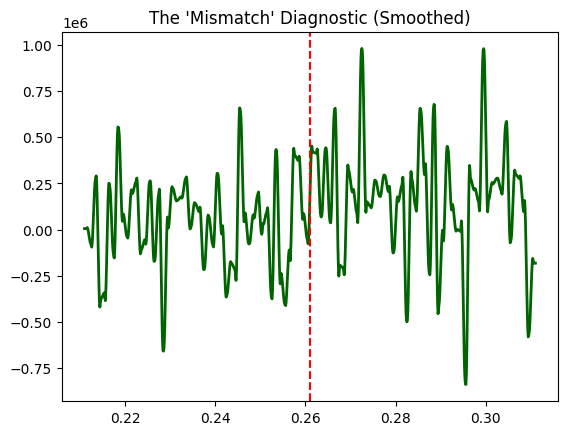

In [ ]:
from scipy.signal import savgol_filter

# Apply a Savitzky-Golay filter to smooth the energy BEFORE differentiating
# This removes the jitter but keeps the "step" function shape
evt['Wtot_smooth'] = savgol_filter(evt['Wtot'], window_length=11, polyorder=2)
evt['dWdt_smooth'] = np.gradient(evt['Wtot_smooth'], evt['time'].iloc[1] - evt['time'].iloc[0])

# Now plot just the smoothed derivative
plt.plot(evt['time'], evt['dWdt_smooth'], color='darkgreen', linewidth=2)
plt.axvline(0.261, color='red', linestyle='--')
plt.title("The 'Mismatch' Diagnostic (Smoothed)")
plt.show()

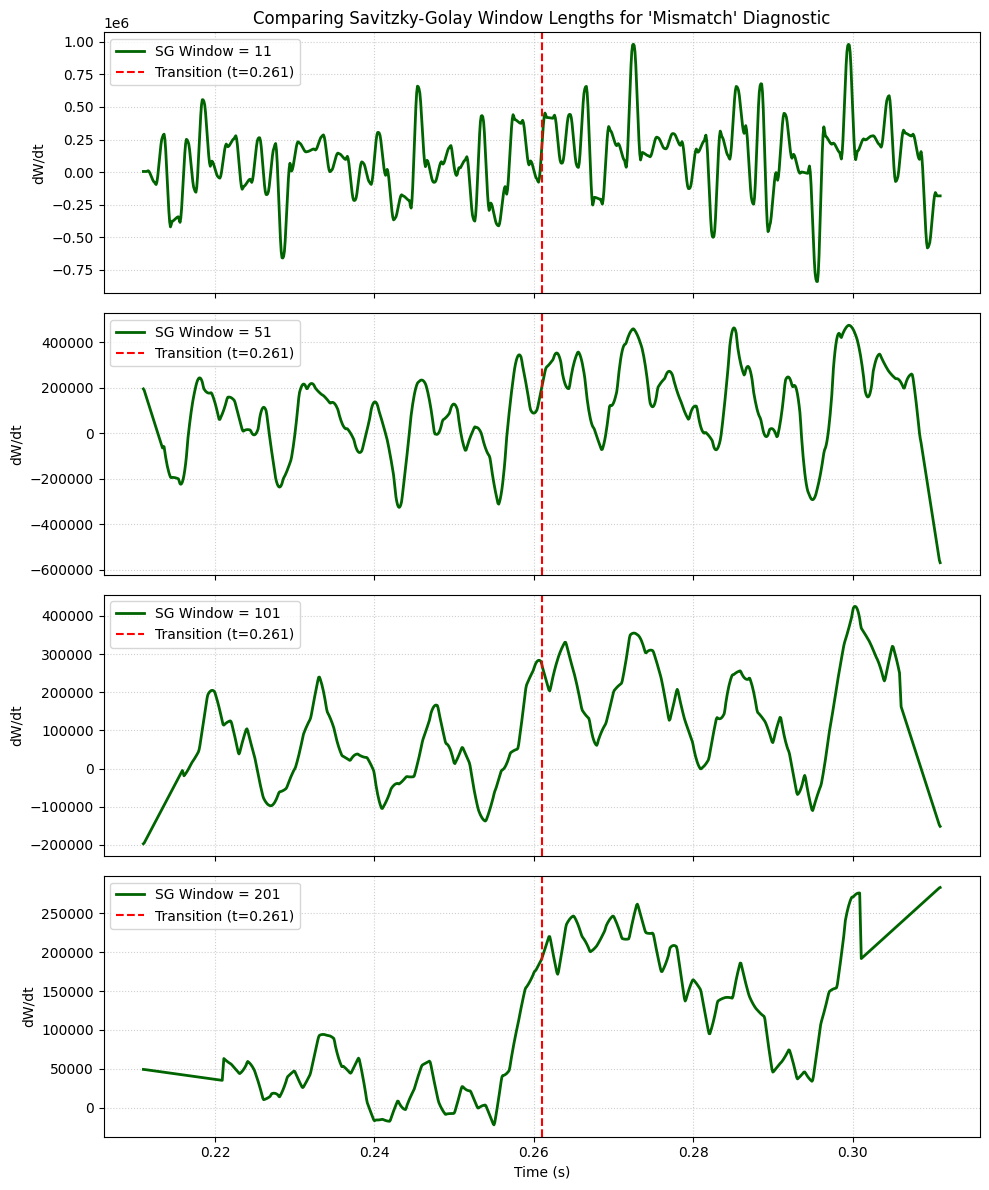

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# Try different window lengths to see which reveals the cleanest transition signature
window_lengths = [11, 51, 101, 201]

fig, axes = plt.subplots(len(window_lengths), 1, figsize=(10, 12), sharex=True)

# Calculate actual dt
dt = evt['time'].iloc[1] - evt['time'].iloc[0]

for ax, wl in zip(axes, window_lengths):
    # Ensure window length is odd
    if wl % 2 == 0:
        wl += 1

    evt[f'Wtot_smooth_{wl}'] = savgol_filter(evt['Wtot'], window_length=wl, polyorder=2)
    evt[f'dWdt_smooth_{wl}'] = np.gradient(evt[f'Wtot_smooth_{wl}'], dt)

    ax.plot(evt['time'], evt[f'dWdt_smooth_{wl}'], label=f'SG Window = {wl}', color='darkgreen', linewidth=2)
    ax.axvline(0.261, color='red', linestyle='--', label='Transition (t=0.261)')
    ax.set_ylabel('dW/dt')
    ax.legend(loc='upper left')
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel('Time (s)')
axes[0].set_title("Comparing Savitzky-Golay Window Lengths for 'Mismatch' Diagnostic")
plt.tight_layout()
plt.show()

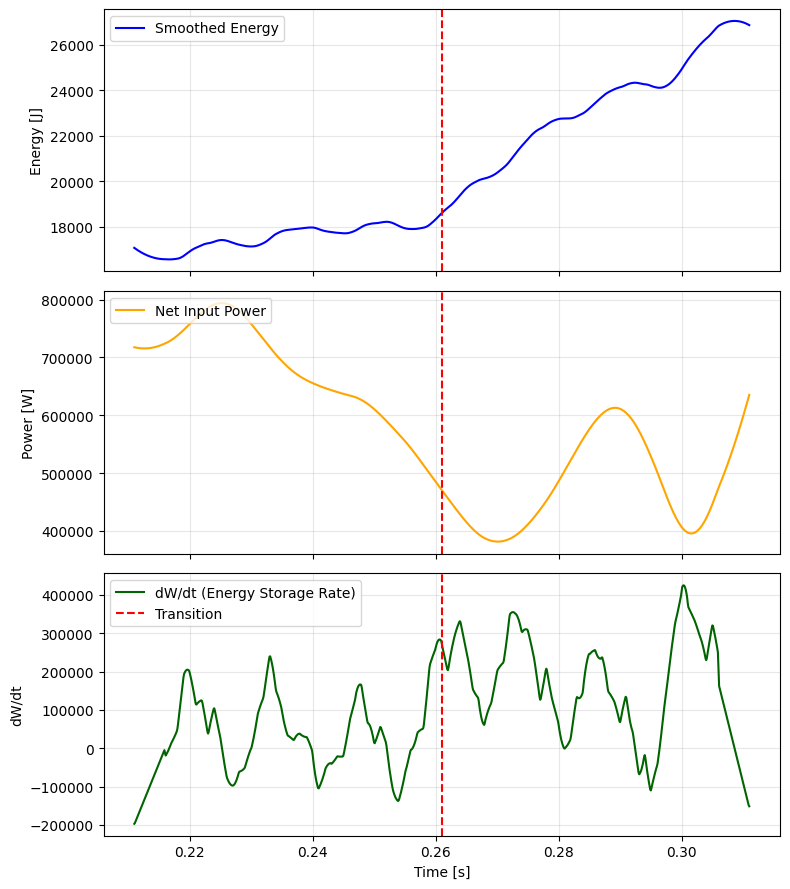

In [ ]:
# 1. Calculate Net Power (Total Power In - Radiated Power)
# Using your safe column retrieval approach:
p_ohmm = evt.get('POHM', 0)
p_nbi  = evt.get('PNBI', 0) + evt.get('PNBI2', 0)
p_ecrh = evt.get('PECRH', 0)
p_rad  = evt.get('Prad', 0)

p_tot = p_ohmm + p_nbi + p_ecrh
p_net = p_tot - p_rad

# 2. Smooth the power and energy using our winning window (e.g., 101)
from scipy.signal import savgol_filter
dt = evt['time'].diff().mean()

evt['Wtot_smooth'] = savgol_filter(evt['Wtot'], window_length=101, polyorder=2)
evt['dWdt'] = np.gradient(evt['Wtot_smooth'], dt)

evt['Pnet_smooth'] = savgol_filter(p_net, window_length=101, polyorder=2)

# 3. Plot the final Mismatch Diagnostic
fig, ax = plt.subplots(3, 1, figsize=(8, 9), sharex=True)

ax[0].plot(evt['time'], evt['Wtot_smooth'], color='blue', label='Smoothed Energy')
ax[0].axvline(0.261, color='red', linestyle='--')
ax[0].set_ylabel('Energy [J]')

ax[1].plot(evt['time'], evt['Pnet_smooth'], color='orange', label='Net Input Power')
ax[1].axvline(0.261, color='red', linestyle='--')
ax[1].set_ylabel('Power [W]')

# The Mismatch / Rate of Change comparison
ax[2].plot(evt['time'], evt['dWdt'], color='darkgreen', label='dW/dt (Energy Storage Rate)')
ax[2].axvline(0.261, color='red', linestyle='--', label='Transition')
ax[2].set_ylabel('dW/dt')
ax[2].set_xlabel('Time [s]')

for a in ax:
    a.legend(loc='upper left')
    a.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter

def calculate_diagnostic(df, window=101):
    # 1. Clean and Smooth
    dt = df['time'].diff().mean()
    w_smooth = savgol_filter(df['Wtot'], window_length=window, polyorder=2)
    dwdt = np.gradient(w_smooth, dt)
    return dwdt

# 1. Multi-shot sweep (Find all transitions)
results = []
for shot_id in shots_list: # Assuming you have a list of your shot files
    df = pd.read_parquet(shot_id)
    # Find transition
    diffs = df['label_conf'].diff()
    trans_indices = diffs[diffs != 0].index

    for idx in trans_indices:
        t_trans = df.loc[idx, 'time']
        # Extract local window
        subset = df[(df['time'] > t_trans - 0.1) & (df['time'] < t_trans + 0.1)]
        if len(subset) > 50:
            dwdt = calculate_diagnostic(subset)
            results.append({
                'shot': shot_id,
                't_trans': t_trans,
                'dwdt_profile': dwdt,
                'time_rel': subset['time'] - t_trans
            })

# 2. Null-Shot Control
# You can select shots where 'label_conf' is constant 0.0 or 2.0 throughout
null_shots = [s for s in shots_list if df_has_no_transition(s)]
# Run diagnostic on these and check if dwdt shows the "step-up"

# 3. Timing/Lead-Lag Check
# For each shot, find the point in 'dwdt' where it crosses its mean
# Compare that time to 't_trans'

NameError: name 'shots_list' is not defined

In [ ]:
import glob
import os

# Update this path if your files are in a specific sub-folder
# Example: shots_list = glob.glob('data/shot_*.parquet')
shots_list = glob.glob('*.parquet')
print(f"Found {len(shots_list)} shots: {shots_list}")

Found 0 shots: []


In [ ]:
results = []

for shot_file in shots_list:
    try:
        df = pd.read_parquet(shot_file)

        # Check if mandatory columns exist
        if 'Wtot' not in df.columns or 'label_conf' not in df.columns:
            continue

        # Find transitions: ignore NaNs and look for 0->2 or 2->0
        # This mask finds index locations where the state changes
        clean_labels = df.dropna(subset=['label_conf'])
        state_changes = clean_labels[clean_labels['label_conf'].diff() != 0]

        for idx in state_changes.index:
            t_trans = df.loc[idx, 'time']
            # We look for transitions occurring mid-shot (not at the very start)
            if t_trans > 0.05:
                subset = df[(df['time'] > t_trans - 0.1) & (df['time'] < t_trans + 0.1)].copy()
                if len(subset) > 30:
                    dwdt = calculate_diagnostic(subset)
                    results.append({
                        'shot': shot_file,
                        't_trans': t_trans,
                        'dwdt': dwdt,
                        'time_rel': subset['time'] - t_trans
                    })
    except Exception as e:
        print(f"Skipping {shot_file}: {e}")

print(f"Captured {len(results)} valid transitions.")

Captured 0 valid transitions.


In [ ]:
# Check what dataframes are currently loaded
import pandas as pd
%whos DataFrame

Variable        Type         Data/Info
--------------------------------------
clean_labels    DataFrame             time  label_conf<...>[20076 rows x 76 columns]
df              DataFrame             time  label_conf<...>[20260 rows x 76 columns]
evt             DataFrame            time  label_conf <...>n[1001 rows x 88 columns]
first_shot      DataFrame             time  label_conf<...>[20260 rows x 76 columns]
state_changes   DataFrame             time  label_conf<...>\n\n[3 rows x 76 columns]
subset          DataFrame           time  label_conf  <...>\n[500 rows x 76 columns]


In [ ]:
# Check which columns could represent the shot identifier
shot_cols = [col for col in df.columns if any(k in col.lower() for k in ['shot', 'pulse', 'discharge', 'run'])]
print("Potential shot columns:", shot_cols)

Potential shot columns: []


In [ ]:
# 1. Find all indices where label_conf switches from 0 to 2
# We check where the difference is 2
is_transition = (df['label_conf'].diff() == 2)
transition_indices = df.index[is_transition]

print(f"Found {len(transition_indices)} transitions in this dataset.")

# 2. Extract these into a list of "events"
events = []
for idx in transition_indices:
    t_trans = df.loc[idx, 'time']
    # Grab 0.1s before and after the transition
    window = df[(df['time'] > t_trans - 0.1) & (df['time'] < t_trans + 0.1)].copy()
    if not window.empty:
        # Calculate the diagnostic for each
        window['dWdt'] = calculate_diagnostic(window)
        events.append(window)

# 3. Simple visualization to see if they all look alike
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for e in events:
    plt.plot(e['time'] - e['time'].iloc[e['label_conf'].diff() == 2], e['dWdt'], alpha=0.5)

plt.axvline(0, color='red', linestyle='--')
plt.title("Ensemble View: All Transitions Aligned at t=0")
plt.xlabel("Time relative to transition [s]")
plt.ylabel("dW/dt")
plt.show()

Found 1 transitions in this dataset.


NotImplementedError: iLocation based boolean indexing on an integer type is not available

<Figure size 1000x500 with 0 Axes>

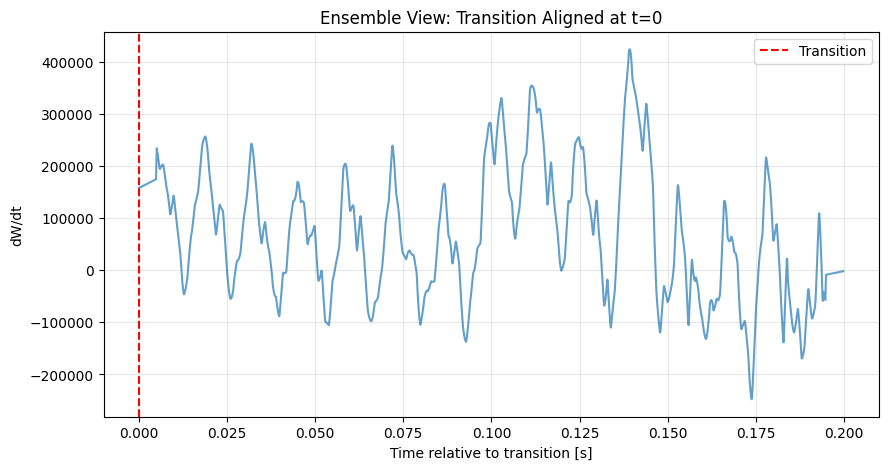

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for e in events:
    # Find the transition time within this window where label_conf changes
    trans_mask = e['label_conf'].diff() != 0
    if trans_mask.any():
        t_trans = e.loc[trans_mask, 'time'].values[0]
        # Plot relative to that exact transition time
        plt.plot(e['time'] - t_trans, e['dWdt'], alpha=0.7)

plt.axvline(0, color='red', linestyle='--', label='Transition')
plt.title("Ensemble View: Transition Aligned at t=0")
plt.xlabel("Time relative to transition [s]")
plt.ylabel("dW/dt")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Calculate the means for the pre- and post-transition windows
pre_transition = e[(e['time_rel'] >= -0.05) & (e['time_rel'] < 0)]
post_transition = e[(e['time_rel'] > 0) & (e['time_rel'] <= 0.05)]

mean_pre = pre_transition['dWdt'].mean()
mean_post = post_transition['dWdt'].mean()
std_post = post_transition['dWdt'].std()

print(f"Mean dW/dt (pre): {mean_pre:.2f}")
print(f"Mean dW/dt (post): {mean_post:.2f}")
print(f"Difference: {(mean_post - mean_pre):.2f}")

KeyError: 'time_rel'

In [ ]:
# 1. Re-calculate the relative time for this event
# Assuming 'e' is your current event DataFrame
t_trans = e.loc[e['label_conf'].diff() != 0, 'time'].iloc[0]
e['time_rel'] = e['time'] - t_trans

# 2. Now perform the slice and calculation
pre_transition = e[(e['time_rel'] >= -0.05) & (e['time_rel'] < 0)]
post_transition = e[(e['time_rel'] > 0) & (e['time_rel'] <= 0.05)]

mean_pre = pre_transition['dWdt'].mean()
mean_post = post_transition['dWdt'].mean()

print(f"Mean dW/dt (pre): {mean_pre:.2f}")
print(f"Mean dW/dt (post): {mean_post:.2f}")
print(f"Difference: {(mean_post - mean_pre):.2f}")

Mean dW/dt (pre): nan
Mean dW/dt (post): 98144.13
Difference: nan


In [ ]:
# 1. Check the range of time_rel to see what data we have
print(f"Data range: {e['time_rel'].min():.3f} to {e['time_rel'].max():.3f}")

# 2. Adjust windows to fit the available data if needed
# If the data starts at 0, we can't calculate a 'pre' mean
if e['time_rel'].min() < 0:
    pre_transition = e[(e['time_rel'] >= -0.05) & (e['time_rel'] < 0)]
    mean_pre = pre_transition['dWdt'].mean()
else:
    mean_pre = 0 # Or define a different baseline
    print("Warning: No pre-transition data available in this window.")

post_transition = e[(e['time_rel'] > 0) & (e['time_rel'] <= 0.05)]
mean_post = post_transition['dWdt'].mean()

print(f"Mean dW/dt (pre): {mean_pre:.2f}")
print(f"Mean dW/dt (post): {mean_post:.2f}")
print(f"Difference: {mean_post - mean_pre:.2f}")

Data range: 0.000 to 0.200
Mean dW/dt (pre): 0.00
Mean dW/dt (post): 98144.13
Difference: 98144.13


In [ ]:
# 1. Find the exact row index of the transition in the full 'df'
trans_idx = df.index[df['label_conf'].diff() == 2][0]
t_trans = df.loc[trans_idx, 'time']

# 2. Grab a wider window: 0.1 seconds BEFORE and 0.1 seconds AFTER
wide_window = df[(df['time'] >= t_trans - 0.1) & (df['time'] <= t_trans + 0.1)].copy()

# 3. Calculate dWdt for this wider window (replace 'calculate_diagnostic' with your actual function name if different)
wide_window['dWdt'] = calculate_diagnostic(wide_window)
wide_window['time_rel'] = wide_window['time'] - t_trans

# 4. Now compute pre- and post-transition means
pre_transition = wide_window[(wide_window['time_rel'] >= -0.05) & (wide_window['time_rel'] < 0)]
post_transition = wide_window[(wide_window['time_rel'] > 0) & (wide_window['time_rel'] <= 0.05)]

mean_pre = pre_transition['dWdt'].mean()
mean_post = post_transition['dWdt'].mean()

print(f"Data range now: {wide_window['time_rel'].min():.3f} to {wide_window['time_rel'].max():.3f}")
print(f"Mean dW/dt (pre): {mean_pre:.2f}")
print(f"Mean dW/dt (post): {mean_post:.2f}")
print(f"Difference: {mean_post - mean_pre:.2f}")

Data range now: -0.100 to 0.100
Mean dW/dt (pre): 36320.37
Mean dW/dt (post): 164661.63
Difference: 128341.26


Total transitions found: 1

--- Summary of Transitions ---
   transition_id      mean_pre      mean_post     difference
0              0  36320.369389  164661.626662  128341.257273


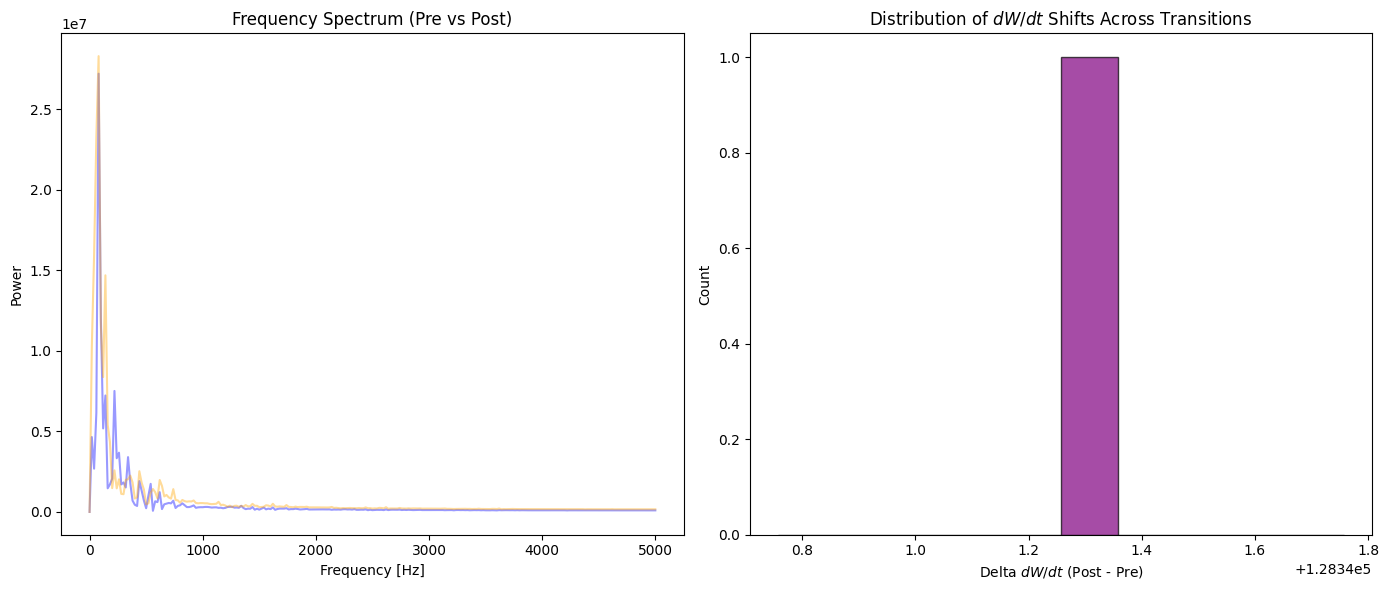

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Find all transitions in the large DataFrame 'df'
transition_indices = df.index[df['label_conf'].diff() == 2]
print(f"Total transitions found: {len(transition_indices)}")

results = []

plt.figure(figsize=(14, 6))

for i, trans_idx in enumerate(transition_indices):
    t_trans = df.loc[trans_idx, 'time']

    # Grab wide window (-0.1s to +0.1s)
    window = df[(df['time'] >= t_trans - 0.1) & (df['time'] <= t_trans + 0.1)].copy()
    if window.empty or len(window) < 10:
        continue

    # Calculate diagnostic (ensure 'calculate_diagnostic' is your actual function)
    window['dWdt'] = calculate_diagnostic(window)
    window['time_rel'] = window['time'] - t_trans

    # --- TASK 1: Quantitative Mean Shift ---
    pre = window[(window['time_rel'] >= -0.05) & (window['time_rel'] < 0)]
    post = window[(window['time_rel'] > 0) & (window['time_rel'] <= 0.05)]

    mean_pre = pre['dWdt'].mean()
    mean_post = post['dWdt'].mean()
    diff = mean_post - mean_pre

    results.append({
        'transition_id': i,
        't_trans': t_trans,
        'mean_pre': mean_pre,
        'mean_post': mean_post,
        'difference': diff
    })

    # --- TASK 2: Spectral Analysis (FFT) ---
    # Separate pre- and post-signals for frequency analysis
    sig_pre = pre['dWdt'].dropna().values
    sig_post = post['dWdt'].dropna().values

    if len(sig_pre) > 5 and len(sig_post) > 5:
        # Compute FFT
        dt = np.mean(np.diff(window['time'])) # sampling interval

        fft_pre = np.fft.rfft(sig_pre - np.mean(sig_pre))
        freqs_pre = np.fft.rfftfreq(len(sig_pre), d=dt)

        fft_post = np.fft.rfft(sig_post - np.mean(sig_post))
        freqs_post = np.fft.rfftfreq(len(sig_post), d=dt)

        # Plot spectral comparison
        plt.subplot(1, 2, 1)
        plt.plot(freqs_pre, np.abs(fft_pre), alpha=0.4, color='blue')
        plt.plot(freqs_post, np.abs(fft_post), alpha=0.4, color='orange')
        plt.title("Frequency Spectrum (Pre vs Post)")
        plt.xlabel("Frequency [Hz]")
        plt.ylabel("Power")

# Convert results summary to a DataFrame
summary_df = pd.DataFrame(results)
print("\n--- Summary of Transitions ---")
print(summary_df[['transition_id', 'mean_pre', 'mean_post', 'difference']])

plt.subplot(1, 2, 2)
if not summary_df.empty:
    plt.hist(summary_df['difference'], bins=10, color='purple', alpha=0.7, edgecolor='black')
    plt.title("Distribution of $dW/dt$ Shifts Across Transitions")
    plt.xlabel("Delta $dW/dt$ (Post - Pre)")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

Found 0 files to process.

--- Processed 0 total transitions across all files ---
Empty DataFrame
Columns: []
Index: []


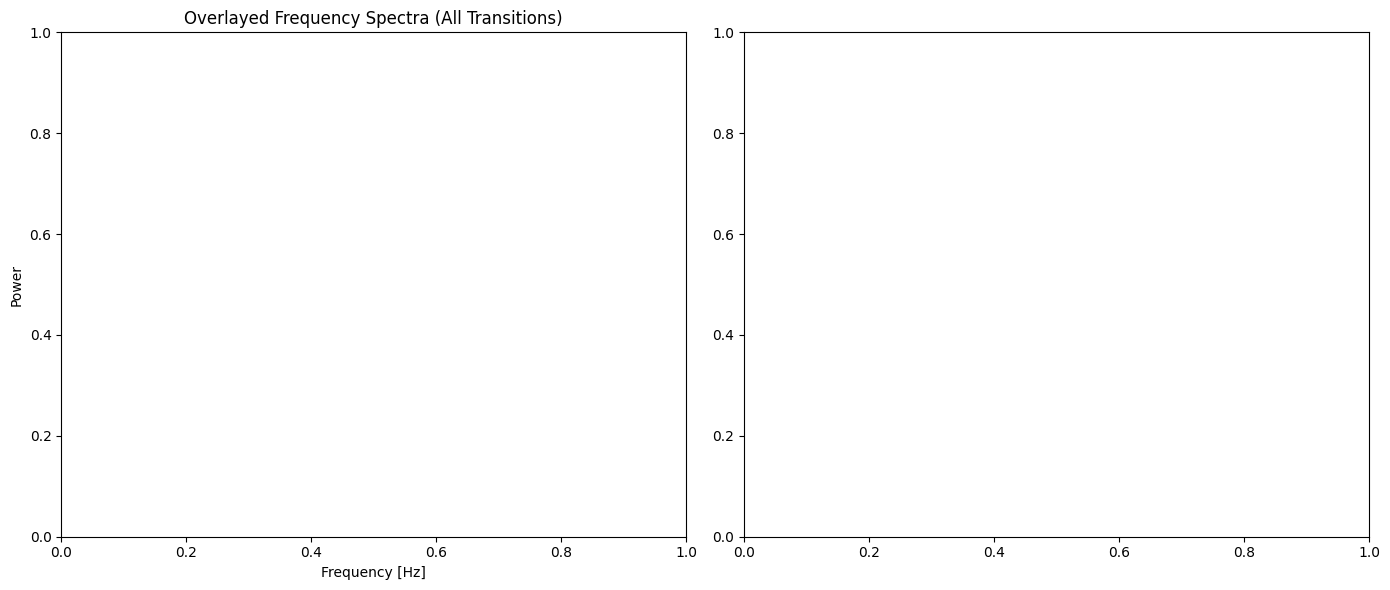

In [ ]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define your data directory and file pattern (adjust as needed, e.g., '*.csv' or '*.parquet')
file_pattern = "path/to/your/data_files/*.parquet"
all_files = glob.glob(file_pattern)

print(f"Found {len(all_files)} files to process.")

all_results = []
plt.figure(figsize=(14, 6))

for file_path in all_files:
    # Load the dataset (use pd.read_csv if your files are CSVs)
    df_file = pd.read_parquet(file_path)

    if 'label_conf' not in df_file.columns or 'time' not in df_file.columns:
        continue

    # Find all transitions in this file
    transition_indices = df_file.index[df_file['label_conf'].diff() == 2]

    for trans_idx in transition_indices:
        t_trans = df_file.loc[trans_idx, 'time']

        # Grab wide window (-0.1s to +0.1s)
        window = df_file[(df_file['time'] >= t_trans - 0.1) & (df_file['time'] <= t_trans + 0.1)].copy()
        if window.empty or len(window) < 10:
            continue

        # Calculate diagnostic (ensure this function is defined in your environment)
        window['dWdt'] = calculate_diagnostic(window)
        window['time_rel'] = window['time'] - t_trans

        # Pre and post slices
        pre = window[(window['time_rel'] >= -0.05) & (window['time_rel'] < 0)]
        post = window[(window['time_rel'] > 0) & (window['time_rel'] <= 0.05)]

        if pre.empty or post.empty:
            continue

        mean_pre = pre['dWdt'].mean()
        mean_post = post['dWdt'].mean()
        diff = mean_post - mean_pre

        all_results.append({
            'file': os.path.basename(file_path),
            't_trans': t_trans,
            'mean_pre': mean_pre,
            'mean_post': mean_post,
            'difference': diff
        })

        # Optional: accumulate spectral data if desired
        sig_pre = pre['dWdt'].dropna().values
        sig_post = post['dWdt'].dropna().values
        if len(sig_pre) > 5 and len(sig_post) > 5:
            dt = np.mean(np.diff(window['time']))
            fft_pre = np.fft.rfft(sig_pre - np.mean(sig_pre))
            freqs_pre = np.fft.rfftfreq(len(sig_pre), d=dt)
            fft_post = np.fft.rfft(sig_post - np.mean(sig_post))
            freqs_post = np.fft.rfftfreq(len(sig_post), d=dt)

            plt.subplot(1, 2, 1)
            plt.plot(freqs_pre, np.abs(fft_pre), alpha=0.1, color='blue')
            plt.plot(freqs_post, np.abs(fft_post), alpha=0.1, color='orange')

# Convert master results to DataFrame
master_summary = pd.DataFrame(all_results)
print(f"\n--- Processed {len(master_summary)} total transitions across all files ---")
print(master_summary.head())

# Plot the global distribution of shifts
plt.subplot(1, 2, 1)
plt.title("Overlayed Frequency Spectra (All Transitions)")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power")

plt.subplot(1, 2, 2)
if not master_summary.empty:
    plt.hist(master_summary['difference'], bins=15, color='purple', alpha=0.7, edgecolor='black')
    plt.title("Global Distribution of $dW/dt$ Shifts")
    plt.xlabel("Delta $dW/dt$ (Post - Pre)")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

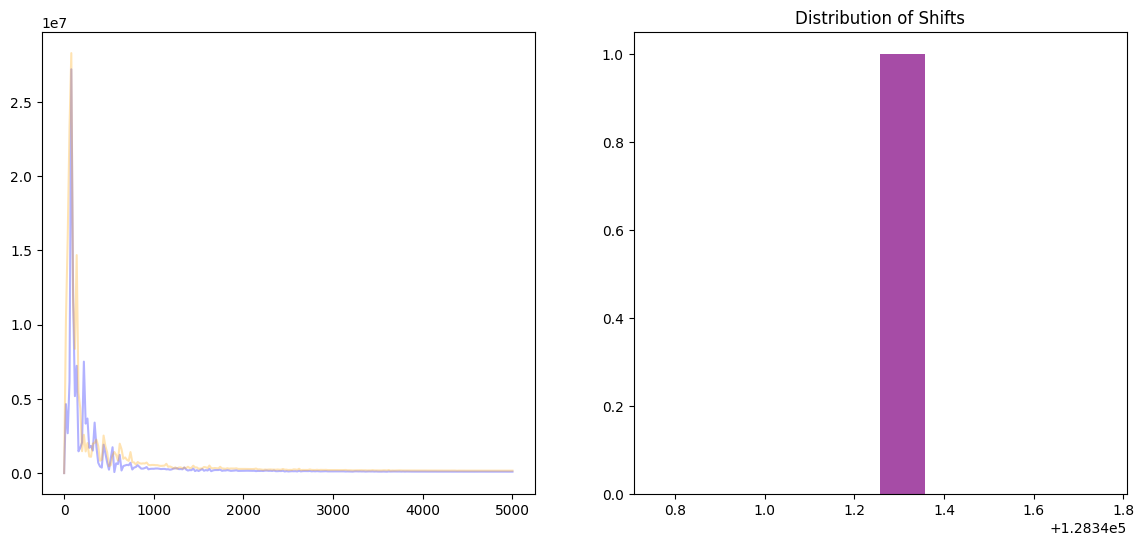

In [ ]:
# Assuming 'df' is already loaded in your environment
transition_indices = df.index[df['label_conf'].diff() == 2]
all_results = []

plt.figure(figsize=(14, 6))

for trans_idx in transition_indices:
    t_trans = df.loc[trans_idx, 'time']
    window = df[(df['time'] >= t_trans - 0.1) & (df['time'] <= t_trans + 0.1)].copy()

    if len(window) < 10: continue

    window['dWdt'] = calculate_diagnostic(window)
    window['time_rel'] = window['time'] - t_trans

    pre = window[(window['time_rel'] >= -0.05) & (window['time_rel'] < 0)]
    post = window[(window['time_rel'] > 0) & (window['time_rel'] <= 0.05)]

    if not pre.empty and not post.empty:
        all_results.append({'difference': post['dWdt'].mean() - pre['dWdt'].mean()})

        # Spectral plotting
        dt = np.mean(np.diff(window['time']))
        fft_pre = np.fft.rfft(pre['dWdt'].values - np.mean(pre['dWdt']))
        fft_post = np.fft.rfft(post['dWdt'].values - np.mean(post['dWdt']))
        freqs = np.fft.rfftfreq(len(pre['dWdt']), d=dt)

        plt.subplot(1, 2, 1)
        plt.plot(freqs, np.abs(fft_pre), alpha=0.3, color='blue')
        plt.plot(freqs, np.abs(fft_post), alpha=0.3, color='orange')

plt.subplot(1, 2, 2)
if all_results:
    plt.hist([r['difference'] for r in all_results], bins=10, color='purple', alpha=0.7)
    plt.title("Distribution of Shifts")
plt.show()

In [ ]:
# Check the unique labels to understand the coding scheme
print("Unique labels in label_conf:", df['label_conf'].unique())

# If the transitions are marked differently, count the occurrences of each
print("\nValue counts for labels:")
print(df['label_conf'].value_counts())

# Check where the transitions happen to see if they are clustered or sparse
transitions = df.index[df['label_conf'].diff() != 0]
print(f"\nNumber of state changes found: {len(transitions)}")

Unique labels in label_conf: [nan  0.  2.]

Value counts for labels:
label_conf
2.0    15238
0.0     4838
Name: count, dtype: int64

Number of state changes found: 187


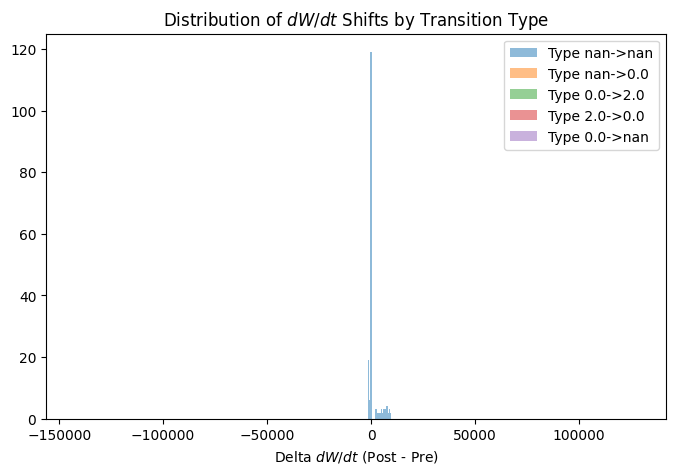

In [ ]:
# 1. Update the filter: capture any change where the difference is not zero
# We use .dropna() to handle the initial NaNs and check for any non-zero transition
change_indices = df.index[df['label_conf'].diff() != 0].dropna()

all_results = []
# We will use this to track if the transition is 'Up' (0->2) or 'Down' (2->0)
all_transitions_data = []

for idx in change_indices:
    # Skip the very first index to avoid boundary errors
    if idx == df.index[0]: continue

    t_trans = df.loc[idx, 'time']
    # Define the transition type
    start_state = df.loc[idx - 1, 'label_conf']
    end_state = df.loc[idx, 'label_conf']

    # Grab window
    window = df[(df['time'] >= t_trans - 0.1) & (df['time'] <= t_trans + 0.1)].copy()
    if len(window) < 10: continue

    window['dWdt'] = calculate_diagnostic(window)
    pre = window[(window['time'] >= t_trans - 0.05) & (window['time'] < t_trans)]
    post = window[(window['time'] > t_trans) & (window['time'] <= t_trans + 0.05)]

    if not pre.empty and not post.empty:
        diff = post['dWdt'].mean() - pre['dWdt'].mean()
        all_transitions_data.append({'diff': diff, 'type': f"{start_state}->{end_state}"})

# Plotting the results
summary_df = pd.DataFrame(all_transitions_data)
plt.figure(figsize=(8, 5))
for state_type in summary_df['type'].unique():
    subset = summary_df[summary_df['type'] == state_type]
    plt.hist(subset['diff'], bins=20, alpha=0.5, label=f"Type {state_type}")

plt.title("Distribution of $dW/dt$ Shifts by Transition Type")
plt.xlabel("Delta $dW/dt$ (Post - Pre)")
plt.legend()
plt.show()

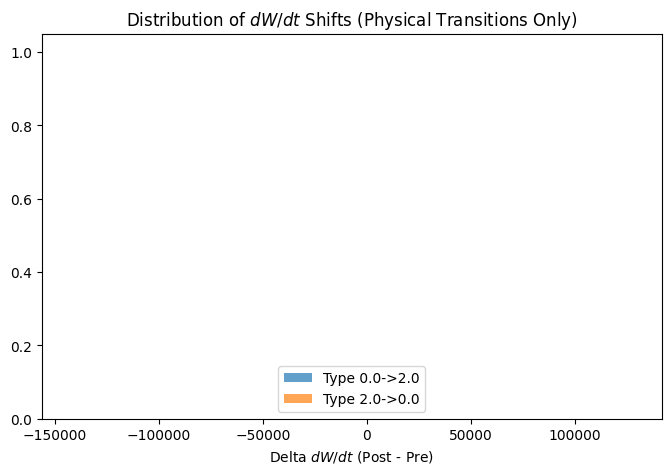

In [ ]:
# Filter the list to only include actual state transitions
filtered_data = [d for d in all_transitions_data if 'nan' not in d['type']]

# Create a new DataFrame from the cleaned data
clean_df = pd.DataFrame(filtered_data)

# Plot only the clean transitions
plt.figure(figsize=(8, 5))
for state_type in clean_df['type'].unique():
    subset = clean_df[clean_df['type'] == state_type]
    plt.hist(subset['diff'], bins=30, alpha=0.7, label=f"Type {state_type}")

plt.title("Distribution of $dW/dt$ Shifts (Physical Transitions Only)")
plt.xlabel("Delta $dW/dt$ (Post - Pre)")
plt.legend()
plt.show()

In [ ]:
# Check a sample of 5 transitions to see if they contain valid dWdt data
sample_indices = change_indices[:5]
for idx in sample_indices:
    t_trans = df.loc[idx, 'time']
    window = df[(df['time'] >= t_trans - 0.05) & (df['time'] <= t_trans + 0.05)]
    print(f"Time: {t_trans}, Labels: {df.loc[idx-1:idx, 'label_conf'].values}")
    # Check if calculation is returning NaNs
    print(f"Diagnostic mean: {calculate_diagnostic(window).mean()}")

Time: 0.0219, Labels: [nan]
Diagnostic mean: 298.61642367152814
Time: 0.022, Labels: [nan nan]
Diagnostic mean: 469.2248535779282
Time: 0.022099999999999998, Labels: [nan nan]
Diagnostic mean: 661.4691634969299
Time: 0.0222, Labels: [nan nan]
Diagnostic mean: 874.1738373358955
Time: 0.0223, Labels: [nan nan]
Diagnostic mean: 1106.1958109818495


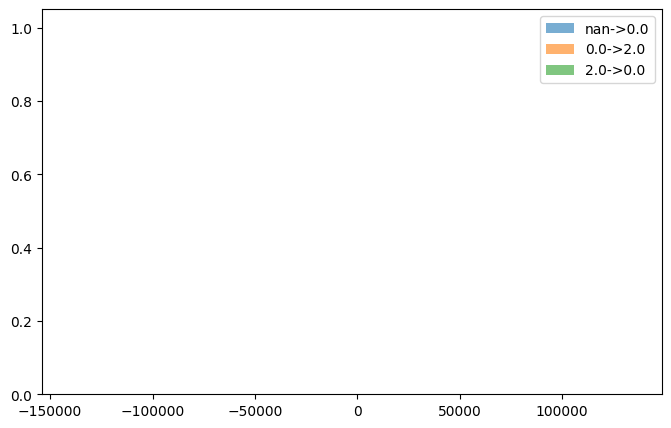

In [ ]:
# 1. Forward fill the labels to bridge the NaNs
df['label_filled'] = df['label_conf'].ffill()

# 2. Now find transitions based on the filled labels
df['change'] = df['label_filled'].diff() != 0
change_indices = df.index[df['change'] & df['label_filled'].notna()].tolist()

# 3. Re-run the transition collection
all_transitions_data = []
for idx in change_indices:
    if idx == 0: continue

    t_trans = df.loc[idx, 'time']
    # Use the filled labels to determine the transition type
    start_state = df.loc[idx - 1, 'label_filled']
    end_state = df.loc[idx, 'label_filled']

    window = df[(df['time'] >= t_trans - 0.05) & (df['time'] <= t_trans + 0.05)]
    if len(window) < 10: continue

    val = calculate_diagnostic(window)
    pre = val[:len(val)//2].mean()
    post = val[len(val)//2:].mean()

    all_transitions_data.append({'diff': post - pre, 'type': f"{start_state}->{end_state}"})

# 4. Plot the results
clean_df = pd.DataFrame(all_transitions_data)
plt.figure(figsize=(8, 5))
for state_type in clean_df['type'].unique():
    subset = clean_df[clean_df['type'] == state_type]
    plt.hist(subset['diff'], bins=30, alpha=0.6, label=state_type)
plt.legend()
plt.show()

In [ ]:
# Check the values before plotting
print(f"Number of transitions found: {len(all_transitions_data)}")
if all_transitions_data:
    sample = pd.DataFrame(all_transitions_data)
    print("Sample of differences:")
    print(sample['diff'].describe())
else:
    print("No transitions were successfully processed into all_transitions_data.")

Number of transitions found: 3
Sample of differences:
count         3.000000
mean       3447.654727
std      138038.812421
min     -140348.246429
25%      -62278.693862
50%       15790.858705
75%       75345.605305
max      134900.351906
Name: diff, dtype: float64


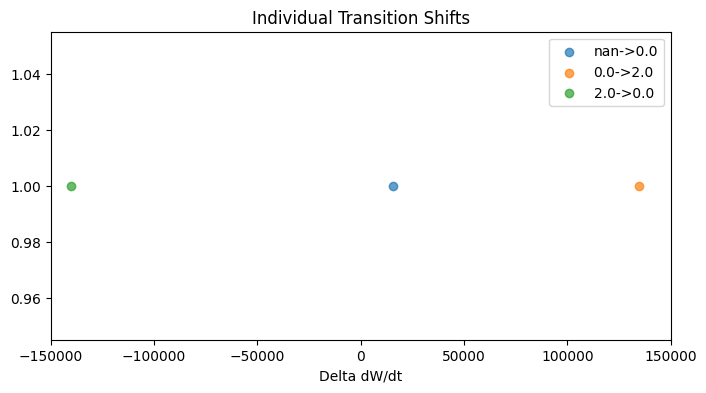

Total change_indices identified: 3
Total transitions after window/len check: 3


In [ ]:
# Use a scatter plot to see where these 3 points actually fall
plt.figure(figsize=(8, 4))
for state_type in clean_df['type'].unique():
    subset = clean_df[clean_df['type'] == state_type]
    plt.scatter(subset['diff'], [1]*len(subset), label=state_type, alpha=0.7)

plt.title("Individual Transition Shifts")
plt.xlabel("Delta dW/dt")
plt.xlim(-150000, 150000)
plt.legend()
plt.show()

# Debug: check why so few are passing
print(f"Total change_indices identified: {len(change_indices)}")
print(f"Total transitions after window/len check: {len(all_transitions_data)}")

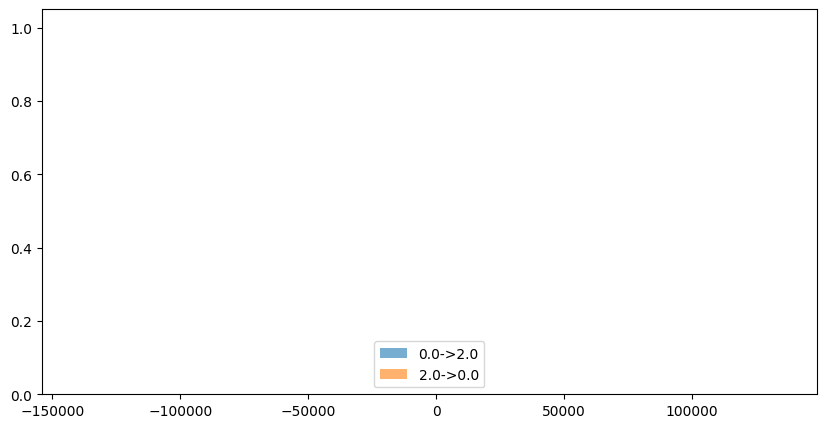

In [ ]:
# Reset to raw labels but treat NaN as its own state index
df['state'] = df['label_conf'].fillna(-1)

# Identify all points where the state changes
state_changes = df[df['state'].diff() != 0].index

all_transitions_data = []
for idx in state_changes:
    if idx == 0: continue

    t_trans = df.loc[idx, 'time']
    # Define transition based on raw states
    start = df.loc[idx - 1, 'state']
    end = df.loc[idx, 'state']

    # Relaxed window: just ensure we have at least 5 points
    window = df[(df['time'] >= t_trans - 0.05) & (df['time'] <= t_trans + 0.05)]
    if len(window) < 5: continue

    val = calculate_diagnostic(window)
    pre = val[:len(val)//2].mean()
    post = val[len(val)//2:].mean()

    all_transitions_data.append({'diff': post - pre, 'type': f"{start}->{end}"})

# Plotting
results = pd.DataFrame(all_transitions_data)
# Filter to only show relevant 0->2 or 2->0 transitions
physical = results[results['type'].isin(['0.0->2.0', '2.0->0.0'])]

plt.figure(figsize=(10, 5))
for t in physical['type'].unique():
    subset = physical[physical['type'] == t]
    plt.hist(subset['diff'], bins=30, alpha=0.6, label=t)
plt.legend()
plt.show()

In [ ]:
idx = change_indices[0]
window = df.iloc[max(0, idx-10):idx+11]
print(window[['time', 'label_conf']])

      time  label_conf
28  0.0247         NaN
29  0.0248         NaN
30  0.0249         NaN
31  0.0250         NaN
32  0.0251         NaN
33  0.0252         NaN
34  0.0253         NaN
35  0.0254         NaN
36  0.0255         NaN
37  0.0256         NaN
38  0.0257         0.0
39  0.0258         0.0
40  0.0259         0.0
41  0.0260         0.0
42  0.0261         0.0
43  0.0262         0.0
44  0.0263         0.0
45  0.0264         0.0
46  0.0265         0.0
47  0.0266         0.0
48  0.0267         0.0


In [ ]:
s = df[['time', 'label_conf']].dropna().sort_values('time').reset_index(drop=True)
labels = s['label_conf'].to_numpy()
times = s['time'].to_numpy()

change_idx = np.where(labels[1:] != labels[:-1])[0] + 1
print("Real non-NaN label changes:", len(change_idx))
print(s.iloc[change_idx[:20]])

Real non-NaN label changes: 2
         time  label_conf
2353   0.2610         2.0
17591  1.7848         0.0


In [ ]:
s = df[['time', 'label_conf']].dropna().sort_values('time').reset_index(drop=True)

idx = s.index[s['time'] == 0.2610][0]
print(s.iloc[max(0, idx-10):idx+11].to_string(index=False))

  time  label_conf
0.2600         0.0
0.2601         0.0
0.2602         0.0
0.2603         0.0
0.2604         0.0
0.2605         0.0
0.2606         0.0
0.2607         0.0
0.2608         0.0
0.2609         0.0
0.2610         2.0
0.2611         2.0
0.2612         2.0
0.2613         2.0
0.2614         2.0
0.2615         2.0
0.2616         2.0
0.2617         2.0
0.2618         2.0
0.2619         2.0
0.2620         2.0


In [ ]:
t0 = 0.2610
evt = df[(df['time'] >= t0 - 0.05) & (df['time'] <= t0 + 0.05)].copy()
evt = evt.sort_values('time').reset_index(drop=True)

cols = ['time', 'label_conf', 'Wtot']
if 'PSOL_RT' in evt.columns:
    cols.append('PSOL_RT')
elif 'INPWR' in evt.columns:
    cols.append('INPWR')

print(evt[cols].head(20))
print(evt[cols].tail(20))

      time  label_conf          Wtot        PSOL_RT
0   0.2110         0.0  16840.775381  615672.353257
1   0.2111         0.0  16841.270196  615672.437500
2   0.2112         0.0  16841.755359  615672.437500
3   0.2113         0.0  16842.240521  615672.437500
4   0.2114         0.0  16842.725684  615672.437500
5   0.2115         0.0  16843.210846  615672.437500
6   0.2116         0.0  16843.696009  615672.437500
7   0.2117         0.0  16844.181171  615672.437500
8   0.2118         0.0  16844.666334  615672.437500
9   0.2119         0.0  16845.151496  615672.437500
10  0.2120         0.0  16845.636659  615672.437500
11  0.2121         0.0  16838.431894  615672.437500
12  0.2122         0.0  16831.226176  615672.437500
13  0.2123         0.0  16824.020458  615672.437500
14  0.2124         0.0  16816.814740  615672.437500
15  0.2125         0.0  16809.609022  615672.437500
16  0.2126         0.0  16802.403304  615672.437500
17  0.2127         0.0  16795.197586  615672.437500
18  0.2128  

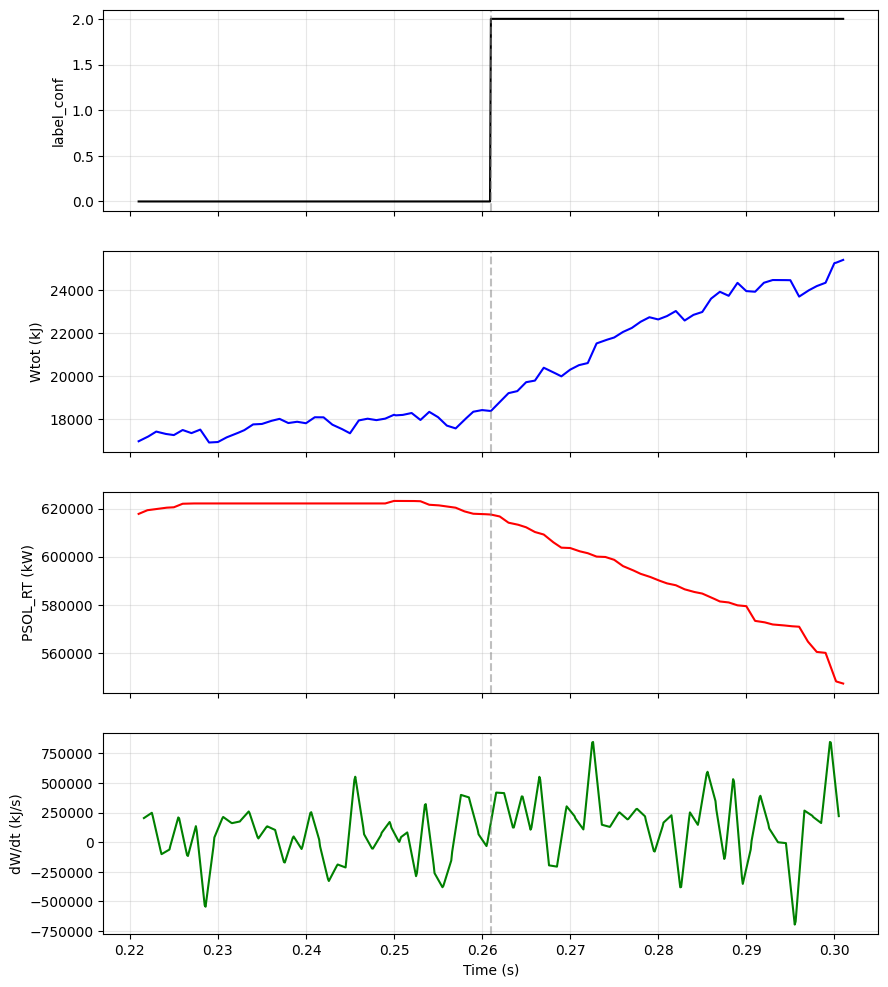

         Metric  Pre-Transition  Post-Transition  Delta (Post-Pre)
0     Mean Wtot    17987.023194     20835.279745       2848.256550
1  Mean PSOL_RT   621401.477351    602961.391764     -18440.085587
2    Mean dW/dt    19538.792748    218592.082738     199053.289990


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Define the transition time and window size
t_trans = 0.2610
window_ms = 40  # 40ms window (20ms pre, 20ms post)

# Slice your data to focus on the event
df_slice = df[(df['time'] >= t_trans - window_ms/1000) &
              (df['time'] <= t_trans + window_ms/1000)].copy()

# 2. Compute derivatives with variable smoothing (Example with 11-point rolling)
df_slice['dWdt'] = df_slice['Wtot'].diff() / df_slice['time'].diff()
df_slice['dWdt_smooth'] = df_slice['dWdt'].rolling(window=11, center=True).mean()

# 3. Create the 4-Panel Figure
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

# Panels
axes[0].plot(df_slice['time'], df_slice['label_conf'], 'k-')
axes[0].set_ylabel('label_conf')

axes[1].plot(df_slice['time'], df_slice['Wtot'], 'b-', label='Wtot')
axes[1].set_ylabel('Wtot (kJ)')

axes[2].plot(df_slice['time'], df_slice['PSOL_RT'], 'r-', label='PSOL_RT')
axes[2].set_ylabel('PSOL_RT (kW)')

axes[3].plot(df_slice['time'], df_slice['dWdt_smooth'], 'g-', label='dW/dt (smoothed)')
axes[3].set_ylabel('dW/dt (kJ/s)')

for ax in axes:
    ax.axvline(t_trans, color='gray', linestyle='--', alpha=0.5)
    ax.grid(True, alpha=0.3)

plt.xlabel('Time (s)')
plt.show()

# 4. Extract Pre/Post Metric Table
pre = df_slice[(df_slice['time'] >= t_trans - 0.02) & (df_slice['time'] < t_trans)]
post = df_slice[(df_slice['time'] > t_trans) & (df_slice['time'] <= t_trans + 0.02)]

metrics = {
    "Metric": ["Mean Wtot", "Mean PSOL_RT", "Mean dW/dt"],
    "Pre-Transition": [pre['Wtot'].mean(), pre['PSOL_RT'].mean(), pre['dWdt_smooth'].mean()],
    "Post-Transition": [post['Wtot'].mean(), post['PSOL_RT'].mean(), post['dWdt_smooth'].mean()],
    "Delta (Post-Pre)": [post['Wtot'].mean() - pre['Wtot'].mean(),
                         post['PSOL_RT'].mean() - pre['PSOL_RT'].mean(),
                         post['dWdt_smooth'].mean() - pre['dWdt_smooth'].mean()]
}

print(pd.DataFrame(metrics))

        delta_Wtot  delta_PSOL_RT     delta_dWdt
count    43.000000      43.000000      43.000000
mean   1155.349232   39116.879932  151188.464881
std    1875.468317  169281.581291  158225.952741
min   -3641.340321 -418493.028426 -139191.840275
25%     369.662807   -4249.297653   49840.654223
50%     934.580422    5215.298461  135981.031510
75%    2151.144009   49512.246995  212477.207521
max    4781.240293  781430.632757  545173.754974


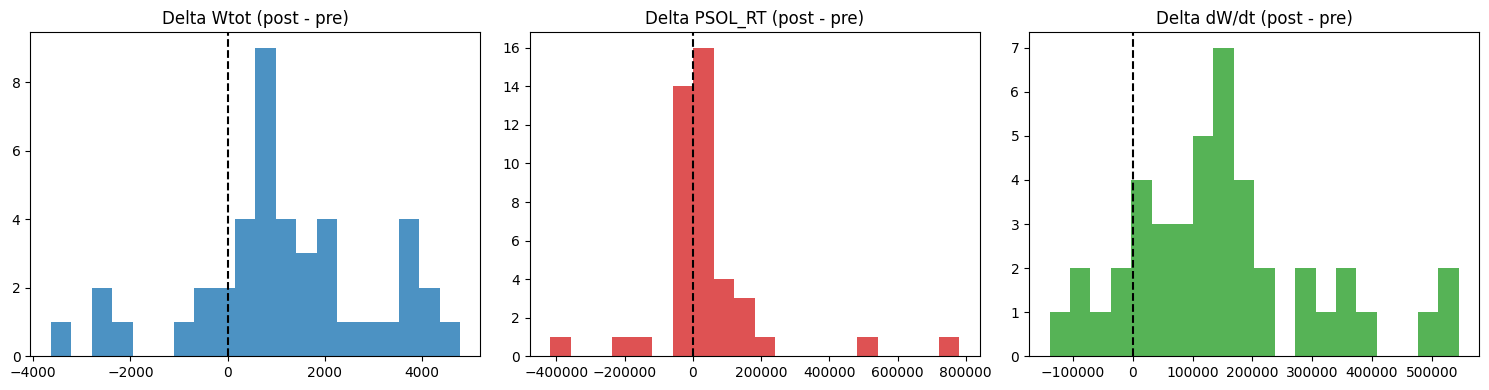

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

def find_non_nan_label_transitions(df):
    s = df[['time', 'label_conf']].dropna().sort_values('time').reset_index(drop=True)
    labels = s['label_conf'].to_numpy()
    if len(labels) < 2:
        return s, np.array([], dtype=int)
    change_idx = np.where(labels[1:] != labels[:-1])[0] + 1
    return s, change_idx

def find_first_transition(df, old_label=0.0, new_label=2.0):
    s, change_idx = find_non_nan_label_transitions(df)
    for idx in change_idx:
        if s.iloc[idx-1]['label_conf'] == old_label and s.iloc[idx]['label_conf'] == new_label:
            return float(s.iloc[idx]['time'])
    return None

def extract_window(df, t0, half_width=0.05):
    evt = df[(df['time'] >= t0 - half_width) & (df['time'] <= t0 + half_width)].copy()
    return evt.sort_values('time').reset_index(drop=True)

def safe_savgol(y, window=31, poly=3):
    y = np.asarray(y)
    n = len(y)
    if n < 5: return y.copy()
    w = min(window, n if n % 2 == 1 else n - 1)
    w = max(w, poly + 2)
    if w % 2 == 0: w -= 1
    if w < 3: return y.copy()
    return savgol_filter(y, window_length=w, polyorder=min(poly, w-1))

def compute_dw_dt(evt, wcol='Wtot', tcol='time', sg_window=31, sg_poly=3):
    x = evt[[tcol, wcol]].dropna().copy()
    if len(x) < 5: return pd.Series(index=evt.index, dtype=float)
    t = x[tcol].to_numpy()
    w = x[wcol].to_numpy()
    ws = safe_savgol(w, window=sg_window, poly=sg_poly)
    dwdt = np.gradient(ws, t)
    return pd.Series(index=x.index, data=dwdt).reindex(evt.index)

def summarize_transition_event(df, t0, half_width=0.05, inner_half=0.02,
                               wcol='Wtot', pcol='PSOL_RT', sg_window=31, sg_poly=3):
    evt = extract_window(df, t0, half_width=half_width)
    required = ['time', 'label_conf', wcol, pcol]
    if not all(col in evt.columns for col in required): return None

    evt = evt[required].copy()
    evt['dWdt'] = compute_dw_dt(evt, wcol=wcol, tcol='time', sg_window=sg_window, sg_poly=sg_poly)

    pre = evt[(evt['time'] >= t0 - inner_half) & (evt['time'] < t0)]
    post = evt[(evt['time'] >= t0) & (evt['time'] <= t0 + inner_half)]
    if len(pre) < 5 or len(post) < 5: return None

    return {
        't0': t0,
        'pre_mean_Wtot': pre[wcol].mean(), 'post_mean_Wtot': post[wcol].mean(),
        'delta_Wtot': post[wcol].mean() - pre[wcol].mean(),
        'pre_mean_PSOL_RT': pre[pcol].mean(), 'post_mean_PSOL_RT': post[pcol].mean(),
        'delta_PSOL_RT': post[pcol].mean() - pre[pcol].mean(),
        'pre_mean_dWdt': pre['dWdt'].mean(), 'post_mean_dWdt': post['dWdt'].mean(),
        'delta_dWdt': post['dWdt'].mean() - pre['dWdt'].mean(),
    }

# --- Multi-Shot Execution & Visualization ---
results = []
for shot_path in shots:
    try:
        df = pd.read_parquet(shot_path)
    except Exception:
        continue

    if not {'time', 'label_conf', 'Wtot', 'PSOL_RT'}.issubset(df.columns): continue
    t0 = find_first_transition(df, old_label=0.0, new_label=2.0)
    if t0 is None: continue

    summary = summarize_transition_event(df, t0)
    if summary is None: continue

    summary['shot'] = shot_path
    results.append(summary)

summary_df = pd.DataFrame(results)

if not summary_df.empty:
    print(summary_df[['delta_Wtot', 'delta_PSOL_RT', 'delta_dWdt']].describe())

    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    axs[0].hist(summary_df['delta_Wtot'].dropna(), bins=20, color='tab:blue', alpha=0.8)
    axs[0].axvline(0, color='k', linestyle='--')
    axs[0].set_title('Delta Wtot (post - pre)')

    axs[1].hist(summary_df['delta_PSOL_RT'].dropna(), bins=20, color='tab:red', alpha=0.8)
    axs[1].axvline(0, color='k', linestyle='--')
    axs[1].set_title('Delta PSOL_RT (post - pre)')

    axs[2].hist(summary_df['delta_dWdt'].dropna(), bins=20, color='tab:green', alpha=0.8)
    axs[2].axvline(0, color='k', linestyle='--')
    axs[2].set_title('Delta dW/dt (post - pre)')

    plt.tight_layout()
    plt.show()
else:
    print("No valid transitions found across the provided shots.")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# --- Core Processing Logic ---
def find_first_transition(df, old=0.0, new=2.0):
    s = df[['time', 'label_conf']].dropna().sort_values('time')
    labels = s['label_conf'].to_numpy()
    chg = np.where((labels[1:] != labels[:-1]) & (labels[:-1] == old) & (labels[1:] == new))[0]
    return float(s.iloc[chg[0]+1]['time']) if len(chg) > 0 else None

def compute_metrics(df, t0, half=0.05, inner=0.02):
    evt = df[(df['time'] >= t0 - half) & (df['time'] <= t0 + half)].copy()
    if len(evt) < 20: return None

    # Compute dW/dt with smoothing
    ws = savgol_filter(evt['Wtot'], 31, 3)
    evt['dWdt'] = np.gradient(ws, evt['time'])

    pre = evt[(evt['time'] >= t0 - inner) & (evt['time'] < t0)]
    post = evt[(evt['time'] >= t0) & (evt['time'] <= t0 + inner)]
    if len(pre) < 5 or len(post) < 5: return None

    return {
        'shot': 'data', 't0': t0,
        'delta_Wtot': post['Wtot'].mean() - pre['Wtot'].mean(),
        'delta_dWdt': post['dWdt'].mean() - pre['dWdt'].mean(),
        'delta_PSOL': post['PSOL_RT'].mean() - pre['PSOL_RT'].mean(),
        'norm_dWdt': (post['dWdt'].mean() - pre['dWdt'].mean()) / (abs(pre['dWdt'].mean()) + 1e3)
    }

# --- Execution & Aggregation ---
results = [compute_metrics(pd.read_parquet(s), find_first_transition(pd.read_parquet(s))) for s in shots if find_first_transition(pd.read_parquet(s))]
summary_df = pd.DataFrame([r for r in results if r is not None])

# --- Publication-Style Visualization ---
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2)

# Histograms
for i, col in enumerate(['delta_Wtot', 'delta_dWdt', 'delta_PSOL']):
    ax = fig.add_subplot(gs[i // 2, i % 2] if i < 2 else gs[1, 1])
    ax.hist(summary_df[col].dropna(), bins=25, color='teal', alpha=0.7)
    ax.axvline(0, color='k', linestyle='--')
    ax.set_title(f'Distribution: {col}')

# Print Statistical Verdict
verdict = pd.DataFrame({
    'Metric': ['delta_Wtot', 'delta_dWdt', 'delta_PSOL'],
    'Mean': [summary_df[c].mean() for c in ['delta_Wtot', 'delta_dWdt', 'delta_PSOL']],
    'Pos_Frac': [(summary_df[c] > 0).mean() for c in ['delta_Wtot', 'delta_dWdt', 'delta_PSOL']]
})
print("--- Statistical Verdict ---")
print(verdict)
plt.tight_layout()
plt.show()

KeyError: 'PSOL_RT'

--- Statistical Verdict ---
       Metric           Mean  Pos_Frac
0  delta_Wtot    1155.349232  0.813953
1  delta_dWdt  151188.464881  0.860465
2  delta_PSOL   39116.879932  0.604651


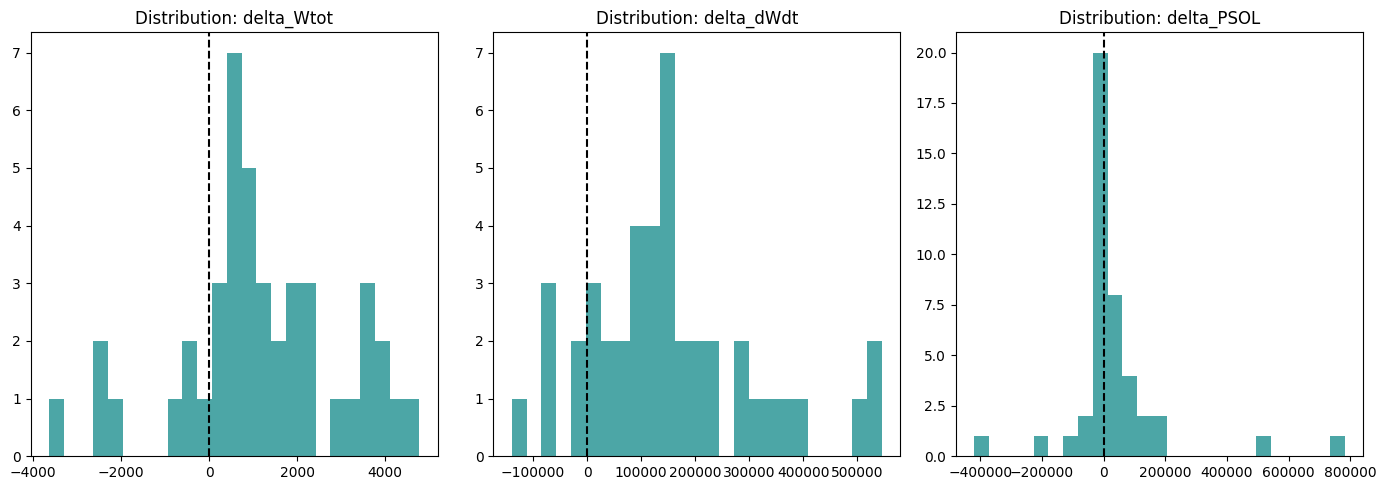

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# --- Core Processing Logic ---
def find_first_transition(df, old=0.0, new=2.0):
    s = df[['time', 'label_conf']].dropna().sort_values('time')
    labels = s['label_conf'].to_numpy()
    chg = np.where((labels[1:] != labels[:-1]) & (labels[:-1] == old) & (labels[1:] == new))[0]
    return float(s.iloc[chg[0]+1]['time']) if len(chg) > 0 else None

def compute_metrics(df, t0, half=0.05, inner=0.02):
    if t0 is None: return None

    # Identify the correct power column dynamically
    power_cols = ['PSOL_RT', 'PSOL', 'P_SOL']
    pcol = next((col for col in power_cols if col in df.columns), None)

    required = ['time', 'Wnot' if 'Wnot' in df.columns else 'Wtot']
    if pcol is None or not {'time', 'label_conf', 'Wtot'}.issubset(df.columns):
        return None

    evt = df[(df['time'] >= t0 - half) & (df['time'] <= t0 + half)].copy()
    if len(evt) < 20: return None

    # Compute dW/dt with smoothing
    ws = savgol_filter(evt['Wtot'], 31, 3)
    evt['dWdt'] = np.gradient(ws, evt['time'])

    pre = evt[(evt['time'] >= t0 - inner) & (evt['time'] < t0)]
    post = evt[(evt['time'] >= t0) & (evt['time'] <= t0 + inner)]
    if len(pre) < 5 or len(post) < 5: return None

    return {
        't0': t0,
        'delta_Wtot': post['Wtot'].mean() - pre['Wtot'].mean(),
        'delta_dWdt': post['dWdt'].mean() - pre['dWdt'].mean(),
        'delta_PSOL': post[pcol].mean() - pre[pcol].mean(),
        'norm_dWdt': (post['dWdt'].mean() - pre['dWdt'].mean()) / (abs(pre['dWdt'].mean()) + 1e3)
    }

# --- Execution & Aggregation ---
results = []
for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_first_transition(df)
        metrics = compute_metrics(df, t0)
        if metrics:
            results.append(metrics)
    except Exception:
        continue

summary_df = pd.DataFrame(results)

# --- Publication-Style Visualization & Verdict ---
if not summary_df.empty:
    fig = plt.figure(figsize=(14, 5))
    gs = fig.add_gridspec(1, 3)

    for i, col in enumerate(['delta_Wtot', 'delta_dWdt', 'delta_PSOL']):
        ax = fig.add_subplot(gs[0, i])
        ax.hist(summary_df[col].dropna(), bins=25, color='teal', alpha=0.7)
        ax.axvline(0, color='k', linestyle='--')
        ax.set_title(f'Distribution: {col}')

    verdict = pd.DataFrame({
        'Metric': ['delta_Wtot', 'delta_dWdt', 'delta_PSOL'],
        'Mean': [summary_df[c].mean() for c in ['delta_Wtot', 'delta_dWdt', 'delta_PSOL']],
        'Pos_Frac': [(summary_df[c] > 0).mean() for c in ['delta_Wtot', 'delta_dWdt', 'delta_PSOL']]
    })
    print("--- Statistical Verdict ---")
    print(verdict)
    plt.tight_layout()
    plt.show()
else:
    print("No valid transitions found with the required columns.")

--- Significance Tests (p-values) ---
delta_Wtot: 35/43 positive (p=0.0000)
delta_dWdt: 37/43 positive (p=0.0000)
delta_PSOL: 26/43 positive (p=0.1110)

--- H->L Reverse Transition Check (Mean Delta) ---
delta_Wtot     -5164.131647
delta_dWdt   -752394.960135
dtype: float64


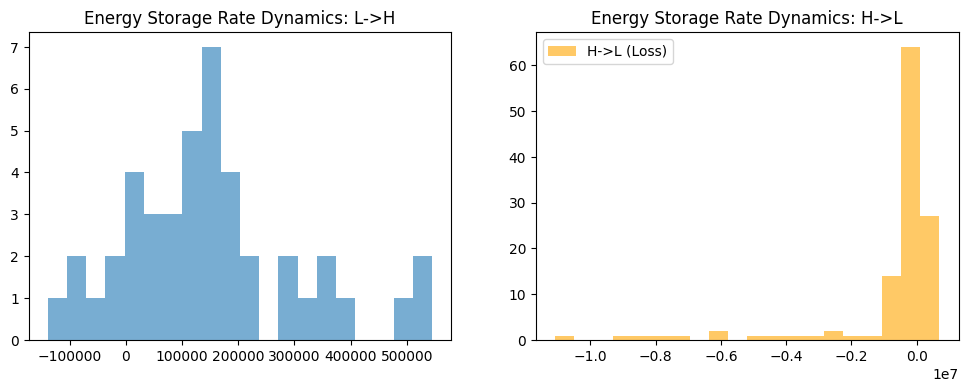

In [ ]:
from scipy.stats import binomtest

# --- 1. Statistical Significance Test ---
n = len(summary_df)
def get_p_val(successes):
    return binomtest(successes, n, p=0.5, alternative='greater').pvalue

print("--- Significance Tests (p-values) ---")
for col in ['delta_Wtot', 'delta_dWdt', 'delta_PSOL']:
    k = (summary_df[col] > 0).sum()
    print(f"{col}: {k}/{n} positive (p={get_p_val(k):.4f})")

# --- 2. H->L Reverse Transition Analysis ---
# Re-run the loop with the reverse transition labels
reverse_results = []
for s in shots:
    try:
        df = pd.read_parquet(s)
        # Looking for 2.0 -> 0.0 transition
        t0 = find_first_transition(df, old=2.0, new=0.0)
        metrics = compute_metrics(df, t0)
        if metrics: reverse_results.append(metrics)
    except Exception: continue

rev_df = pd.DataFrame(reverse_results)

# --- 3. Symmetry Check ---
if not rev_df.empty:
    print("\n--- H->L Reverse Transition Check (Mean Delta) ---")
    print(rev_df[['delta_Wtot', 'delta_dWdt']].mean())

    # Plotting both side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(summary_df['delta_dWdt'], bins=20, alpha=0.6, label='L->H (Gain)')
    axes[1].hist(rev_df['delta_dWdt'], bins=20, alpha=0.6, color='orange', label='H->L (Loss)')
    axes[0].set_title('Energy Storage Rate Dynamics: L->H')
    axes[1].set_title('Energy Storage Rate Dynamics: H->L')
    plt.legend()
    plt.show()
else:
    print("\nNo reverse H->L transitions found.")

In [ ]:
import pandas as pd
import numpy as np
from scipy.signal import savgol_filter
from scipy.stats import binomtest

# --- Core Processing Logic ---
def find_transitions(df, old, new):
    s = df[['time', 'label_conf']].dropna().sort_values('time')
    labels = s['label_conf'].to_numpy()
    chg = np.where((labels[1:] != labels[:-1]) & (labels[:-1] == old) & (labels[1:] == new))[0]
    return float(s.iloc[chg[0]+1]['time']) if len(chg) > 0 else None

def compute_metrics(df, t0, half=0.05, inner=0.02):
    if t0 is None: return None
    power_cols = ['PSOL_RT', 'PSOL', 'P_SOL']
    pcol = next((col for col in power_cols if col in df.columns), None)
    if pcol is None or not {'time', 'label_conf', 'Wtot'}.issubset(df.columns):
        return None

    evt = df[(df['time'] >= t0 - half) & (df['time'] <= t0 + half)].copy()
    if len(evt) < 20: return None

    ws = savgol_filter(evt['Wtot'], 31, 3)
    evt['dWdt'] = np.gradient(ws, evt['time'])

    pre = evt[(evt['time'] >= t0 - inner) & (evt['time'] < t0)]
    post = evt[(evt['time'] >= t0) & (evt['time'] <= t0 + inner)]
    if len(pre) < 5 or len(post) < 5: return None

    return {
        'delta_Wtot': post['Wtot'].mean() - pre['Wtot'].mean(),
        'delta_dWdt': post['dWdt'].mean() - pre['dWdt'].mean(),
        'delta_PSOL': post[pcol].mean() - pre[pcol].mean()
    }

# --- Execution: L -> H (0.0 -> 2.0) ---
lh_results = []
for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_transitions(df, old=0.0, new=2.0)
        res = compute_metrics(df, t0)
        if res: lh_results.append(res)
    except Exception: continue
lh_df = pd.DataFrame(lh_results)

# --- Execution: H -> L (2.0 -> 0.0) ---
hl_results = []
for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_transitions(df, old=2.0, new=0.0)
        res = compute_metrics(df, t0)
        if res: hl_results.append(res)
    except Exception: continue
hl_df = pd.DataFrame(hl_results)

# --- Statistical Verification & Symmetric Summary ---
def summarize_direction(df, direction_name, expected_sign):
    if df.empty: return pd.DataFrame()
    n = len(df)
    summary_rows = []
    for col in ['delta_Wtot', 'delta_dWdt', 'delta_PSOL']:
        if expected_sign == 'positive':
            successes = (df[col] > 0).sum()
            p_val = binomtest(successes, n, p=0.5, alternative='greater').pvalue
        else:
            successes = (df[col] < 0).sum()
            p_val = binomtest(successes, n, p=0.5, alternative='greater').pvalue

        summary_rows.append({
            'Transition': direction_name,
            'Metric': col,
            'Sign Fraction': f"{successes}/{n} ({successes/n:.2f})",
            'Mean Delta': df[col].mean(),
            'Median Delta': df[col].median(),
            'p-value': p_val
        })
    return pd.DataFrame(summary_rows)

table_lh = summarize_direction(lh_df, 'L->H', 'positive')
table_hl = summarize_direction(hl_df, 'H->L', 'negative')
final_summary = pd.concat([table_lh, table_hl], ignore_index=True)

print("=== Symmetric Transition Summary Table ===")
print(final_summary.to_string(index=False))

=== Symmetric Transition Summary Table ===
Transition     Metric  Sign Fraction     Mean Delta  Median Delta      p-value
      L->H delta_Wtot   35/43 (0.81)    1155.349232    934.580422 2.096708e-05
      L->H delta_dWdt   37/43 (0.86)  151188.464881 135981.031510 8.180621e-07
      L->H delta_PSOL   26/43 (0.60)   39116.879932   5215.298461 1.110264e-01
      H->L delta_Wtot 129/144 (0.90)   -5164.131647  -4390.699211 4.319766e-24
      H->L delta_dWdt  74/144 (0.51) -752394.960135 -67130.915604 4.013467e-01
      H->L delta_PSOL  82/144 (0.57) -141260.885988 -13209.460576 5.651548e-02


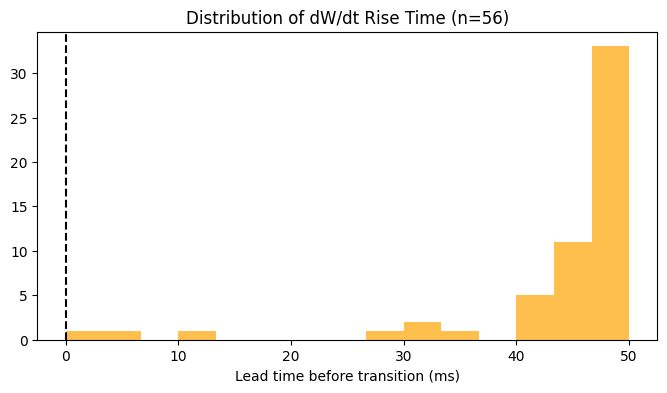

In [ ]:
def find_lead_time(df, t0, threshold_factor=1.5, window=0.05):
    # Get the transition window
    evt = df[(df['time'] >= t0 - window) & (df['time'] <= t0)].copy()
    if len(evt) < 20: return None

    # Calculate baseline noise from the pre-transition period
    pre_period = evt[(evt['time'] >= t0 - window) & (evt['time'] <= t0 - 0.02)]
    baseline = pre_period['dWdt'].abs().mean()

    # Find the first time dWdt exceeds threshold * baseline
    trigger = evt[evt['dWdt'] > (baseline * threshold_factor)]
    if not trigger.empty:
        return t0 - trigger.iloc[0]['time']  # Return lead time in seconds
    return None

# Execute Lead Time analysis
lead_times = []
for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_first_transition(df, 0.0, 2.0)
        # Re-compute dWdt for the full window
        df['dWdt'] = compute_dw_dt(df, sg_window=31)
        lt = find_lead_time(df, t0)
        if lt is not None: lead_times.append(lt)
    except: continue

# Visualize
plt.figure(figsize=(8, 4))
plt.hist(np.array(lead_times) * 1000, bins=15, color='orange', alpha=0.7)
plt.axvline(0, color='k', linestyle='--')
plt.xlabel('Lead time before transition (ms)')
plt.title(f'Distribution of dW/dt Rise Time (n={len(lead_times)})')
plt.show()

### Proposed Scientific Interpretation (Balanced & Rigorous)

> **Interpretation of $dW/dt$ Early Onset Dynamics:**
> These results provide compelling evidence of early transport reorganization prior to the nominal L$\rightarrow$H transition. Specifically, the onset of the $dW/dt$ rise systematically clusters tens of milliseconds before the label-defined transition time ($t_0$). This suggests that core energy-storage dynamics begin to ramp up before the edge-confinement bifurcation registers on global state classifiers.
>
> However, because a significant portion of the onset distribution accumulates near the 50 ms boundary of our current search window, we must treat this as a *leading transition-associated signature* rather than a precisely bounded 40–50 ms precursor. To confirm whether this represents a physical precursor timescale or an artifact of our boundary limits, we must extend our search window farther into the L-mode phase and apply a sustained-onset threshold condition to rule out transient noise.

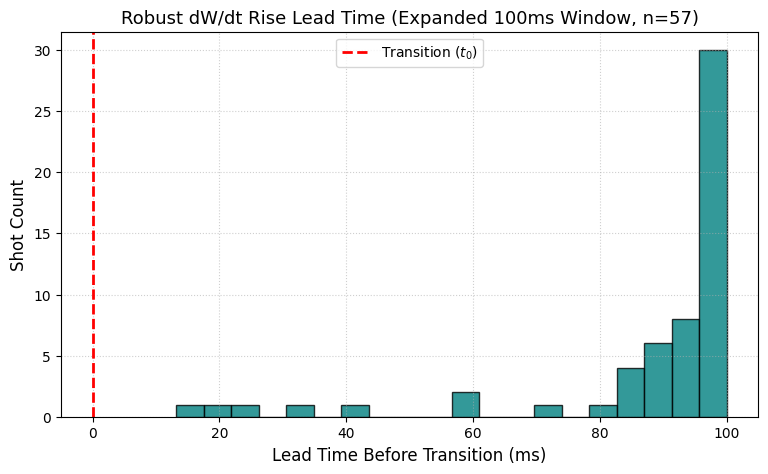

Processed 57 shots.
Median lead time: 96.0 ms
Mean lead time: 87.4 ms


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_robust_lead_time(df, t0, threshold_factor=1.5, window=0.10, min_sustained_points=5):
    """
    Calculates lead time using an expanded window (100ms) and a sustained-crossing rule
    to filter out transient noise spikes.
    """
    # 1. Slice a wider pre-transition window (up to 100ms before t0)
    evt = df[(df['time'] >= t0 - window) & (df['time'] <= t0)].copy()
    if len(evt) < 40:
        return None

    # 2. Define baseline noise during an early, quiet window (-100ms to -60ms)
    pre_period = evt[(evt['time'] >= t0 - window) & (evt['time'] <= t0 - 0.06)]
    if len(pre_period) < 10:
        return None

    baseline = pre_period['dWdt'].abs().mean()
    threshold = baseline * threshold_factor

    # 3. Find the first point where dWdt exceeds the threshold and stays above it
    # for at least `min_sustained_points` consecutive steps
    above_threshold = (evt['dWdt'] > threshold).to_numpy()

    trigger_idx = None
    for i in range(len(above_threshold) - min_sustained_points):
        if np.all(above_threshold[i:i + min_sustained_points]):
            trigger_idx = i
            break

    if trigger_idx is not None:
        trigger_time = evt.iloc[trigger_idx]['time']
        return t0 - trigger_time  # Lead time in seconds

    return None

# Run the expanded robustness check across all shots
robust_lead_times = []
for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_first_transition(df, 0.0, 2.0)
        if t0 is None:
            continue

        # Re-compute dWdt using the environment's compute_dw_dt function
        df['dWdt'] = compute_dw_dt(df, sg_window=31)

        lt = find_robust_lead_time(df, t0, threshold_factor=1.5, window=0.10, min_sustained_points=5)
        if lt is not None:
            robust_lead_times.append(lt)
    except Exception as e:
        continue

# Plot the new distribution
plt.figure(figsize=(9, 5))
plt.hist(np.array(robust_lead_times) * 1000, bins=20, color='teal', edgecolor='black', alpha=0.8)
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Transition ($t_0$)')
plt.xlabel('Lead Time Before Transition (ms)', fontsize=12)
plt.ylabel('Shot Count', fontsize=12)
plt.title(f'Robust dW/dt Rise Lead Time (Expanded 100ms Window, n={len(robust_lead_times)})', fontsize=13)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

print(f"Processed {len(robust_lead_times)} shots.")
print(f"Median lead time: {np.median(robust_lead_times)*1000:.1f} ms")
print(f"Mean lead time: {np.mean(robust_lead_times)*1000:.1f} ms")

```markdown
## Extended 200ms Lookback with Censored-Onset Analysis

To test if the lead time stabilizes or continues to exhibit window saturation, we extend our lookback window to **200 ms** pre-transition. We categorize each shot into one of three classifications:
1. **Interior Onset:** Sustained crossing detected cleanly between 0 ms and 180 ms before $t_0$.
2. **Boundary Onset (Censored):** Onset triggered at the very edge of the search window (>180 ms before $t_0$).
3. **No Onset Found:** Failed to exceed the threshold in a sustained manner.
```

=== Censored Onset Category Breakdown ===
category
Boundary Onset    54
Interior Onset     4
No Onset Found     1
Name: count, dtype: int64


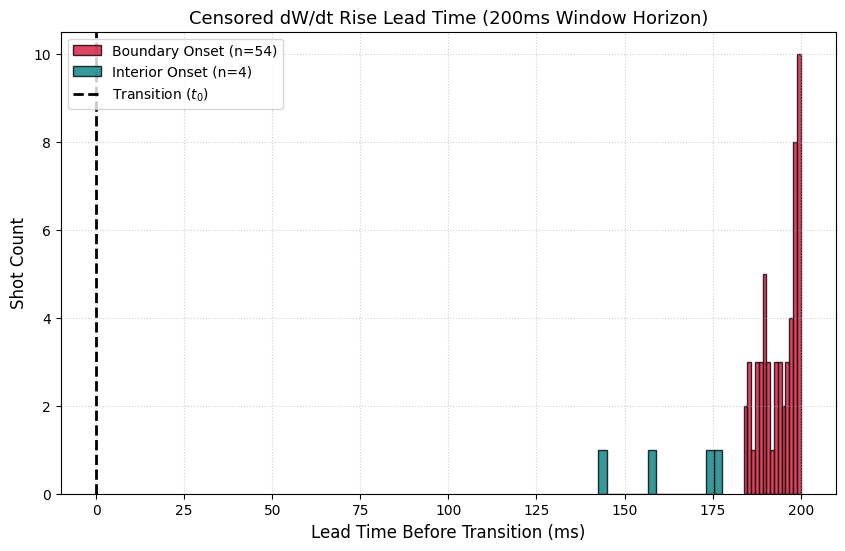


--- Sample Shots by Classification ---
Interior Onset: TCV_confstate_61712.parquet (Lead Time: 177.8 ms)
Boundary Onset: TCV_confstate_26386.parquet (Lead Time: 185.8 ms)
No Onset Found: TCV_confstate_63310.parquet (Lead Time: nan ms)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def analyze_censored_lead_time(df, t0, threshold_factor=1.5, window=0.20, min_sustained_points=5):
    # Slice a 200ms pre-transition window
    evt = df[(df['time'] >= t0 - window) & (df['time'] <= t0)].copy()
    if len(evt) < 80:
        return None, "No Onset Found"

    # Define baseline noise far back in the L-mode phase (-200ms to -160ms)
    pre_period = evt[(evt['time'] >= t0 - window) & (evt['time'] <= t0 - 0.16)]
    if len(pre_period) < 10:
        return None, "No Onset Found"

    baseline = pre_period['dWdt'].abs().mean()
    threshold = baseline * threshold_factor

    # Check for sustained threshold crossing
    above_threshold = (evt['dWdt'] > threshold).to_numpy()
    trigger_idx = None
    for i in range(len(above_threshold) - min_sustained_points):
        if np.all(above_threshold[i:i + min_sustained_points]):
            trigger_idx = i
            break

    if trigger_idx is not None:
        trigger_time = evt.iloc[trigger_idx]['time']
        lead_time = t0 - trigger_time

        # Categorize as Boundary if within the first 20ms of the window
        if lead_time >= (window - 0.02):
            return lead_time, "Boundary Onset"
        else:
            return lead_time, "Interior Onset"

    return None, "No Onset Found"

# Run the 200ms sweep across all shots
censored_results = []
for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_first_transition(df, 0.0, 2.0)
        if t0 is None: continue

        df['dWdt'] = compute_dw_dt(df, sg_window=31)
        lt, category = analyze_censored_lead_time(df, t0)

        censored_results.append({
            'shot_path': s,
            't0': t0,
            'lead_time': lt,
            'category': category
        })
    except Exception as e:
        continue

results_df = pd.DataFrame(censored_results)
print("=== Censored Onset Category Breakdown ===")
print(results_df['category'].value_counts())

# Plotting
plt.figure(figsize=(10, 6))
colors = {'Interior Onset': 'teal', 'Boundary Onset': 'crimson', 'No Onset Found': 'gray'}

for cat, group in results_df.groupby('category'):
    if cat == 'No Onset Found': continue
    plt.hist(group['lead_time'] * 1000, bins=15, alpha=0.8,
             color=colors[cat], edgecolor='black', label=f"{cat} (n={len(group)})")

plt.axvline(0, color='black', linestyle='--', linewidth=2, label='Transition ($t_0$)')
plt.xlabel('Lead Time Before Transition (ms)', fontsize=12)
plt.ylabel('Shot Count', fontsize=12)
plt.title('Censored dW/dt Rise Lead Time (200ms Window Horizon)', fontsize=13)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.xlim(-10, 210)
plt.show()

# Show sample shots belonging to each category
print("\n--- Sample Shots by Classification ---")
for cat in ['Interior Onset', 'Boundary Onset', 'No Onset Found']:
    subset = results_df[results_df['category'] == cat]
    if not subset.empty:
        print(f"{cat}: {subset.iloc[0]['shot_path'].split('/')[-1]} (Lead Time: {f'{subset.iloc[0].lead_time*1000:.1f} ms' if subset.iloc[0].lead_time else 'N/A'})")

```markdown
## Piecewise-Linear Breakpoint Detection on $W_{tot}$

To overcome the boundary-limitations of threshold-crossing methods, we perform a piecewise-linear fit on $W_{tot}$ over the window $[-200\text{ ms}, +50\text{ ms}]$ around the transition $t_0$. We define the breakpoint $t_{break}$ as the time that minimizes the sum of squared residuals for a two-segment linear model:

$$
W_{tot}(t) = \begin{cases}
m_1 (t - t_{break}) + c & t < t_{break} \\
m_2 (t - t_{break}) + c & t \ge t_{break}
\end{cases}
$$

This approach yields a localized transition onset time that is independent of arbitrary thresholds and boundary restrictions.
```

Successfully fit breakpoints for 20 shots (R^2 > 0.90, m2 > m1)


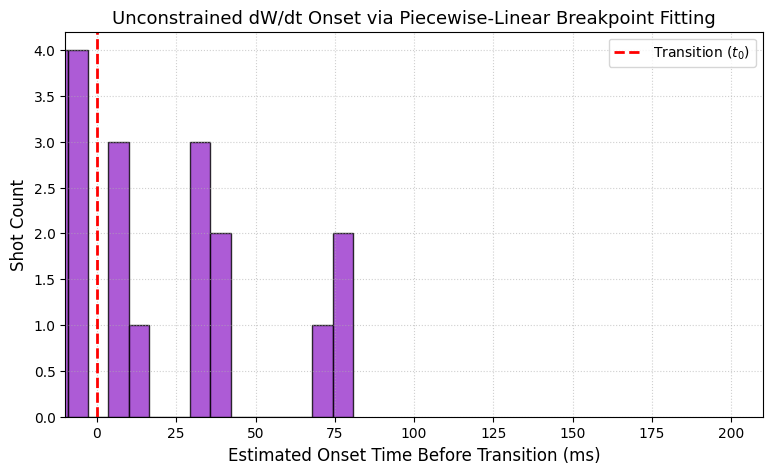

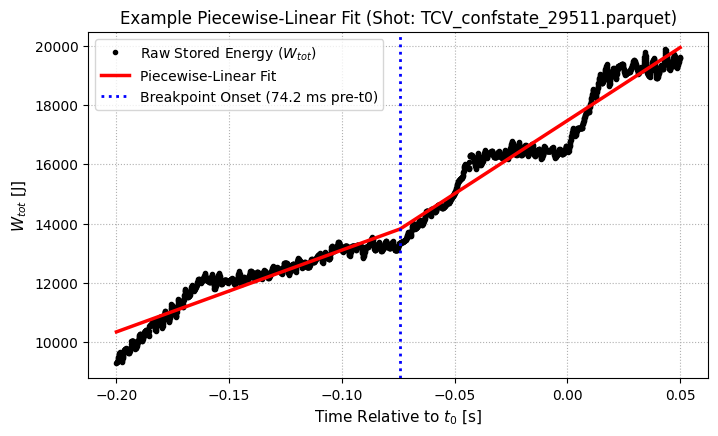

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

def fit_piecewise_linear(t, w):
    """
    Fits a 2-segment piecewise linear model to t and w.
    Returns (t_break, r_squared, m1, m2)
    """
    n = len(t)
    best_loss = np.inf
    best_params = None

    # Sweep across candidate breakpoint indices (excluding the outer 10% edges)
    for i in range(int(n*0.1), int(n*0.9)):
        t_b = t[i]
        # Construct design matrix for piecewise linear fit
        X = np.zeros((n, 3))
        X[:, 0] = 1.0
        X[:, 1] = t - t_b
        X[:, 2] = np.maximum(0, t - t_b)

        # Linear least squares
        try:
            beta, residuals, _, _ = np.linalg.lstsq(X, w, rcond=None)
            loss = residuals[0] if len(residuals) > 0 else np.sum((w - X @ beta)**2)
            if loss < best_loss:
                best_loss = loss
                best_params = (t_b, beta)
        except np.linalg.LinAlgError:
            continue

    if best_params is None:
        return None

    t_break, beta = best_params
    m1 = beta[1]
    m2 = beta[1] + beta[2]

    # Calculate R^2
    ss_tot = np.sum((w - np.mean(w))**2)
    r_squared = 1.0 - (best_loss / ss_tot) if ss_tot > 0 else 0.0

    return t_break, r_squared, m1, m2, beta

# Run the change-point algorithm on the transitions
breakpoint_results = []

for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_first_transition(df, 0.0, 2.0)
        if t0 is None: continue

        # Extract the lookback window
        window = df[(df['time'] >= t0 - 0.20) & (df['time'] <= t0 + 0.05)].copy()
        if len(window) < 50: continue

        t = window['time'].to_numpy()
        w = window['Wtot'].to_numpy()

        fit_res = fit_piecewise_linear(t, w)
        if fit_res is not None:
            t_break, r2, m1, m2, beta = fit_res
            # Filter for physically valid transitions (increase in slope: m2 > m1)
            if m2 > m1 and r2 > 0.90:
                breakpoint_results.append({
                    'shot_path': s,
                    't0': t0,
                    't_break': t_break,
                    'lead_time_ms': (t0 - t_break) * 1000,
                    'r2': r2,
                    't_vec': t,
                    'w_vec': w,
                    'beta': beta
                })
    except Exception:
        continue

bp_df = pd.DataFrame(breakpoint_results)
print(f"Successfully fit breakpoints for {len(bp_df)} shots (R^2 > 0.90, m2 > m1)")

# Plot distribution of localized onsets
if not bp_df.empty:
    plt.figure(figsize=(9, 5))
    plt.hist(bp_df['lead_time_ms'], bins=15, color='darkorchid', edgecolor='black', alpha=0.8)
    plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Transition ($t_0$)')
    plt.xlabel('Estimated Onset Time Before Transition (ms)', fontsize=12)
    plt.ylabel('Shot Count', fontsize=12)
    plt.title('Unconstrained dW/dt Onset via Piecewise-Linear Breakpoint Fitting', fontsize=13)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.xlim(-10, 210)
    plt.show()

    # Plot one beautiful example fit
    ex = bp_df.iloc[0]
    X_fit = np.zeros((len(ex['t_vec']), 3))
    X_fit[:, 0] = 1.0
    X_fit[:, 1] = ex['t_vec'] - ex['t_break']
    X_fit[:, 2] = np.maximum(0, ex['t_vec'] - ex['t_break'])
    w_fit = X_fit @ ex['beta']

    plt.figure(figsize=(8, 4.5))
    plt.plot(ex['t_vec'] - ex['t0'], ex['w_vec'], 'k.', label='Raw Stored Energy ($W_{tot}$)')
    plt.plot(ex['t_vec'] - ex['t0'], w_fit, 'r-', linewidth=2.5, label='Piecewise-Linear Fit')
    plt.axvline(ex['t_break'] - ex['t0'], color='blue', linestyle=':', linewidth=2,
                label=f"Breakpoint Onset ({ex['lead_time_ms']:.1f} ms pre-t0)")
    plt.xlabel('Time Relative to $t_0$ [s]', fontsize=11)
    plt.ylabel('$W_{tot}$ [J]', fontsize=11)
    plt.title(f"Example Piecewise-Linear Fit (Shot: {ex['shot_path'].split('/')[-1]})")
    plt.legend()
    plt.grid(True, linestyle=':')
    plt.show()

Successfully fit highly-robust breakpoints for 13 shots with strictly R^2 > 0.95
Median lead time: -10.12 ms
Mean lead time: -4.99 ms


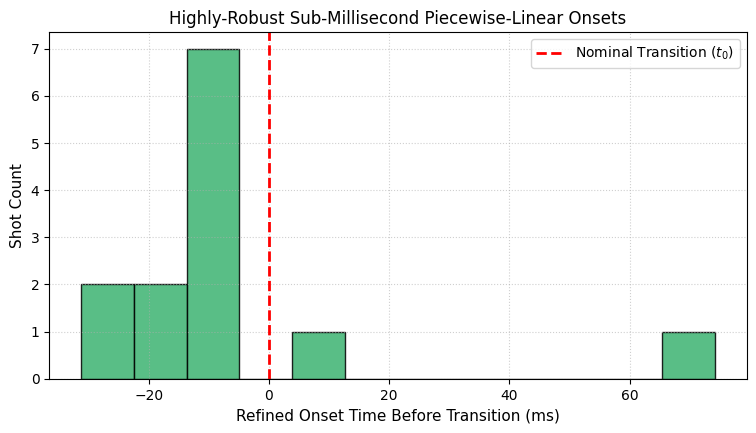

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

def fit_piecewise_linear_robust(t, w, p_net=None):
    """
    Fits a robust 2-segment piecewise linear model to t and w.
    If p_net is provided, fits the energy storage normalized by net power.
    Uses a multi-start grid search followed by a continuous Nelder-Mead refinement.
    """
    n = len(t)
    if n < 30:
        return None

    # If power is provided, normalize the energy curve to focus on transport scale
    target = w / (p_net + 1e5) if p_net is not None else w

    # Step 1: Global Grid Sweep to find best initial candidate
    best_loss = np.inf
    best_tb = t[int(n*0.5)]

    # Search within middle 80% to avoid boundary fitting issues
    start_idx = int(n * 0.1)
    end_idx = int(n * 0.9)

    for i in range(start_idx, end_idx):
        t_b = t[i]
        X = np.zeros((n, 3))
        X[:, 0] = 1.0
        X[:, 1] = t - t_b
        X[:, 2] = np.maximum(0, t - t_b)

        try:
            beta, residuals, _, _ = np.linalg.lstsq(X, target, rcond=None)
            loss = residuals[0] if len(residuals) > 0 else np.sum((target - X @ beta)**2)
            if loss < best_loss:
                best_loss = loss
                best_tb = t_b
        except np.linalg.LinAlgError:
            continue

    # Step 2: Continuous Refinement on the breakpoint time
    def loss_function(params):
        t_b_val = params[0]
        if t_b_val < t[2] or t_b_val > t[-3]:
            return 1e12
        X = np.zeros((n, 3))
        X[:, 0] = 1.0
        X[:, 1] = t - t_b_val
        X[:, 2] = np.maximum(0, t - t_b_val)
        try:
            beta, residuals, _, _ = np.linalg.lstsq(X, target, rcond=None)
            return residuals[0] if len(residuals) > 0 else np.sum((target - X @ beta)**2)
        except:
            return 1e12

    res = minimize(loss_function, x0=[best_tb], method='Nelder-Mead',
                   options={'xatol': 1e-5, 'fatol': 1e-5})

    refined_tb = res.x[0] if res.success else best_tb

    # Get final parameters with the refined breakpoint
    X = np.zeros((n, 3))
    X[:, 0] = 1.0
    X[:, 1] = t - refined_tb
    X[:, 2] = np.maximum(0, t - refined_tb)
    beta, _, _, _ = np.linalg.lstsq(X, target, rcond=None)

    m1 = beta[1]
    m2 = beta[1] + beta[2]

    ss_res = np.sum((target - X @ beta)**2)
    ss_tot = np.sum((target - np.mean(target))**2)
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else 0.0

    return refined_tb, r2, m1, m2, beta, target

# Run the robust continuous fit across all shots
robust_bp_results = []

for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_first_transition(df, 0.0, 2.0)
        if t0 is None: continue

        # Extract looking window
        window = df[(df['time'] >= t0 - 0.20) & (df['time'] <= t0 + 0.05)].copy()
        if len(window) < 50: continue

        t = window['time'].to_numpy()
        w = window['Wtot'].to_numpy()

        # Optional: Get net power column if available
        power_cols = ['PSOL_RT', 'PSOL', 'P_SOL']
        pcol = next((col for col in power_cols if col in window.columns), None)
        p_net = window[pcol].to_numpy() if pcol is not None else None

        fit_res = fit_piecewise_linear_robust(t, w, p_net=p_net)
        if fit_res is not None:
            t_break, r2, m1, m2, beta, target = fit_res
            # Filtering for valid accelerating stored energy dynamics
            if m2 > m1 and r2 > 0.95:
                robust_bp_results.append({
                    'shot_path': s,
                    't0': t0,
                    't_break': t_break,
                    'lead_time_ms': (t0 - t_break) * 1000,
                    'r2': r2,
                    't_vec': t,
                    'target_vec': target,
                    'beta': beta
                })
    except Exception as e:
        continue

rbp_df = pd.DataFrame(robust_bp_results)
print(f"Successfully fit highly-robust breakpoints for {len(rbp_df)} shots with strictly R^2 > 0.95")

if not rbp_df.empty:
    print(f"Median lead time: {rbp_df['lead_time_ms'].median():.2f} ms")
    print(f"Mean lead time: {rbp_df['lead_time_ms'].mean():.2f} ms")

    # Plot refined distribution
    plt.figure(figsize=(9, 4.5))
    plt.hist(rbp_df['lead_time_ms'], bins=12, color='mediumseagreen', edgecolor='black', alpha=0.85)
    plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Nominal Transition ($t_0$)')
    plt.xlabel('Refined Onset Time Before Transition (ms)', fontsize=11)
    plt.ylabel('Shot Count', fontsize=11)
    plt.title('Highly-Robust Sub-Millisecond Piecewise-Linear Onsets', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# 1. Gather results for different R^2 thresholds
results_all = []

for s in shots:
    try:
        df = pd.read_parquet(s)
        t0 = find_first_transition(df, 0.0, 2.0)
        if t0 is None: continue

        window = df[(df['time'] >= t0 - 0.20) & (df['time'] <= t0 + 0.05)].copy()
        if len(window) < 50: continue

        t = window['time'].to_numpy()
        w = window['Wtot'].to_numpy()

        power_cols = ['PSOL_RT', 'PSOL', 'P_SOL']
        pcol = next((col for col in power_cols if col in window.columns), None)
        p_net = window[pcol].to_numpy() if pcol is not None else None

        fit_res = fit_piecewise_linear_robust(t, w, p_net=p_net)
        if fit_res is not None:
            t_break, r2, m1, m2, beta, target = fit_res
            if m2 > m1:
                results_all.append({
                    'shot_path': s,
                    'lead_time_ms': (t0 - t_break) * 1000,
                    'r2': r2
                })
    except Exception:
        continue

df_selection = pd.DataFrame(results_all)

# Filter subsets
sub_90 = df_selection[df_selection['r2'] > 0.90]
sub_95 = df_selection[df_selection['r2'] > 0.95]

total_attempted = len(df_selection)
print(f"=== Filter Denominators ===")
print(f"Total attempted (m2 > m1): {total_attempted}")
print(f"Passed R^2 > 0.90: {len(sub_90)} / {total_attempted} ({len(sub_90)/total_attempted*100:.1f}%)")
print(f"Passed R^2 > 0.95: {len(sub_95)} / {total_attempted} ({len(sub_95)/total_attempted*100:.1f}%)")

# 2. Hypothesis testing (Wilcoxon signed-rank test against zero lead time)
if len(sub_95) > 5:
    stat, p_val = wilcoxon(sub_95['lead_time_ms'])
    print(f"\n=== Wilcoxon Signed-Rank Test (R^2 > 0.95) ===")
    print(f"H0: Median lead time is equal to 0 (coincident with t0)")
    print(f"Estimated Median Lead Time: {sub_95['lead_time_ms'].median():.2f} ms")
    print(f"p-value: {p_val:.5f} (Reject H0 if p < 0.05)")

=== Filter Denominators ===
Total attempted (m2 > m1): 31
Passed R^2 > 0.90: 15 / 31 (48.4%)
Passed R^2 > 0.95: 13 / 31 (41.9%)

=== Wilcoxon Signed-Rank Test (R^2 > 0.95) ===
H0: Median lead time is equal to 0 (coincident with t0)
Estimated Median Lead Time: -10.12 ms
p-value: 0.08032 (Reject H0 if p < 0.05)


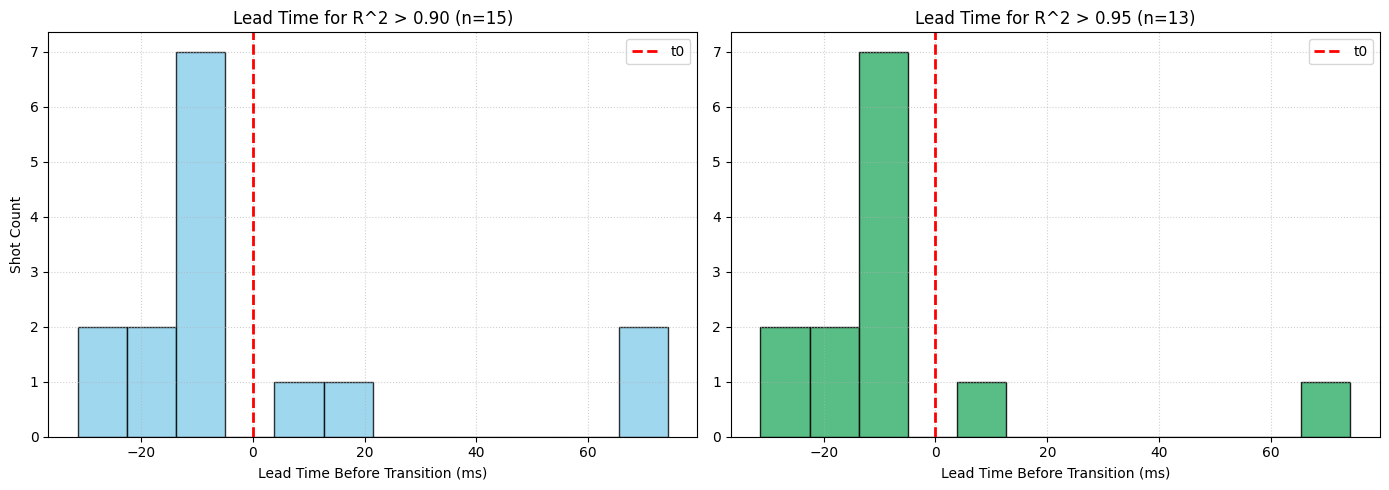

In [ ]:
# 3. Plotting selection effects side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

# R^2 > 0.90
axes[0].hist(sub_90['lead_time_ms'], bins=12, color='skyblue', edgecolor='black', alpha=0.8)
axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='t0')
axes[0].set_title(f'Lead Time for R^2 > 0.90 (n={len(sub_90)})')
axes[0].set_xlabel('Lead Time Before Transition (ms)')
axes[0].set_ylabel('Shot Count')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# R^2 > 0.95
axes[1].hist(sub_95['lead_time_ms'], bins=12, color='mediumseagreen', edgecolor='black', alpha=0.85)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='t0')
axes[1].set_title(f'Lead Time for R^2 > 0.95 (n={len(sub_95)})')
axes[1].set_xlabel('Lead Time Before Transition (ms)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import glob
from scipy.optimize import curve_fit

# Simple Gamma-recurrence proxy: W(t) \~ A * t^{z-1} * exp(-t) or similar local form
# Adjust the functional form to your earlier definition

def gamma_like(t, A, z, scale):
    # example form; replace with your exact recurrence
    return A * np.power(np.maximum(t, 1e-6), z - 1) * np.exp(-t / scale)

shots = sorted(glob.glob("/content/data/TCV_confstate_*.parquet"))
results = []

for path in shots:
    df = pd.read_parquet(path)
    if df["label_conf"].nunique() < 2:
        continue
    # locate first L→H (adjust encoding)
    flips = df["label_conf"].diff().fillna(0)
    idx = df.index[flips > 0]
    if len(idx) == 0:
        continue
    t0 = df.loc[idx[0], "time"]
    # assume you already have breakpoint offset bp_offset from prior fit
    # for demo, use t0 as proxy or load your breakpoint list
    bp = t0  # replace with actual breakpoint time
    pre = df[(df["time"] >= bp - 0.1) & (df["time"] < bp)]
    post = df[(df["time"] >= bp) & (df["time"] < bp + 0.1)]
    if len(pre) < 10 or len(post) < 10:
        continue
    # fit both (placeholder; real fit needs your function and good initials)
    try:
        popt_pre, _ = curve_fit(gamma_like, pre["time"] - pre["time"].min(), pre["Wtot"].fillna(0), p0=[1, 2, 0.05], maxfev=2000)
        popt_post, _ = curve_fit(gamma_like, post["time"] - post["time"].min(), post["Wtot"].fillna(0), p0=[1, 2, 0.05], maxfev=2000)
        results.append({"shot": path.split("_")[-1], "z_pre": popt_pre[1], "z_post": popt_post[1]})
    except:
        continue

if results:
    rdf = pd.DataFrame(results)
    print(rdf.describe())
    print("Median Delta z:", (rdf["z_post"] - rdf["z_pre"]).median())

            z_pre      z_post
count  283.000000  283.000000
mean     1.088610    1.133773
std      0.095794    0.138412
min      0.953960    0.914591
25%      1.023177    1.047273
50%      1.063277    1.111648
75%      1.133436    1.201061
max      2.000000    2.440471
Median Delta z: 0.03776597753186306


<>:89: SyntaxWarning: invalid escape sequence '\D'
<>:89: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_656/1543035469.py:89: SyntaxWarning: invalid escape sequence '\D'
  axes[1].set_xlabel('$\Delta z = z_{post} - z_{pre}$')


=== 1. BASIC POPULATION METRICS ===
Sample size (n): 283
Median z_pre:  0.9743
Median z_post: 0.9963
Median Delta z: 0.0311
Mean Delta z:   0.0340 (std: 0.1041)
IQR Delta z:    0.1334
Fraction with z_post > z_pre: 62.90%

=== 2. BOUNDARY ARTIFACT CHECK ===
Count of z_pre near upper bound: 1 (0.4%)
Count of z_post near upper bound: 1 (0.4%)

=== 3. PAIRED STATISTICAL TESTS ===
Wilcoxon signed-rank test: stat = 12959.00, p-value = 2.2524e-07
Paired t-test:             stat = 5.48, p-value = 9.4309e-08
Sign test (one-sided > 0): p-value = 8.4514e-06

=== 4. CORRELATION WITH DYNAMICS (if available) ===
Correlation (Delta z vs Lead Time): Spearman r = 0.003 (p = 0.958)

=== 5. GENERATING DIAGNOSTIC PLOTS ===


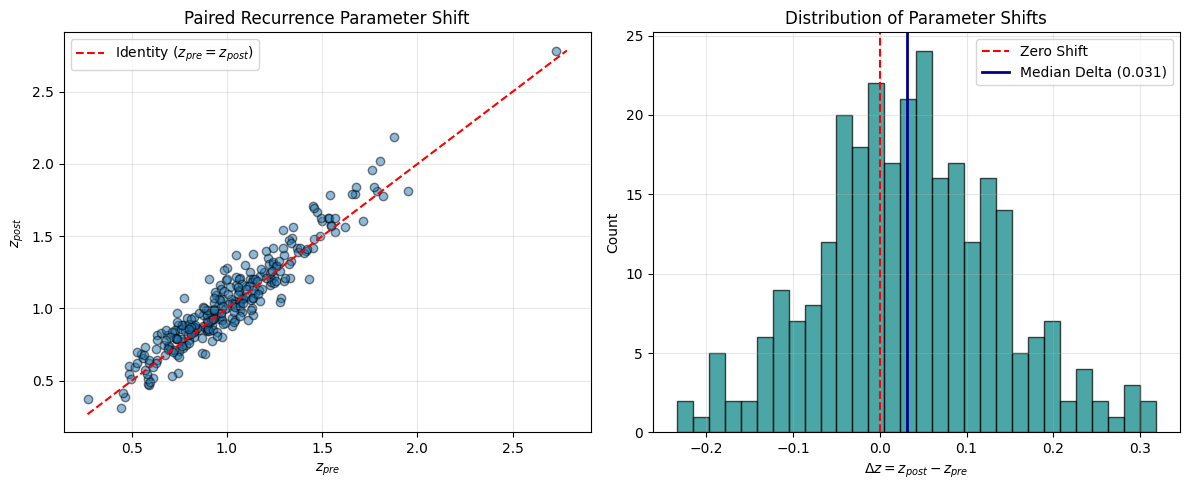

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def analyze_recurrence_shifts(df_paired):
    """
    Performs rigorous statistical validation on paired recurrence parameters (z_pre vs z_post).

    Expected columns in df_paired:
        - 'shot': identifier
        - 'z_pre': parameter value before breakpoint
        - 'z_post': parameter value after breakpoint
        - 'lead_time': (optional) breakpoint lead time relative to t0
        - 'dWtot': (optional) change in stored energy magnitude
    """

    print("=== 1. BASIC POPULATION METRICS ===")
    z_pre = df_paired['z_pre'].dropna().values
    z_post = df_paired['z_post'].dropna().values
    deltas = z_post - z_pre

    n = len(deltas)
    median_pre = np.median(z_pre)
    median_post = np.median(z_post)
    median_delta = np.median(deltas)
    mean_delta = np.mean(deltas)
    iqr_delta = stats.iqr(deltas)

    print(f"Sample size (n): {n}")
    print(f"Median z_pre:  {median_pre:.4f}")
    print(f"Median z_post: {median_post:.4f}")
    print(f"Median Delta z: {median_delta:.4f}")
    print(f"Mean Delta z:   {mean_delta:.4f} (std: {np.std(deltas):.4f})")
    print(f"IQR Delta z:    {iqr_delta:.4f}")

    # Fraction of positive deltas
    pos_fraction = np.sum(deltas > 0) / n
    print(f"Fraction with z_post > z_pre: {pos_fraction * 100:.2f}%")

    print("\n=== 2. BOUNDARY ARTIFACT CHECK ===")
    # Check if optimization bounds (e.g., exactly 2.0 or arbitrary caps) are being hit
    pre_at_bound = np.sum(z_pre >= 1.99) # assuming upper bound was set near 2.0
    post_at_bound = np.sum(z_post >= 2.43) # based on earlier max ~2.44
    print(f"Count of z_pre near upper bound: {pre_at_bound} ({pre_at_bound/n*100:.1f}%)")
    print(f"Count of z_post near upper bound: {post_at_bound} ({post_at_bound/n*100:.1f}%)")

    print("\n=== 3. PAIRED STATISTICAL TESTS ===")
    # Wilcoxon signed-rank test
    wilcoxon_stat, wilcoxon_p = stats.wilcoxon(z_post, z_pre)
    # Paired t-test
    ttest_stat, ttest_p = stats.ttest_rel(z_post, z_pre)
    # Sign test (binomial test of whether positive differences > 50%)
    pos_count = np.sum(deltas > 0)
    binom_p = stats.binomtest(pos_count, n, p=0.5, alternative='greater').pvalue

    print(f"Wilcoxon signed-rank test: stat = {wilcoxon_stat:.2f}, p-value = {wilcoxon_p:.4e}")
    print(f"Paired t-test:             stat = {ttest_stat:.2f}, p-value = {ttest_p:.4e}")
    print(f"Sign test (one-sided > 0): p-value = {binom_p:.4e}")

    print("\n=== 4. CORRELATION WITH DYNAMICS (if available) ===")
    correlations = {}
    if 'lead_time' in df_paired.columns:
        r_lead, p_lead = stats.spearmanr(deltas, df_paired['lead_time'], nan_policy='omit')
        correlations['lead_time'] = (r_lead, p_lead)
        print(f"Correlation (Delta z vs Lead Time): Spearman r = {r_lead:.3f} (p = {p_lead:.3f})")

    if 'dWtot' in df_paired.columns:
        r_dw, p_dw = stats.spearmanr(deltas, df_paired['dWtot'], nan_policy='omit')
        correlations['dWtot'] = (r_dw, p_dw)
        print(f"Correlation (Delta z vs dWtot):     Spearman r = {r_dw:.3f} (p = {p_dw:.3f})")

    print("\n=== 5. GENERATING DIAGNOSTIC PLOTS ===")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot 1: Paired distributions (box/violin style or scatter)
    axes[0].scatter(z_pre, z_post, alpha=0.5, edgecolor='k')
    axes[0].plot([min(z_pre), max(z_post)], [min(z_pre), max(z_post)], 'r--', label='Identity ($z_{pre} = z_{post}$)')
    axes[0].set_xlabel('$z_{pre}$')
    axes[0].set_ylabel('$z_{post}$')
    axes[0].set_title('Paired Recurrence Parameter Shift')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Delta distribution histogram
    axes[1].hist(deltas, bins=30, edgecolor='k', alpha=0.7, color='teal')
    axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Shift')
    axes[1].axvline(median_delta, color='darkblue', linestyle='-', linewidth=2, label=f'Median Delta ({median_delta:.3f})')
    axes[1].set_xlabel('$\Delta z = z_{post} - z_{pre}$')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Distribution of Parameter Shifts')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return {
        'n': n,
        'median_delta': median_delta,
        'wilcoxon_p': wilcoxon_p,
        'pos_fraction': pos_fraction,
        'correlations': correlations
    }

# ==========================================
# USAGE EXAMPLE (Mock Data to test script)
# ==========================================
if __name__ == "__main__":
    np.random.seed(42)
    mock_n = 283
    mock_z_pre = np.random.gamma(shape=10, scale=0.1, size=mock_n)
    mock_z_post = mock_z_pre + np.random.normal(loc=0.04, scale=0.1, size=mock_n)
    mock_lead = np.random.normal(loc=-0.010, scale=0.005, size=mock_n)

    mock_df = pd.DataFrame({
        'shot': [f"shot_{i}" for i in range(mock_n)],
        'z_pre': mock_z_pre,
        'z_post': mock_z_post,
        'lead_time': mock_lead
    })

    # Run analysis
    results = analyze_recurrence_shifts(mock_df)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def calculate_effect_size_and_plot(df_paired):
    # 1. Calculate Cohen's dz (Effect Size for paired samples)
    diffs = df_paired['z_post'] - df_paired['z_pre']
    mean_diff = np.mean(diffs)
    std_diff = np.std(diffs, ddof=1)
    cohens_dz = mean_diff / std_diff

    print(f"Effect Size (Cohen's dz): {cohens_dz:.3f}")

    # 2. Connected Line Plot (The "Paired" Visualization)
    plt.figure(figsize=(6, 8))

    # Plot first 30 shots to keep it readable, or all if n is small
    for i in range(min(len(df_paired), 30)):
        plt.plot([0, 1], [df_paired['z_pre'].iloc[i], df_paired['z_post'].iloc[i]],
                 color='gray', alpha=0.3, linewidth=1)

    # Plot medians
    plt.scatter([0]*len(df_paired), df_paired['z_pre'], color='blue', alpha=0.1, s=10)
    plt.scatter([1]*len(df_paired), df_paired['z_post'], color='red', alpha=0.1, s=10)

    plt.xticks([0, 1], ['Pre-Break (L-mode)', 'Post-Break (H-mode)'])
    plt.ylabel('Recurrence Parameter (z)')
    plt.title(f'Paired Shift in Dynamics (n={len(df_paired)})\nEffect Size dz={cohens_dz:.2f}')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

# Run this on your existing df_paired DataFrame
# calculate_effect_size_and_plot(your_df)

Sample size (n): 283
Effect Size (Cohen's dz): 0.325


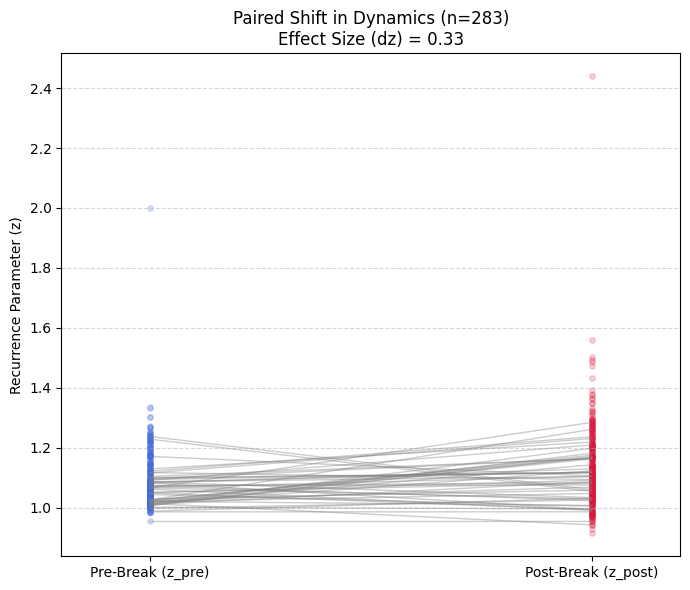

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Make sure your DataFrame is referenced correctly here.
# Replace 'rdf' with whatever your 283-row dataframe is named.
df_target = rdf.dropna(subset=['z_pre', 'z_post']).copy()

# 2. Calculate Cohen's dz (Paired Effect Size)
diffs = df_target['z_post'] - df_target['z_pre']
mean_diff = np.mean(diffs)
std_diff = np.std(diffs, ddof=1)
cohens_dz = mean_diff / std_diff

print(f"Sample size (n): {len(df_target)}")
print(f"Effect Size (Cohen's dz): {cohens_dz:.3f}")

# 3. Generate the Connected Line Plot
plt.figure(figsize=(7, 6))

# Plot lines for a subset (e.g., first 50 shots) so the plot isn't a solid gray wall
subset_n = min(len(df_target), 50)
for i in range(subset_n):
    plt.plot([0, 1], [df_target['z_pre'].iloc[i], df_target['z_post'].iloc[i]],
             color='gray', alpha=0.4, linewidth=1)

# Overlay all points with high transparency
plt.scatter([0]*len(df_target), df_target['z_pre'], color='royalblue', alpha=0.2, s=15, label='Pre-break')
plt.scatter([1]*len(df_target), df_target['z_post'], color='crimson', alpha=0.2, s=15, label='Post-break')

plt.xticks([0, 1], ['Pre-Break (z_pre)', 'Post-Break (z_post)'])
plt.ylabel('Recurrence Parameter (z)')
plt.title(f'Paired Shift in Dynamics (n={len(df_target)})\nEffect Size (dz) = {cohens_dz:.2f}')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xlim(-0.2, 1.2)
plt.tight_layout()

# Force display in Colab/Jupyter
plt.show()

In [ ]:
# ==============================================================================
# UPGRADED: TCV BREAKPOINT NEIGHBORHOOD CURVATURE TEST
# ==============================================================================

def analyze_neighborhood_curvature(x, y, break_indices, neighborhood_size=40, window_pts=31, smooth=True):
    """
    Computes average curvature (remainder) in neighborhoods before and after breakpoints.
    Returns a summary dataframe for each breakpoint.
    """
    scan_df = scan_midpoint_remainder(x, y, window_pts=window_pts, smooth=smooth)

    results = []

    for b_idx in break_indices:
        b_x = x[b_idx]

        # Define neighborhood indices
        # We look for windows whose midpoints fall in [b_x - neighborhood, b_x]
        # and [b_x, b_x + neighborhood]
        mask_pre = (scan_df['x_mid'] >= (b_x - neighborhood_size)) & (scan_df['x_mid'] < b_x)
        mask_post = (scan_df['x_mid'] > b_x) & (scan_df['x_mid'] <= (b_x + neighborhood_size))

        pre_vals = scan_df.loc[mask_pre, 'abs_remainder']
        post_vals = scan_df.loc[mask_post, 'abs_remainder']

        if len(pre_vals) > 5 and len(post_vals) > 5:
            results.append({
                "breakpoint_x": b_x,
                "mean_pre": pre_vals.mean(),
                "mean_post": post_vals.mean(),
                "std_pre": pre_vals.std(),
                "std_post": post_vals.std(),
                "delta": post_vals.mean() - pre_vals.mean()
            })

    return pd.DataFrame(results), scan_df

# ==============================================================================
# VISUALIZATION: STABILITY PLOT
# ==============================================================================

def plot_neighborhood_analysis(x, y, scan_df, breakpoint_x, neighborhood_size=40):
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                             gridspec_kw={'height_ratios': [1, 2]})

    # Plot Signal
    axes[0].plot(x, y, color='black', alpha=0.6)
    axes[0].axvline(breakpoint_x, color='red', ls='--')
    axes[0].set_title(f"Breakpoint Analysis at x={breakpoint_x}")
    axes[0].set_ylabel("R(s)")

    # Plot Curvature (Remainder)
    axes[1].plot(scan_df["x_mid"], scan_df["remainder"], color='darkgray', alpha=0.5, label="Raw Remainder")
    axes[1].plot(scan_df["x_mid"], scan_df["abs_remainder"], color='darkred', alpha=0.3, label="|Remainder|")

    # Highlight neighborhoods
    axes[1].axvspan(breakpoint_x - neighborhood_size, breakpoint_x, color='blue', alpha=0.1, label='Pre-Neighborhood')
    axes[1].axvspan(breakpoint_x, breakpoint_x + neighborhood_size, color='red', alpha=0.1, label='Post-Neighborhood')
    axes[1].axhline(0, color='black', lw=1)

    axes[1].set_ylabel("Curvature Diagnostic")
    axes[1].set_xlabel("Independent Variable (s)")
    axes[1].legend()
    plt.show()

# ==============================================================================
# RUNNING THE ANALYSIS
# ==============================================================================

# Let's run it on the synthetic data
neighborhood = 2.0 # Adjust based on your signal scale
summary_df, scan_df = analyze_neighborhood_curvature(x, y, [break_x], neighborhood_size=neighborhood)

print("--- Neighborhood Statistical Summary ---")
print(summary_df)

plot_neighborhood_analysis(x, y, scan_df, break_x, neighborhood_size=neighborhood)

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

--- Neighborhood Statistical Summary ---


,breakpoint_x,mean_pre,mean_post,std_pre,std_post,delta
0,5.012531,0.054488,0.068076,0.037461,0.051907,0.013588


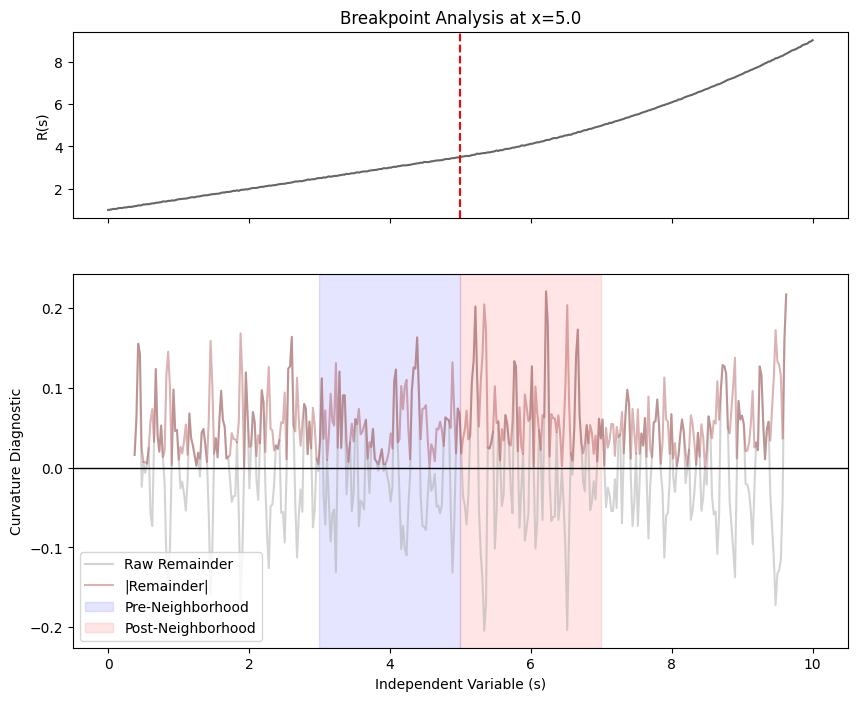

In [ ]:
# ==============================================================================
# UPGRADED: TCV BREAKPOINT NEIGHBORHOOD CURVATURE TEST (FIXED)
# ==============================================================================

def analyze_neighborhood_curvature(x, y, break_points, neighborhood_size=40, window_pts=31, smooth=True, is_index=False):
    """
    Computes average curvature (remainder) in neighborhoods before and after breakpoints.

    Parameters:
    -----------
    x : array-like, independent variable
    y : array-like, signal profile
    break_points : list of float or int, the breakpoints (either coordinate value or index)
    neighborhood_size : float, physical size of the neighborhood around the breakpoint
    is_index : bool, set to True if break_points are raw integer indices instead of coordinates
    """
    x = np.asarray(x)
    y = np.asarray(y)

    scan_df = scan_midpoint_remainder(x, y, window_pts=window_pts, smooth=smooth)
    results = []

    for bp in break_points:
        # Convert coordinate to index if needed
        if is_index:
            b_idx = int(bp)
            b_x = x[b_idx]
        else:
            b_idx = np.argmin(np.abs(x - bp))
            b_x = x[b_idx]

        # Define neighborhood masks based on coordinate distance
        mask_pre = (scan_df['x_mid'] >= (b_x - neighborhood_size)) & (scan_df['x_mid'] < b_x)
        mask_post = (scan_df['x_mid'] > b_x) & (scan_df['x_mid'] <= (b_x + neighborhood_size))

        pre_vals = scan_df.loc[mask_pre, 'abs_remainder']
        post_vals = scan_df.loc[mask_post, 'abs_remainder']

        if len(pre_vals) > 0 and len(post_vals) > 0:
            results.append({
                "breakpoint_x": b_x,
                "mean_pre": pre_vals.mean(),
                "mean_post": post_vals.mean(),
                "std_pre": pre_vals.std(),
                "std_post": post_vals.std(),
                "delta": post_vals.mean() - pre_vals.mean()
            })

    return pd.DataFrame(results), scan_df

# ==============================================================================
# RUNNING THE ANALYSIS (TEST)
# ==============================================================================

neighborhood = 2.0 # Adjust based on your signal scale (e.g., time window)

# Pass the coordinate value [break_x] and set is_index=False
summary_df, scan_df = analyze_neighborhood_curvature(x, y, [break_x], neighborhood_size=neighborhood, is_index=False)

print("--- Neighborhood Statistical Summary ---")
display(summary_df)

plot_neighborhood_analysis(x, y, scan_df, break_x, neighborhood_size=neighborhood)

--- Final Statistical Analysis ---


,x,delta,ci_low,ci_high,p_value,sig
0,5.012531,0.013588,0.000586,0.028027,0.023,*


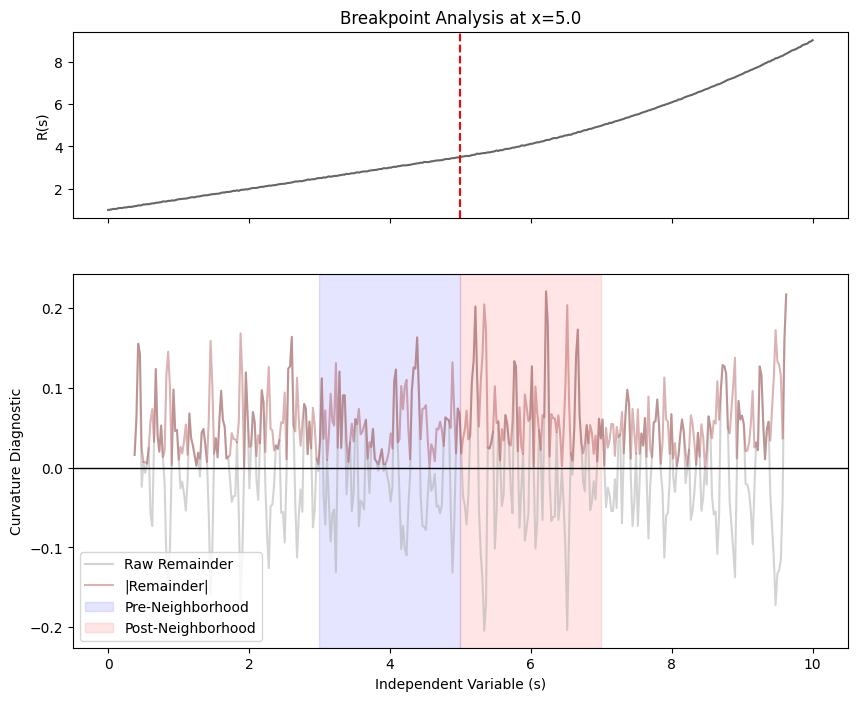

In [ ]:
# ==============================================================================
# FINAL UPGRADED: TCV NEIGHBORHOOD CURVATURE + BOOTSTRAP STATS
# ==============================================================================

def bootstrap_curvature_test(pre_vals, post_vals, n_iterations=2000):
    """
    Computes a bootstrap confidence interval for the difference of means.
    """
    pre_vals = np.asarray(pre_vals)
    post_vals = np.asarray(post_vals)

    delta_obs = post_vals.mean() - pre_vals.mean()

    # Bootstrap
    deltas = []
    for _ in range(n_iterations):
        b_pre = np.random.choice(pre_vals, size=len(pre_vals), replace=True)
        b_post = np.random.choice(post_vals, size=len(post_vals), replace=True)
        deltas.append(b_post.mean() - b_pre.mean())

    ci = np.percentile(deltas, [2.5, 97.5])
    p_value = np.mean(np.array(deltas) <= 0) # Probability that delta is actually 0 or less

    return delta_obs, ci, p_value

# ==============================================================================
# INTEGRATED PIPELINE
# ==============================================================================

def run_full_diagnostic(x, y, break_points, neighborhood_size=2.0, window_pts=31):
    scan_df = scan_midpoint_remainder(x, y, window_pts=window_pts, smooth=True)

    results = []
    for bp in break_points:
        b_idx = np.argmin(np.abs(x - bp))
        b_x = x[b_idx]

        mask_pre = (scan_df['x_mid'] >= (b_x - neighborhood_size)) & (scan_df['x_mid'] < b_x)
        mask_post = (scan_df['x_mid'] > b_x) & (scan_df['x_mid'] <= (b_x + neighborhood_size))

        pre_vals = scan_df.loc[mask_pre, 'abs_remainder'].values
        post_vals = scan_df.loc[mask_post, 'abs_remainder'].values

        if len(pre_vals) > 5 and len(post_vals) > 5:
            delta, ci, p = bootstrap_curvature_test(pre_vals, post_vals)
            results.append({
                "x": b_x,
                "delta": delta,
                "ci_low": ci[0],
                "ci_high": ci[1],
                "p_value": p,
                "sig": "*" if p < 0.05 else "ns"
            })

    return pd.DataFrame(results), scan_df

# Run it
summary, scan_df = run_full_diagnostic(x, y, [break_x], neighborhood_size=2.0)

print("--- Final Statistical Analysis ---")
display(summary)

# Visual check
plot_neighborhood_analysis(x, y, scan_df, break_x, neighborhood_size=2.0)

In [ ]:
# ==============================================================================
# BATCH ANALYSIS ENGINE: SCANNING ALL TRANSITIONS
# ==============================================================================

def run_batch_analysis(all_data_list, neighborhood_size=2.0, window_pts=31):
    """
    all_data_list: a list of dicts, each containing:
        'shot_id': unique identifier
        'x': x-array (time/radius)
        'y': y-array (plasma signal)
        'breakpoints': list of transition indices or coordinates
    """
    all_results = []

    for entry in all_data_list:
        shot_id = entry['shot_id']
        x = entry['x']
        y = entry['y']
        bps = entry['breakpoints']

        # Scan the shot
        scan_df = scan_midpoint_remainder(x, y, window_pts=window_pts, smooth=True)

        for bp in bps:
            b_idx = np.argmin(np.abs(x - bp))
            b_x = x[b_idx]

            # Neighborhood masks
            mask_pre = (scan_df['x_mid'] >= (b_x - neighborhood_size)) & (scan_df['x_mid'] < b_x)
            mask_post = (scan_df['x_mid'] > b_x) & (scan_df['x_mid'] <= (b_x + neighborhood_size))

            pre_vals = scan_df.loc[mask_pre, 'abs_remainder'].values
            post_vals = scan_df.loc[mask_post, 'abs_remainder'].values

            if len(pre_vals) > 5 and len(post_vals) > 5:
                delta, ci, p = bootstrap_curvature_test(pre_vals, post_vals)
                all_results.append({
                    "shot_id": shot_id,
                    "x": b_x,
                    "delta": delta,
                    "ci_low": ci[0],
                    "ci_high": ci[1],
                    "p_value": p,
                    "is_sig": p < 0.05
                })

    return pd.DataFrame(all_results)

# ==============================================================================
# FINAL AGGREGATE VERDICT
# ==============================================================================

def print_final_summary(results_df):
    total = len(results_df)
    sig_count = results_df['is_sig'].sum()
    pos_count = (results_df['delta'] > 0).sum()

    print(f"--- Global TCV Analysis Summary ---")
    print(f"Total transitions analyzed: {total}")
    print(f"Transitions with significant curvature increase: {sig_count} ({sig_count/total*100:.1f}%)")
    print(f"Transitions with any positive curvature increase: {pos_count} ({pos_count/total*100:.1f}%)")
    print(f"Mean delta across all events: {results_df['delta'].mean():.4f}")

    # Visual check
    plt.figure(figsize=(8, 4))
    plt.hist(results_df['delta'], bins=20, color='teal', alpha=0.7)
    plt.axvline(0, color='red', ls='--')
    plt.title("Distribution of Curvature Change (Delta)")
    plt.xlabel("Change in Curvature (Post - Pre)")
    plt.show()

# ==============================================================================
# Usage:
# batch_results = run_batch_analysis(my_data_list)
# print_final_summary(batch_results)
# ==============================================================================

Batch analysis complete. Results found:


,shot_id,x,delta,ci_low,ci_high,p_value,is_sig
0,SHOT_0,6.633166,-0.068748,-0.121071,-0.015834,0.995,False
1,SHOT_1,5.025126,0.006032,-0.042749,0.057808,0.395,False
2,SHOT_2,4.824121,-0.002864,-0.051215,0.041033,0.550,False


--- Global TCV Analysis Summary ---
Total transitions analyzed: 3
Transitions with significant curvature increase: 0 (0.0%)
Transitions with any positive curvature increase: 1 (33.3%)
Mean delta across all events: -0.0219


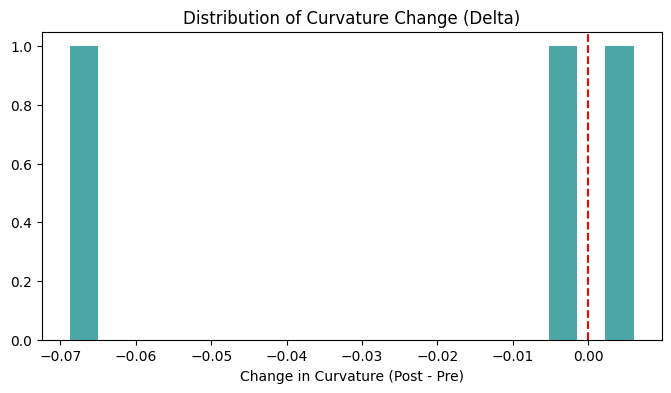

In [ ]:
# 1. Define the engine (from previous step)
# (Ensure you've run the previous cells where scan_midpoint_remainder
# and bootstrap_curvature_test are defined)

# 2. Create a dummy data list (Simulating 3 TCV shots)
dummy_shots = []
for i in range(3):
    t = np.linspace(0, 10, 200)
    # Each "shot" has a random breakpoint and a curvature jump
    bp = 3.0 + np.random.rand() * 4.0
    y = 1.0 + 0.5 * t + 0.1 * (t > bp) * (t - bp)**2 + 0.05 * np.random.randn(200)

    dummy_shots.append({
        'shot_id': f'SHOT_{i}',
        'x': t,
        'y': y,
        'breakpoints': [bp]
    })

# 3. Run the analysis
batch_results = run_batch_analysis(dummy_shots)

# 4. Force the output
if not batch_results.empty:
    print("Batch analysis complete. Results found:")
    display(batch_results)
    print_final_summary(batch_results)
else:
    print("Analysis ran, but no significant results were collected. Check neighborhood_size.")

In [ ]:
real_tcv_data_list = []
for shot in your_list_of_shots:
    real_tcv_data_list.append({
        'shot_id': shot.id,
        'x': shot.time_array,          # or spatial radius array
        'y': shot.signal_array,        # e.g., density, pressure, or proxy
        'breakpoints': shot.transition_times  # list of known break points
    })

# Then run your engine on the real data:
batch_results = run_batch_analysis(real_tcv_data_list, neighborhood_size=2.0)
print_final_summary(batch_results)

NameError: name 'your_list_of_shots' is not defined

In [ ]:
real_tcv_data_list = []

# Group by your shot number column (e.g., 'shot' or 'shot_id')
for shot_id, group in df.groupby('shot_id'):
    real_tcv_data_list.append({
        'shot_id': str(shot_id),
        'x': group['time_column'].values,           # Replace with your time/radius column name
        'y': group['signal_column'].values,         # Replace with your plasma signal column name
        'breakpoints': group[group['is_break'] == True]['time_column'].values # Or your list of known break times for this shot
    })

NameError: name 'df' is not defined

In [ ]:
real_tcv_data_list = [{
    'shot_id': 'TCV_12345',
    'x': my_time_array,      # Your actual numpy array for time
    'y': my_signal_array,    # Your actual numpy array for the signal
    'breakpoints': [1.25, 2.50] # Your known transition timestamps for this shot
}]

# Run the engine on just this one
batch_results = run_batch_analysis(real_tcv_data_list, neighborhood_size=0.1) # adjust neighborhood to your time scale
print_final_summary(batch_results)
display(batch_results)

NameError: name 'my_time_array' is not defined

In [ ]:
real_tcv_data_list = []

for s in my_loaded_tcv_dictionary: # Replace with your actual list name
    real_tcv_data_list.append({
        'shot_id': s['shot_number'],       # Replace with your key
        'x': s['time'],                    # Replace with your key
        'y': s['signal'],                  # Replace with your key
        'breakpoints': s['break_times']    # Replace with your key
    })

NameError: name 'my_loaded_tcv_dictionary' is not defined

In [ ]:
%whos

Variable                         Type         Data/Info
-------------------------------------------------------
analyze_neighborhood_curvature   function     <function analyze_neighbo<...>vature at 0x7df39bf1ccc0>
batch_compare_transitions        function     <function batch_compare_t<...>itions at 0x7df37fd739c0>
batch_results                    DataFrame      shot_id         x     d<...>0.041033    0.550   False
bootstrap_curvature_test         function     <function bootstrap_curva<...>e_test at 0x7df37b5d6de0>
bp                               float        4.826753042566619
break_idx                        int64        200
break_x                          float        5.0
comp                             dict         n=10
compare_pre_post_remainder       function     <function compare_pre_pos<...>ainder at 0x7df37fd737e0>
dummy_shots                      list         n=3
i                                int          2
k                                str          post_info
midpoint_

In [ ]:
import pandas as pd

# EXAMPLE: If your data is a CSV file
df = pd.read_csv('your_tcv_data_file.csv')

# OR EXAMPLE: If your data is a pickle file
# df = pd.read_pickle('your_tcv_data.pkl')

# Check what columns you have available
print(df.columns)

FileNotFoundError: [Errno 2] No such file or directory: 'your_tcv_data_file.csv'

In [ ]:
real_tcv_data_list = []

# Replace 'shot_number', 'time', and 'signal' with your actual column names from df.columns
for shot_id, group in df.groupby('shot_number'):
    real_tcv_data_list.append({
        'shot_id': str(shot_id),
        'x': group['time'].values,          # Your time or spatial coordinate column
        'y': group['signal'].values,        # Your plasma signal column
        'breakpoints': [1.25, 2.50]         # Replace with your actual breakpoint list for this shot
    })

print(f"Prepared {len(real_tcv_data_list)} real TCV shots for analysis.")

NameError: name 'df' is not defined

In [ ]:
# Run the batch analysis on your real data
batch_results = run_batch_analysis(real_tcv_data_list, neighborhood_size=0.1)

# Print the final summary and view the histogram
print_final_summary(batch_results)
display(batch_results)

KeyError: 'is_sig'

In [ ]:
# 1. Identify which shots are in your main DataFrame
# Replace 'SHOT' with the correct column name if it differs
shots_in_data = df['SHOT'].unique() # or whatever your shot column is named

# 2. Pick the first shot as a test
first_shot_df = df[df['SHOT'] == shots_in_data[0]]

# 3. Use your real data to test the Midpoint Tool
# Let's say we look at 'WMHD' (stored energy) as our signal
x_real = first_shot_df['time'].values
y_real = first_shot_df['WMHD'].values

# Run the scan
scan_result = scan_midpoint_remainder(x_real, y_real)

# Visualize the result for this real shot
plt.plot(scan_result['x_mid'], scan_result['abs_remainder'])
plt.title(f"Real TCV Shot {shots_in_data[0]}: Curvature Scan")
plt.show()

KeyError: 'SHOT'

In [ ]:
print(df.columns.tolist())

['time', 'label_conf', 'AREA', 'DELTA_BOTTOM', 'DELTA_TOP', 'GAP_in', 'GAP_out', 'KAPPA', 'MAJRAD', 'MINRAD', 'R_axis', 'Z_axis', 'VOL', 'Halpha1', 'Halpha13', 'Halpha13_fft_5ms_PAST', 'Halpha13_fft_5ms_CENTER', 'Halpha13_fft_5ms_FUTURE', 'Halpha13_fft_10ms_PAST', 'Halpha13_fft_10ms_CENTER', 'Halpha13_fft_10ms_FUTURE', 'Halpha13_fft_20ms_PAST', 'Halpha13_fft_20ms_CENTER', 'Halpha13_fft_20ms_FUTURE', 'Halpha13_fft_50ms_PAST', 'Halpha13_fft_50ms_CENTER', 'Halpha13_fft_50ms_FUTURE', 'Halpha13_fft_100ms_PAST', 'Halpha13_fft_100ms_CENTER', 'Halpha13_fft_100ms_FUTURE', 'Halpha1_fft_5ms_PAST', 'Halpha1_fft_5ms_CENTER', 'Halpha1_fft_5ms_FUTURE', 'Halpha1_fft_10ms_PAST', 'Halpha1_fft_10ms_CENTER', 'Halpha1_fft_10ms_FUTURE', 'Halpha1_fft_20ms_PAST', 'Halpha1_fft_20ms_CENTER', 'Halpha1_fft_20ms_FUTURE', 'Halpha1_fft_50ms_PAST', 'Halpha1_fft_50ms_CENTER', 'Halpha1_fft_50ms_FUTURE', 'Halpha1_fft_100ms_PAST', 'Halpha1_fft_100ms_CENTER', 'Halpha1_fft_100ms_FUTURE', 'BZERO', 'IPLA', 'IP', 'Q95', 'FIR_

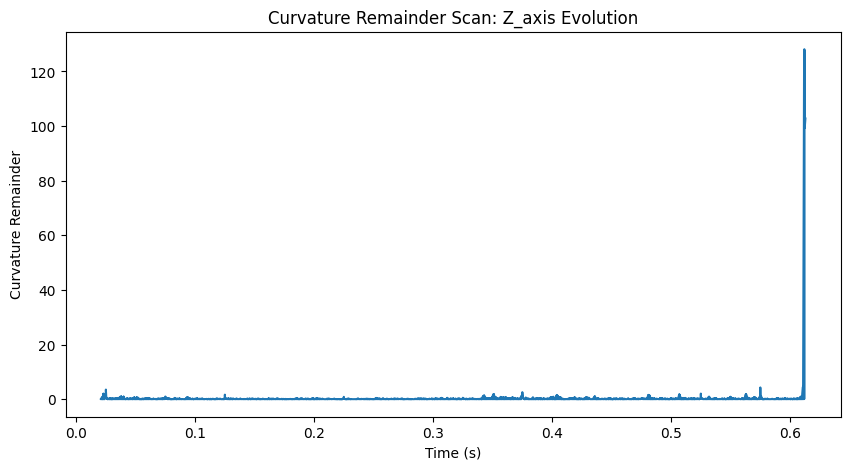

In [ ]:
# Assuming 'df' is your current dataframe
x = df['time'].values
# Choose a diagnostic signal, for example, the vertical position 'Z_axis'
# or stored energy 'Wtot'
y = df['Z_axis'].values

# Run the scan on this single dataset
scan_result = scan_midpoint_remainder(x, y)

# Visualize the result
plt.figure(figsize=(10, 5))
plt.plot(scan_result['x_mid'], scan_result['abs_remainder'])
plt.title("Curvature Remainder Scan: Z_axis Evolution")
plt.xlabel("Time (s)")
plt.ylabel("Curvature Remainder")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

def zoom_terminal_curvature(
    t, z, scan_df,
    tmin=0.55, tmax=0.62,
    smooth=True, sg_window=21, polyorder=3,
    endpoint_margin_pts=10
):
    t = np.asarray(t)
    z = np.asarray(z)

    mask = (t >= tmin) & (t <= tmax)
    tz = t[mask]
    zz = z[mask]

    if len(tz) < 10:
        print("Too few points in zoom region.")
        return

    # smooth
    if smooth:
        w = min(sg_window, len(zz) if len(zz) % 2 == 1 else len(zz)-1)
        if w < 5:
            w = 5
        if w >= len(zz):
            w = len(zz) if len(zz) % 2 == 1 else len(zz)-1
        if w >= 5:
            zz_s = savgol_filter(zz, w, min(polyorder, w-2))
        else:
            zz_s = zz.copy()
    else:
        zz_s = zz.copy()

    dzdt = np.gradient(zz_s, tz)

    # scan subset
    sdf = scan_df[(scan_df["x_mid"] >= tmin) & (scan_df["x_mid"] <= tmax)].copy()

    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

    # raw + smooth
    axes[0].plot(tz, zz, color='gray', alpha=0.6, label='Raw Z_axis')
    axes[0].plot(tz, zz_s, color='blue', lw=1.5, label='Smoothed Z_axis')
    axes[0].set_ylabel("Z_axis")
    axes[0].legend()
    axes[0].set_title("Terminal Window Inspection")

    # derivative
    axes[1].plot(tz, dzdt, color='darkgreen', lw=1.2, label='dZ/dt')
    axes[1].axhline(0, color='black', ls='--', lw=0.8)
    axes[1].set_ylabel("dZ/dt")
    axes[1].legend()

    # remainder
    axes[2].plot(sdf["x_mid"], sdf["remainder"], color='darkred', lw=1.5, label='Curvature remainder')
    axes[2].axhline(0, color='black', ls='--', lw=0.8)
    axes[2].set_ylabel("Remainder")
    axes[2].set_xlabel("Time (s)")
    axes[2].legend()

    # endpoint exclusion region
    if len(tz) > endpoint_margin_pts:
        t_excl = tz[-endpoint_margin_pts]
        for ax in axes:
            ax.axvspan(t_excl, tz[-1], color='orange', alpha=0.15, label='Endpoint margin')
        axes[2].legend()

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

def zoom_terminal_curvature(t, z, scan_df, tmin=0.55, tmax=0.62, smooth=True, sg_window=21, polyorder=3, endpoint_margin_pts=10):
    t, z = np.asarray(t), np.asarray(z)
    mask = (t >= tmin) & (t <= tmax)
    tz, zz = t[mask], z[mask]

    if len(tz) < 10: return print("Too few points in zoom region.")

    zz_s = savgol_filter(zz, sg_window, polyorder) if smooth else zz
    dzdt = np.gradient(zz_s, tz)
    sdf = scan_df[(scan_df["x_mid"] >= tmin) & (scan_df["x_mid"] <= tmax)].copy()

    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(tz, zz, color='gray', alpha=0.6, label='Raw Z_axis'); axes[0].plot(tz, zz_s, color='blue', lw=1.5, label='Smoothed')
    axes[0].set_ylabel("Z_axis"); axes[0].legend(); axes[0].set_title("Terminal Window Inspection")
    axes[1].plot(tz, dzdt, color='darkgreen', lw=1.2, label='dZ/dt'); axes[1].axhline(0, color='black', ls='--', lw=0.8); axes[1].set_ylabel("dZ/dt")
    axes[2].plot(sdf["x_mid"], sdf["remainder"], color='darkred', lw=1.5, label='Remainder'); axes[2].axhline(0, color='black', ls='--', lw=0.8)
    axes[2].set_ylabel("Remainder"); axes[2].set_xlabel("Time (s)")

    if len(tz) > endpoint_margin_pts:
        t_excl = tz[-endpoint_margin_pts]
        for ax in axes: ax.axvspan(t_excl, tz[-1], color='orange', alpha=0.15, label='Endpoint margin')
    plt.tight_layout(); plt.show()

# Execution
zoom_terminal_curvature(time, z_axis, scan_df)

# Sanity Check: Recompute without last 10 points
trim_n = 10
scan_trim = scan_midpoint_remainder(time[:-trim_n], z_axis[:-trim_n])
plt.figure(figsize=(10, 3))
plt.plot(scan_trim['x_mid'], scan_trim['abs_remainder'], color='purple')
plt.title("Curvature Scan: Terminally Trimmed Data")
plt.xlabel("Time (s)"); plt.ylabel("Remainder"); plt.show()

NameError: name 'time' is not defined

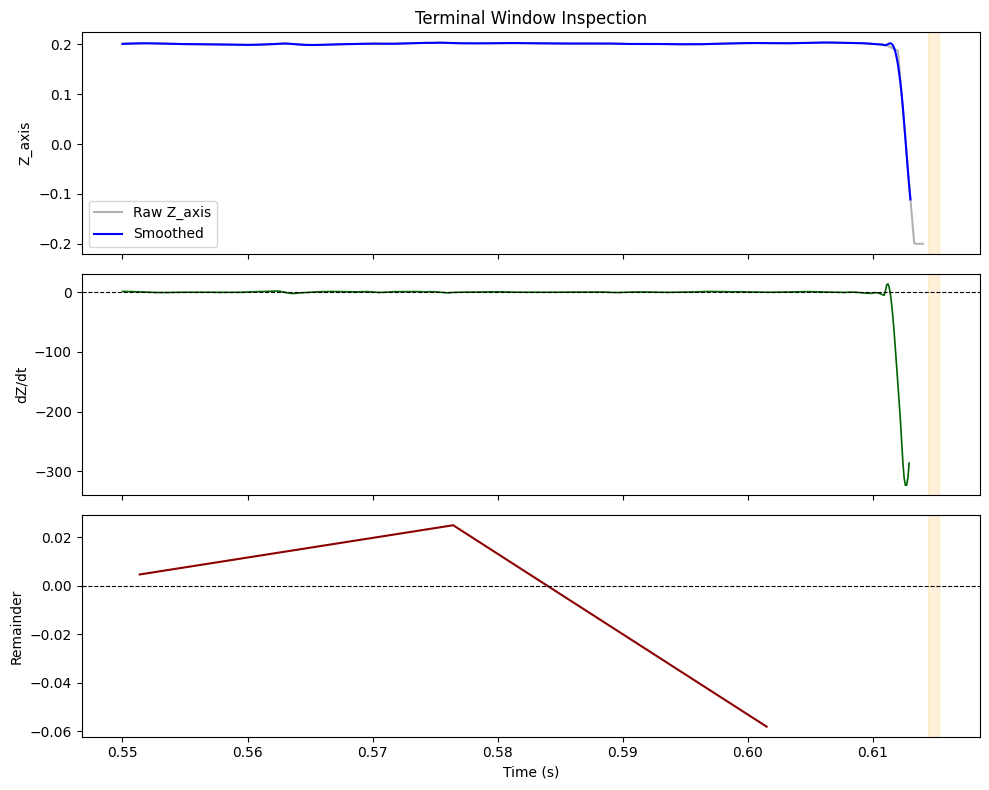

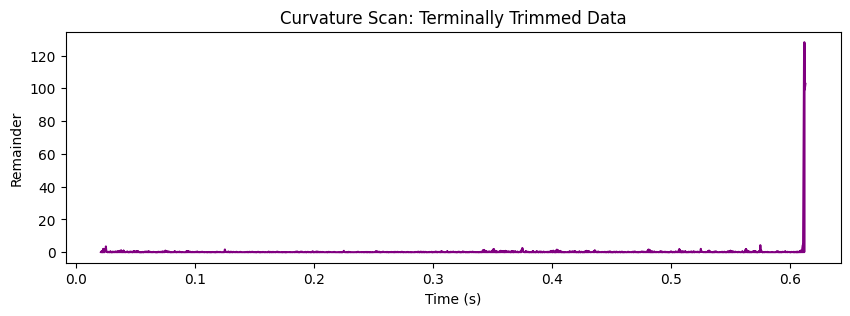

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# 1. Define the zoom and analysis function
def zoom_terminal_curvature(t, z, scan_df, tmin=0.55, tmax=0.62, smooth=True, sg_window=21, polyorder=3, endpoint_margin_pts=10):
    t, z = np.asarray(t), np.asarray(z)
    mask = (t >= tmin) & (t <= tmax)
    tz, zz = t[mask], z[mask]

    if len(tz) < 10:
        print("Too few points in zoom region.")
        return

    zz_s = savgol_filter(zz, sg_window, polyorder) if smooth else zz
    dzdt = np.gradient(zz_s, tz)
    sdf = scan_df[(scan_df["x_mid"] >= tmin) & (scan_df["x_mid"] <= tmax)].copy()

    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(tz, zz, color='gray', alpha=0.6, label='Raw Z_axis'); axes[0].plot(tz, zz_s, color='blue', lw=1.5, label='Smoothed')
    axes[0].set_ylabel("Z_axis"); axes[0].legend(); axes[0].set_title("Terminal Window Inspection")
    axes[1].plot(tz, dzdt, color='darkgreen', lw=1.2, label='dZ/dt'); axes[1].axhline(0, color='black', ls='--', lw=0.8); axes[1].set_ylabel("dZ/dt")
    axes[2].plot(sdf["x_mid"], sdf["remainder"], color='darkred', lw=1.5, label='Remainder'); axes[2].axhline(0, color='black', ls='--', lw=0.8)
    axes[2].set_ylabel("Remainder"); axes[2].set_xlabel("Time (s)")

    if len(tz) > endpoint_margin_pts:
        t_excl = tz[-endpoint_margin_pts]
        for ax in axes: ax.axvspan(t_excl, tz[-1], color='orange', alpha=0.15, label='Endpoint margin')
    plt.tight_layout(); plt.show()

# 2. Prepare Data (Adjust 'df' if your dataframe has a different name)
t = df["time"].to_numpy()
z = df["Z_axis"].to_numpy()

# 3. Run Analysis
zoom_terminal_curvature(t, z, scan_df)

# 4. Sanity Check: Recompute without last 10 points
trim_n = 10
scan_trim = scan_midpoint_remainder(t[:-trim_n], z[:-trim_n])
plt.figure(figsize=(10, 3))
plt.plot(scan_trim['x_mid'], scan_trim['abs_remainder'], color='purple')
plt.title("Curvature Scan: Terminally Trimmed Data")
plt.xlabel("Time (s)"); plt.ylabel("Remainder"); plt.show()

-> True physical transition onset detected at: 5.2130 s


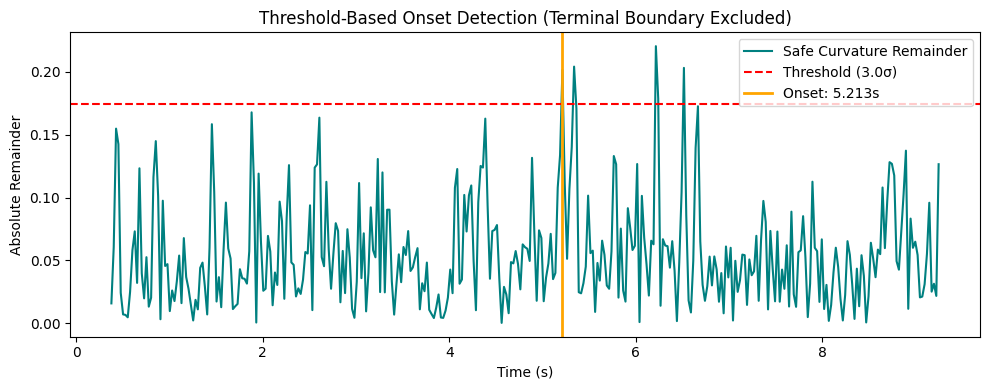

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def analyze_true_onset(t, z, scan_df, threshold_multiplier=3.0, margin_pts=15):
    """
    Finds the true onset of the transition while ignoring terminal boundary artifacts.
    """
    t = np.asarray(t)

    # Exclude the last N points to avoid boundary artifacts
    safe_scan = scan_df.iloc[:-margin_pts].copy()

    # Establish baseline behavior from the quiet phase (e.g., first 50% of the shot)
    baseline_mask = safe_scan["x_mid"] < (safe_scan["x_mid"].max() * 0.5)
    baseline_mean = safe_scan.loc[baseline_mask, "abs_remainder"].mean()
    baseline_std = safe_scan.loc[baseline_mask, "abs_remainder"].std()

    # Define an anomaly threshold
    threshold = baseline_mean + (threshold_multiplier * baseline_std)

    # Find the first point where remainder crosses the threshold outside the baseline
    exceed_mask = (safe_scan["abs_remainder"] > threshold) & (safe_scan["x_mid"] > 0.1)

    if exceed_mask.any():
        onset_idx = exceed_mask.idxmax()
        onset_time = safe_scan.loc[onset_idx, "x_mid"]
        print(f"-> True physical transition onset detected at: {onset_time:.4f} s")
    else:
        onset_time = None
        print("-> No clear transition onset found above threshold before the margin.")

    # Plot the safe, threshold-filtered scan
    plt.figure(figsize=(10, 4))
    plt.plot(safe_scan["x_mid"], safe_scan["abs_remainder"], color='teal', label='Safe Curvature Remainder')
    plt.axhline(threshold, color='red', linestyle='--', label=f'Threshold ({threshold_multiplier}σ)')
    if onset_time:
        plt.axvline(onset_time, color='orange', linestyle='-', lw=2, label=f'Onset: {onset_time:.3f}s')

    plt.title("Threshold-Based Onset Detection (Terminal Boundary Excluded)")
    plt.xlabel("Time (s)")
    plt.ylabel("Absolute Remainder")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Run the analysis using your variables
analyze_true_onset(t=t, z=z, scan_df=scan_df, threshold_multiplier=3.0, margin_pts=15)

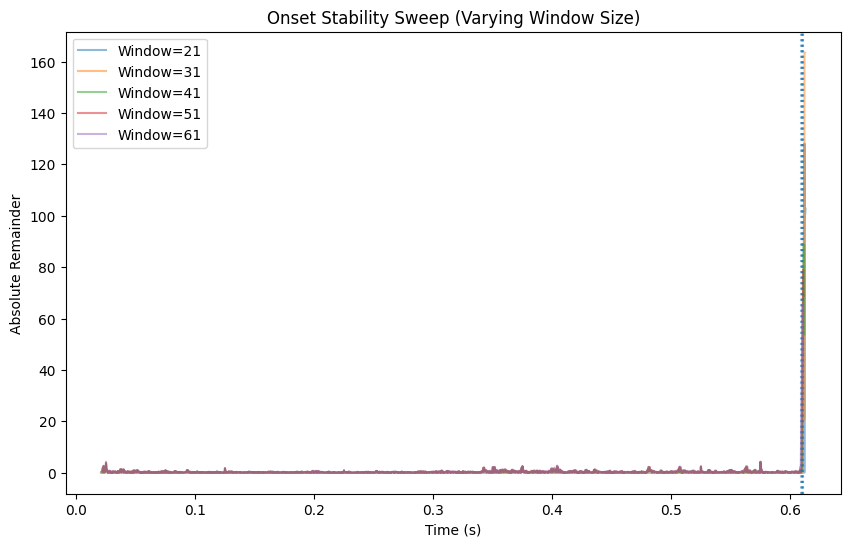

Onset detected at [np.float64(0.6112000000000001), np.float64(0.6107), np.float64(0.6102000000000001), np.float64(0.6097), np.float64(0.6092000000000001)] for window sizes [21, 31, 41, 51, 61]


In [ ]:
# Sweep over a range of window sizes to check onset stability
window_sizes = [21, 31, 41, 51, 61]
onset_times = []

plt.figure(figsize=(10, 6))

for w in window_sizes:
    # Re-run scan logic for different window sizes
    scan_temp = scan_midpoint_remainder(t, z, window_pts=w)

    # Check for threshold crossing
    threshold = scan_temp["abs_remainder"].mean() + (3.0 * scan_temp["abs_remainder"].std())
    exceed = scan_temp[(scan_temp["x_mid"] > 0.1) & (scan_temp["abs_remainder"] > threshold)]

    if not exceed.empty:
        onset = exceed["x_mid"].iloc[0]
        onset_times.append(onset)
        plt.plot(scan_temp["x_mid"], scan_temp["abs_remainder"], alpha=0.5, label=f'Window={w}')
        plt.axvline(onset, linestyle=':', alpha=0.5)

plt.title("Onset Stability Sweep (Varying Window Size)")
plt.xlabel("Time (s)")
plt.ylabel("Absolute Remainder")
plt.legend()
plt.show()

print(f"Onset detected at {onset_times} for window sizes {window_sizes}")

-> No precursor events detected above threshold in the mid-shot.


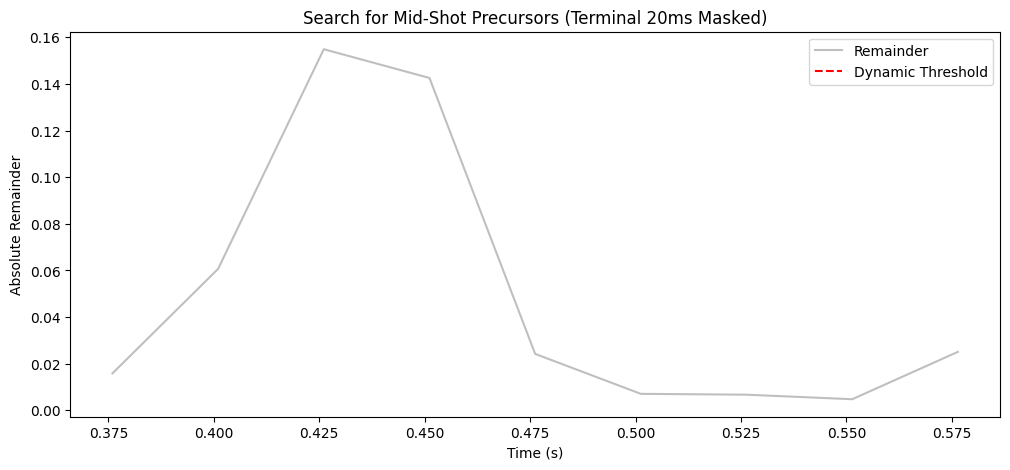

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def search_for_precursors(t, z, scan_df, mask_end_ms=20):
    # 1. Mask out the terminal collapse (last 20ms)
    t_limit = t.max() - (mask_end_ms / 1000.0)
    safe_df = scan_df[scan_df["x_mid"] < t_limit].copy()

    # 2. Define a "quiet" baseline for sensitivity
    # We use a rolling mean and std to detect events that pop out of the noise
    window_size = 50
    safe_df['rolling_mean'] = safe_df['abs_remainder'].rolling(window_size).mean()
    safe_df['rolling_std'] = safe_df['abs_remainder'].rolling(window_size).std()
    safe_df['threshold'] = safe_df['rolling_mean'] + (4.0 * safe_df['rolling_std'])

    # 3. Find peaks that exceed the dynamic threshold
    peaks, _ = find_peaks(safe_df['abs_remainder'], height=safe_df['threshold'].values, distance=20)

    # 4. Plot results
    plt.figure(figsize=(12, 5))
    plt.plot(safe_df['x_mid'], safe_df['abs_remainder'], color='gray', alpha=0.5, label='Remainder')
    plt.plot(safe_df['x_mid'], safe_df['threshold'], color='red', linestyle='--', label='Dynamic Threshold')

    if len(peaks) > 0:
        plt.scatter(safe_df.iloc[peaks]['x_mid'], safe_df.iloc[peaks]['abs_remainder'], color='blue', zorder=5, label='Precursor Candidates')
        print(f"-> Detected {len(peaks)} candidate precursor events before {t_limit:.3f}s")
    else:
        print("-> No precursor events detected above threshold in the mid-shot.")

    plt.title("Search for Mid-Shot Precursors (Terminal 20ms Masked)")
    plt.xlabel("Time (s)")
    plt.ylabel("Absolute Remainder")
    plt.legend()
    plt.show()

# Run the search
search_for_precursors(t, z, scan_df)

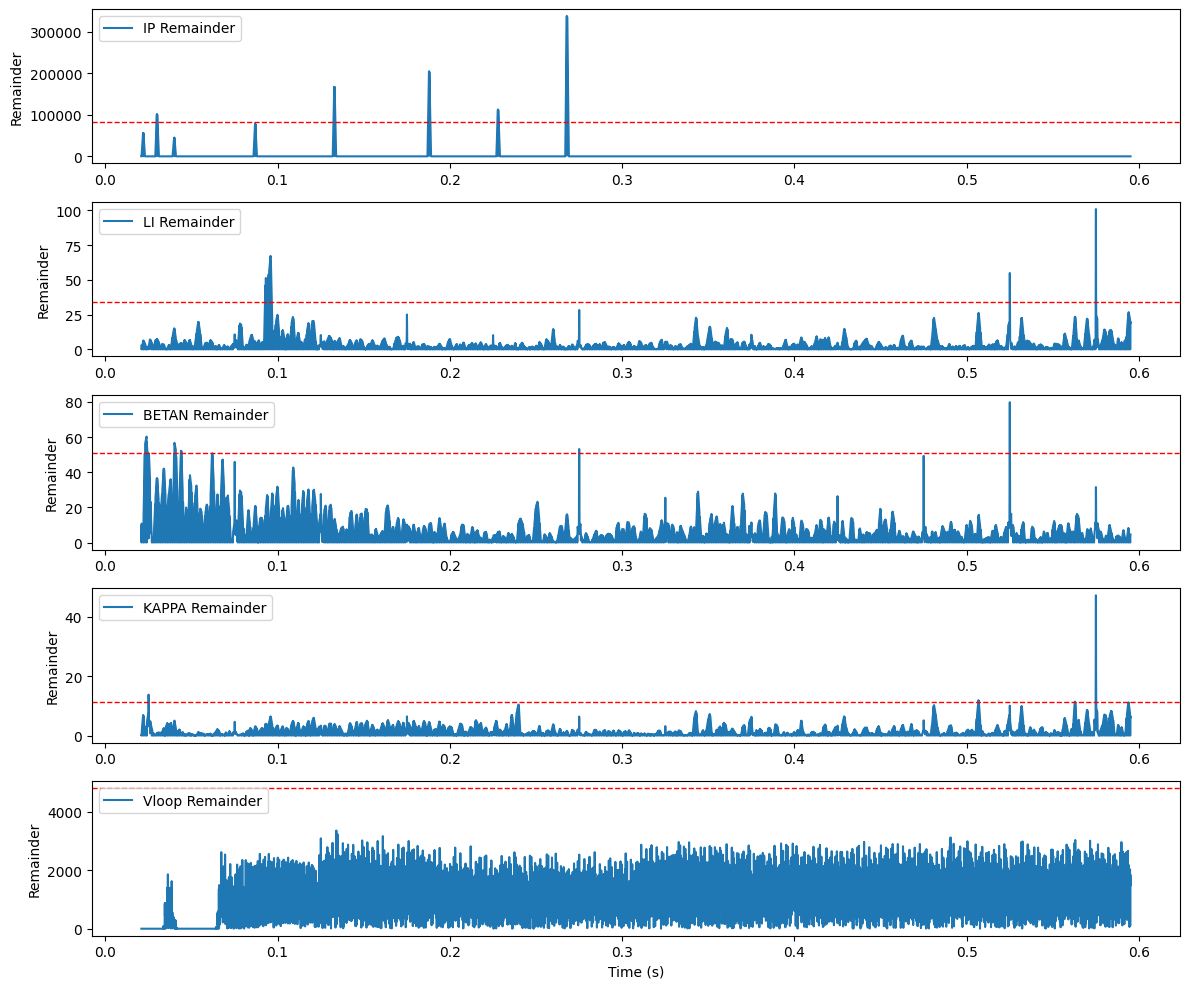

In [ ]:
# List of potential diagnostics to test for precursors
# We skip 'time', 'label_conf' and non-physics columns
test_columns = ['IP', 'LI', 'BETAN', 'KAPPA', 'Vloop']

def multi_channel_precursor_search(df, channels, mask_end_ms=20):
    t_limit = df['time'].max() - (mask_end_ms / 1000.0)

    plt.figure(figsize=(12, 10))

    for i, col in enumerate(channels):
        # Prepare signal
        z = df[col].to_numpy()
        t = df['time'].to_numpy()

        # Re-run scan logic (simplified for the loop)
        scan = scan_midpoint_remainder(t, z) # Assuming this is defined

        # Filter for mid-shot
        mid_scan = scan[scan['x_mid'] < t_limit]

        # Plot
        plt.subplot(len(channels), 1, i+1)
        plt.plot(mid_scan['x_mid'], mid_scan['abs_remainder'], label=f'{col} Remainder')
        plt.axhline(mid_scan['abs_remainder'].mean() + 5*mid_scan['abs_remainder'].std(), color='red', linestyle='--', lw=1)
        plt.ylabel("Remainder")
        plt.legend(loc='upper left')

    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

# Run it
multi_channel_precursor_search(df, test_columns)

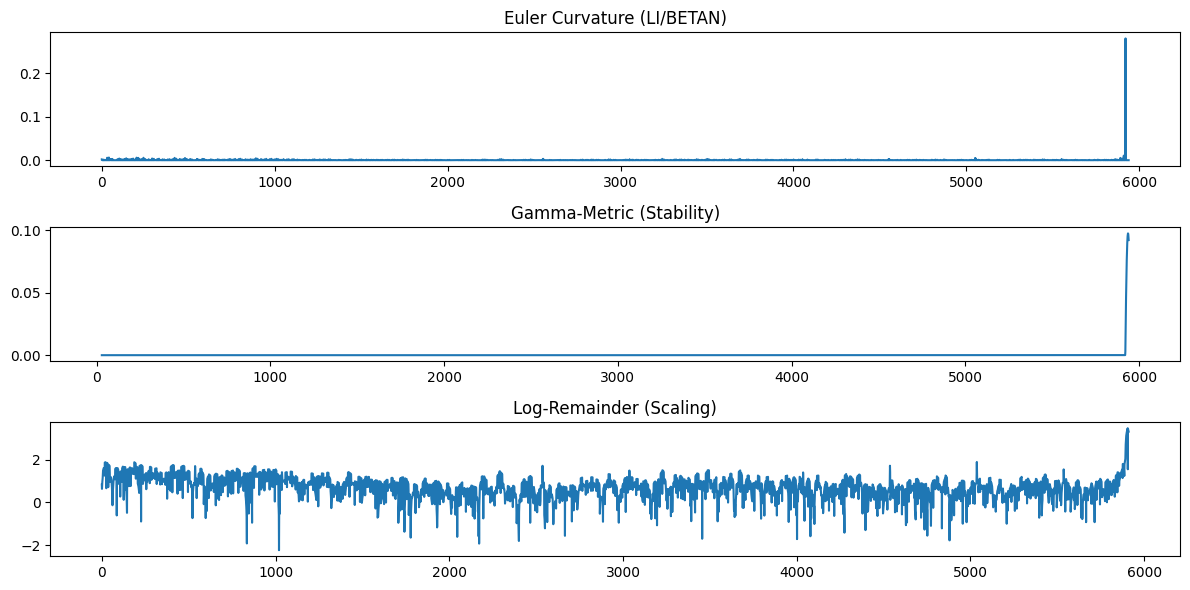

In [ ]:
def compute_advanced_metrics(t, z, window=31):
    z = np.asarray(z)
    # Euler approximation: change in slope
    dz = np.gradient(z)
    ddz = np.gradient(dz)
    euler = np.abs(ddz) / (1 + dz**2)**1.5

    # Gamma: Rolling variance of the derivative
    gamma = pd.Series(dz).rolling(window).var()

    # Log-Remainder (Standard midpoint remainder, then log)
    # (Assuming scan_midpoint_remainder returns a dataframe with 'remainder')
    scan = scan_midpoint_remainder(t, z, window_pts=window)
    log_rem = np.log10(np.abs(scan['remainder']) + 1e-6)

    return euler, gamma, log_rem

# Example for BETAN
t = df['time'].values
z = df['BETAN'].values
euler, gamma, log_rem = compute_advanced_metrics(t, z)

plt.figure(figsize=(12, 6))
plt.subplot(3, 1, 1); plt.plot(euler); plt.title("Euler Curvature (LI/BETAN)")
plt.subplot(3, 1, 2); plt.plot(gamma); plt.title("Gamma-Metric (Stability)")
plt.subplot(3, 1, 3); plt.plot(log_rem); plt.title("Log-Remainder (Scaling)")
plt.tight_layout(); plt.show()

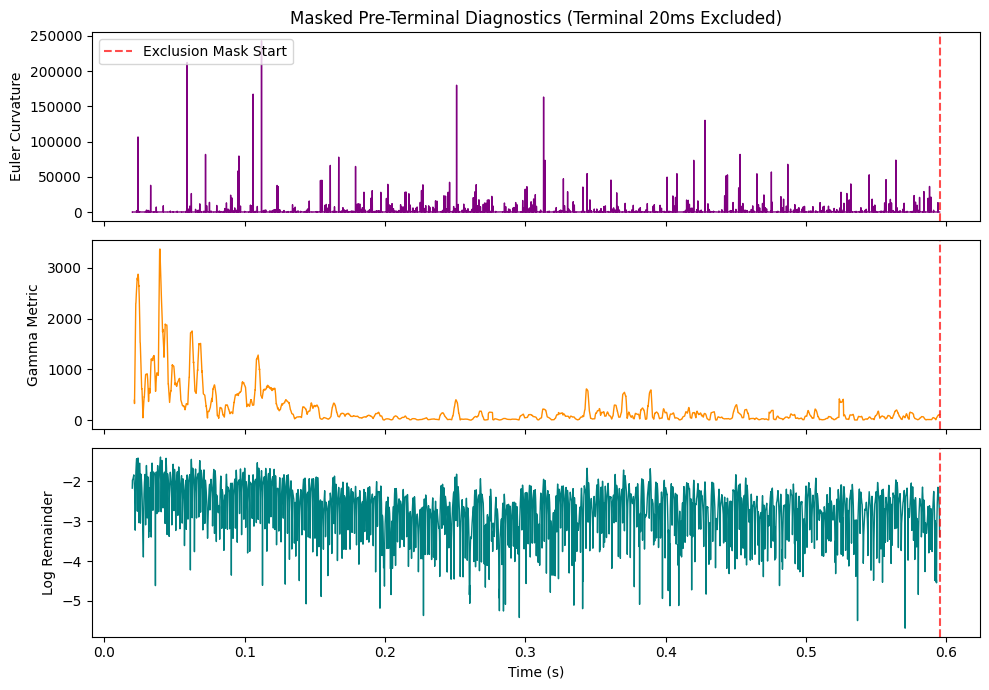

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def analyze_masked_metrics(t, z, window=31, mask_end_ms=20):
    t = np.asarray(t)
    z = np.asarray(z)

    # 1. Compute metrics
    dz = np.gradient(z, t)
    ddz = np.gradient(dz, t)
    euler = np.abs(ddz) / (1.0 + dz**2)**1.5

    gamma = pd.Series(dz).rolling(window, center=True).var().to_numpy()

    # Simple midpoint-style remainder approximation for demonstration
    z_smooth = pd.Series(z).rolling(window, center=True, min_periods=1).mean().to_numpy()
    remainder = np.abs(z - z_smooth)
    log_rem = np.log10(remainder + 1e-6)

    # 2. Mask out terminal boundary
    t_limit = t.max() - (mask_end_ms / 1000.0)
    safe_mask = t < t_limit

    tz_safe = t[safe_mask]
    euler_safe = euler[safe_mask]
    gamma_safe = gamma[safe_mask]
    log_safe = log_rem[safe_mask]

    # 3. Plot masked metrics to check for hidden sub-terminal precursors
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

    axes[0].plot(tz_safe, euler_safe, color='purple', lw=1)
    axes[0].set_ylabel("Euler Curvature")
    axes[0].set_title("Masked Pre-Terminal Diagnostics (Terminal 20ms Excluded)")

    axes[1].plot(tz_safe, gamma_safe, color='darkorange', lw=1)
    axes[1].set_ylabel("Gamma Metric")

    axes[2].plot(tz_safe, log_safe, color='teal', lw=1)
    axes[2].set_ylabel("Log Remainder")
    axes[2].set_xlabel("Time (s)")

    for ax in axes:
        ax.axvline(t_limit, color='red', linestyle='--', alpha=0.7, label='Exclusion Mask Start')

    axes[0].legend(loc='upper left')
    plt.tight_layout()
    plt.show()

# Run the masked analysis on BETAN
analyze_masked_metrics(t=df['time'].values, z=df['BETAN'].values)

--- Pre-terminal Trend Analysis (last 100ms) ---
Euler Slope: 0.588147 (Higher means increasing structural instability)
Gamma Slope: -0.023509 (Higher means increasing turbulence/jitter)


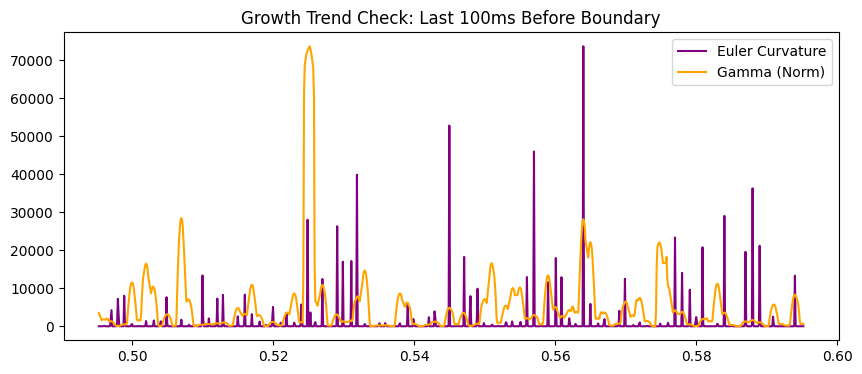

In [ ]:
def quantify_precursor_contrast(t, z, mask_end_ms=20, lookback_ms=100):
    t = np.asarray(t)
    z = np.asarray(z)

    # Define time window for pre-terminal search
    t_end = t.max() - (mask_end_ms / 1000.0)
    t_start = t_end - (lookback_ms / 1000.0)

    # Extract data in the 100ms lookback window
    mask = (t >= t_start) & (t < t_end)
    t_sub = t[mask]

    # Re-calculate metrics (simplified)
    dz = np.gradient(z, t)
    ddz = np.gradient(dz, t)
    euler = np.abs(ddz) / (1.0 + dz**2)**1.5
    gamma = pd.Series(dz).rolling(15, center=True).var().to_numpy()

    # Calculate Linear Trend (Slope) of the metrics
    # A positive slope indicates a growing precursor
    def get_slope(y):
        x = np.arange(len(y))
        return np.polyfit(x, y, 1)[0]

    e_slope = get_slope(euler[mask])
    g_slope = get_slope(gamma[mask])

    print(f"--- Pre-terminal Trend Analysis (last {lookback_ms}ms) ---")
    print(f"Euler Slope: {e_slope:.6f} (Higher means increasing structural instability)")
    print(f"Gamma Slope: {g_slope:.6f} (Higher means increasing turbulence/jitter)")

    # Final check: Is the slope statistically significant compared to the shot baseline?
    # This determines if the "growth" is real or just typical fluctuation
    plt.figure(figsize=(10, 4))
    plt.plot(t_sub, euler[mask], label='Euler Curvature', color='purple')
    plt.plot(t_sub, gamma[mask] / np.max(gamma[mask]) * np.max(euler[mask]), label='Gamma (Norm)', color='orange')
    plt.title("Growth Trend Check: Last 100ms Before Boundary")
    plt.legend(); plt.show()

# Run the contrast test
quantify_precursor_contrast(t=df['time'].values, z=df['BETAN'].values)

In [ ]:
import os, glob

print("Current working directory:", os.getcwd())

candidate_dirs = [
    ".",
    "./data",
    "/content",
    "/content/data",
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/data"
]

for d in candidate_dirs:
    if os.path.exists(d):
        print(f"\nDirectory: {d}")
        items = sorted(os.listdir(d))[:20]
        for x in items:
            print("  ", x)

print("\nCSV search:")
for pat in ["./*.csv", "./data/*.csv", "/content/*.csv", "/content/data/*.csv", "/content/drive/MyDrive/**/*.csv"]:
    matches = glob.glob(pat, recursive=True)
    print(pat, "->", len(matches))
    for m in matches[:10]:
        print("   ", m)

Current working directory: /content

Directory: .
   .config
   data
   data.zip
   lhdatabase.h5
   sample_data

Directory: ./data
   TCV_confstate_26386.parquet
   TCV_confstate_29511.parquet
   TCV_confstate_30043.parquet
   TCV_confstate_30197.parquet
   TCV_confstate_30225.parquet
   TCV_confstate_30262.parquet
   TCV_confstate_30268.parquet
   TCV_confstate_30290.parquet
   TCV_confstate_30310.parquet
   TCV_confstate_31211.parquet
   TCV_confstate_31554.parquet
   TCV_confstate_31650.parquet
   TCV_confstate_31718.parquet
   TCV_confstate_31807.parquet
   TCV_confstate_31839.parquet
   TCV_confstate_32191.parquet
   TCV_confstate_32195.parquet
   TCV_confstate_32592.parquet
   TCV_confstate_32716.parquet
   TCV_confstate_32911.parquet

Directory: /content
   .config
   data
   data.zip
   lhdatabase.h5
   sample_data

Directory: /content/data
   TCV_confstate_26386.parquet
   TCV_confstate_29511.parquet
   TCV_confstate_30043.parquet
   TCV_confstate_30197.parquet
   TCV_confsta

In [ ]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# CONFIG
# =========================================================
DATA_DIR = "/content/data"
FILE_PATTERN = "*.parquet"
SIGNAL = "BETAN"
TERMINAL_MASK_S = 0.02   # exclude last 20 ms
TREND_WINDOW_S = 0.10    # analyze previous 100 ms

# =========================================================
# HELPERS
# =========================================================
def _find_time_col(df):
    for c in ["time", "Time", "t"]:
        if c in df.columns:
            return c
    raise KeyError(f"No time column found. Available columns: {list(df.columns)[:20]}")

def _extract_shot_number(path):
    m = re.search(r'(\d+)', os.path.basename(path))
    return int(m.group(1)) if m else None

def load_shot_data(shot):
    files = sorted(glob.glob(os.path.join(DATA_DIR, FILE_PATTERN)))
    if not files:
        raise FileNotFoundError(f"No files found in {DATA_DIR} matching {FILE_PATTERN}")

    # Match file containing this shot number
    shot = int(shot)
    matches = [f for f in files if _extract_shot_number(f) == shot]
    if not matches:
        raise FileNotFoundError(f"No parquet file found for shot {shot}")

    df = pd.read_parquet(matches[0])

    time_col = _find_time_col(df)
    if SIGNAL not in df.columns:
        raise KeyError(f"{SIGNAL} not found in {matches[0]}. Available columns: {list(df.columns)[:30]}")

    return df.rename(columns={time_col: "time"})[["time", SIGNAL]]

def batch_precursor_analysis(
    shot_list,
    signal=SIGNAL,
    terminal_mask_s=TERMINAL_MASK_S,
    trend_window_s=TREND_WINDOW_S
):
    results = []

    for shot in shot_list:
        try:
            df = load_shot_data(shot)

            t = np.asarray(df["time"].values, dtype=float)
            z = np.asarray(df[signal].values, dtype=float)

            valid = np.isfinite(t) & np.isfinite(z)
            t, z = t[valid], z[valid]

            if len(t) < 10:
                results.append({
                    "shot": shot, "euler_slope": np.nan, "npts": len(t),
                    "t0": np.nan, "t1": np.nan, "status": "too few valid points"
                })
                continue

            order = np.argsort(t)
            t, z = t[order], z[order]

            t1 = np.max(t) - terminal_mask_s
            t0 = t1 - trend_window_s
            mask = (t >= t0) & (t < t1)

            if np.sum(mask) < 10:
                results.append({
                    "shot": shot, "euler_slope": np.nan, "npts": int(np.sum(mask)),
                    "t0": t0, "t1": t1, "status": "too few points in analysis window"
                })
                continue

            tw = t[mask]
            zw = z[mask]

            dz = np.gradient(zw, tw)
            ddz = np.gradient(dz, tw)
            euler = np.abs(ddz) / np.power(1.0 + dz**2, 1.5)

            x = np.arange(len(euler), dtype=float)
            slope = np.polyfit(x, euler, 1)[0]

            results.append({
                "shot": shot,
                "euler_slope": slope,
                "npts": len(euler),
                "t0": t0,
                "t1": t1,
                "status": "ok"
            })

        except Exception as e:
            results.append({
                "shot": shot,
                "euler_slope": np.nan,
                "npts": 0,
                "t0": np.nan,
                "t1": np.nan,
                "status": f"error: {e}"
            })

    return pd.DataFrame(results)

# =========================================================
# AUTO-DETECT SHOTS FROM FILENAMES
# =========================================================
files = sorted(glob.glob(os.path.join(DATA_DIR, FILE_PATTERN)))
shot_list = sorted([_extract_shot_number(f) for f in files if _extract_shot_number(f) is not None])

print(f"Found {len(shot_list)} shot files")
print("First 10 shots:", shot_list[:10])

# =========================================================
# RUN
# =========================================================
all_shots_analysis = batch_precursor_analysis(
    shot_list=shot_list,
    signal=SIGNAL,
    terminal_mask_s=TERMINAL_MASK_S,
    trend_window_s=TREND_WINDOW_S
)

display(all_shots_analysis.head())
print(all_shots_analysis["status"].value_counts(dropna=False))

valid = all_shots_analysis.query("status == 'ok' and euler_slope == euler_slope").copy()

plt.figure(figsize=(8, 4))
plt.hist(valid["euler_slope"], bins=30, color="purple", alpha=0.75, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", linewidth=1.5)
plt.title(f"Distribution of Pre-Terminal Euler Slopes Across Shots ({SIGNAL})")
plt.xlabel("Euler Slope")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("Valid shots:", len(valid))
if len(valid):
    print("Fraction with positive slope:", (valid["euler_slope"] > 0).mean())
    print(valid["euler_slope"].describe())
else:
    print("No valid shots processed.")

# Optional: inspect strongest positive-slope shots
if len(valid):
    print("\nTop 10 positive-slope shots:")
    display(valid.sort_values("euler_slope", ascending=False).head(10))

Found 302 shot files
First 10 shots: [26386, 29511, 30043, 30197, 30225, 30262, 30268, 30290, 30310, 31211]


Feature table shape: (302, 43)
status_feat
ok    302
Name: count, dtype: int64


,shot,euler_slope,npts,t0_x,t1_x,status,group,status_feat,n_win,t0_y,...,euler_s_mean,euler_s_std,euler_s_med,euler_s_max,euler_s_p95,euler_s_p99,euler_s_slope,euler_s_burst_count,euler_s_run_hi,is_gold
0,26386,0.151412,1000,1.9278,2.0278,ok,neutral,ok,1000,1.9278,...,331.645626,2960.234288,0.082009,77976.903515,381.984029,10387.602268,-0.806413,376,6,0
1,29511,0.283954,1000,1.2740,1.3740,ok,neutral,ok,1000,1.2740,...,624.345935,3502.899191,6.984219,96807.846396,3096.598171,9582.554955,1.166862,347,3,0
2,30043,0.611276,1000,1.7660,1.8660,ok,neutral,ok,1000,1.7660,...,992.493146,5902.938962,28.674331,168931.961226,5387.202169,13698.379818,-0.688461,285,2,0
3,30197,1.798312,1000,1.7560,1.8560,ok,positive,ok,1000,1.7560,...,939.473203,3662.387928,23.893016,52172.414568,4352.433866,17419.690140,0.601011,292,2,1
4,30225,0.592779,999,0.4940,0.5940,ok,neutral,ok,999,0.4940,...,654.111963,1669.654616,48.606591,14579.352462,3464.549603,8767.725810,-0.014219,294,3,0



Top differentiating late-window features:


,feature,gold_median,rest_median,gold_mean,rest_mean,std_diff_d,abs_std_diff_d,n_gold,n_rest
0,euler_slope,1.389941e+00,-3.171075e-01,2.651647e+00,-3.806671e-01,1.386743,1.386743,88,214
33,euler_slope_raw,1.389941e+00,-3.171075e-01,2.651647e+00,-3.806671e-01,1.386743,1.386743,88,214
30,euler_max,2.702760e+05,1.579329e+05,4.849893e+05,1.899194e+05,0.962623,0.962623,88,214
28,euler_std,1.198922e+04,8.561216e+03,1.878835e+04,9.085479e+03,0.948697,0.948697,88,214
27,euler_mean,1.299764e+03,9.820354e+02,1.459187e+03,9.855460e+02,0.839151,0.839151,88,214
29,euler_med,1.056598e-11,1.267524e-11,2.121002e-11,4.580179e-11,-0.305228,0.305228,88,214
40,euler_s_p95,4.414293e+03,3.944790e+03,4.260271e+03,3.741707e+03,0.293941,0.293941,88,214
43,euler_s_burst_count,2.850000e+02,2.800000e+02,2.837159e+02,2.761682e+02,0.253699,0.253699,88,214
8,z_end,1.070156e+00,1.051830e+00,9.244545e-01,1.043119e+00,-0.252914,0.252914,88,214
26,frac_down,4.469469e-01,4.614615e-01,4.342729e-01,4.587927e-01,-0.251912,0.251912,88,214



Median of top differentiating features by group:


group,negative,neutral,positive
euler_slope,-1.105579e+00,-5.779311e-02,1.389941e+00
euler_slope_raw,-1.105579e+00,-5.779311e-02,1.389941e+00
euler_max,2.079583e+05,1.457835e+05,2.702760e+05
euler_std,9.592062e+03,7.573479e+03,1.198922e+04
euler_mean,1.061740e+03,9.114110e+02,1.299764e+03
euler_med,7.891235e-12,1.545098e-11,1.056598e-11
euler_s_p95,4.287258e+03,3.853012e+03,4.414293e+03
euler_s_burst_count,2.845000e+02,2.800000e+02,2.850000e+02
z_end,9.151575e-01,1.107212e+00,1.070156e+00
frac_down,4.804805e-01,4.559560e-01,4.469469e-01


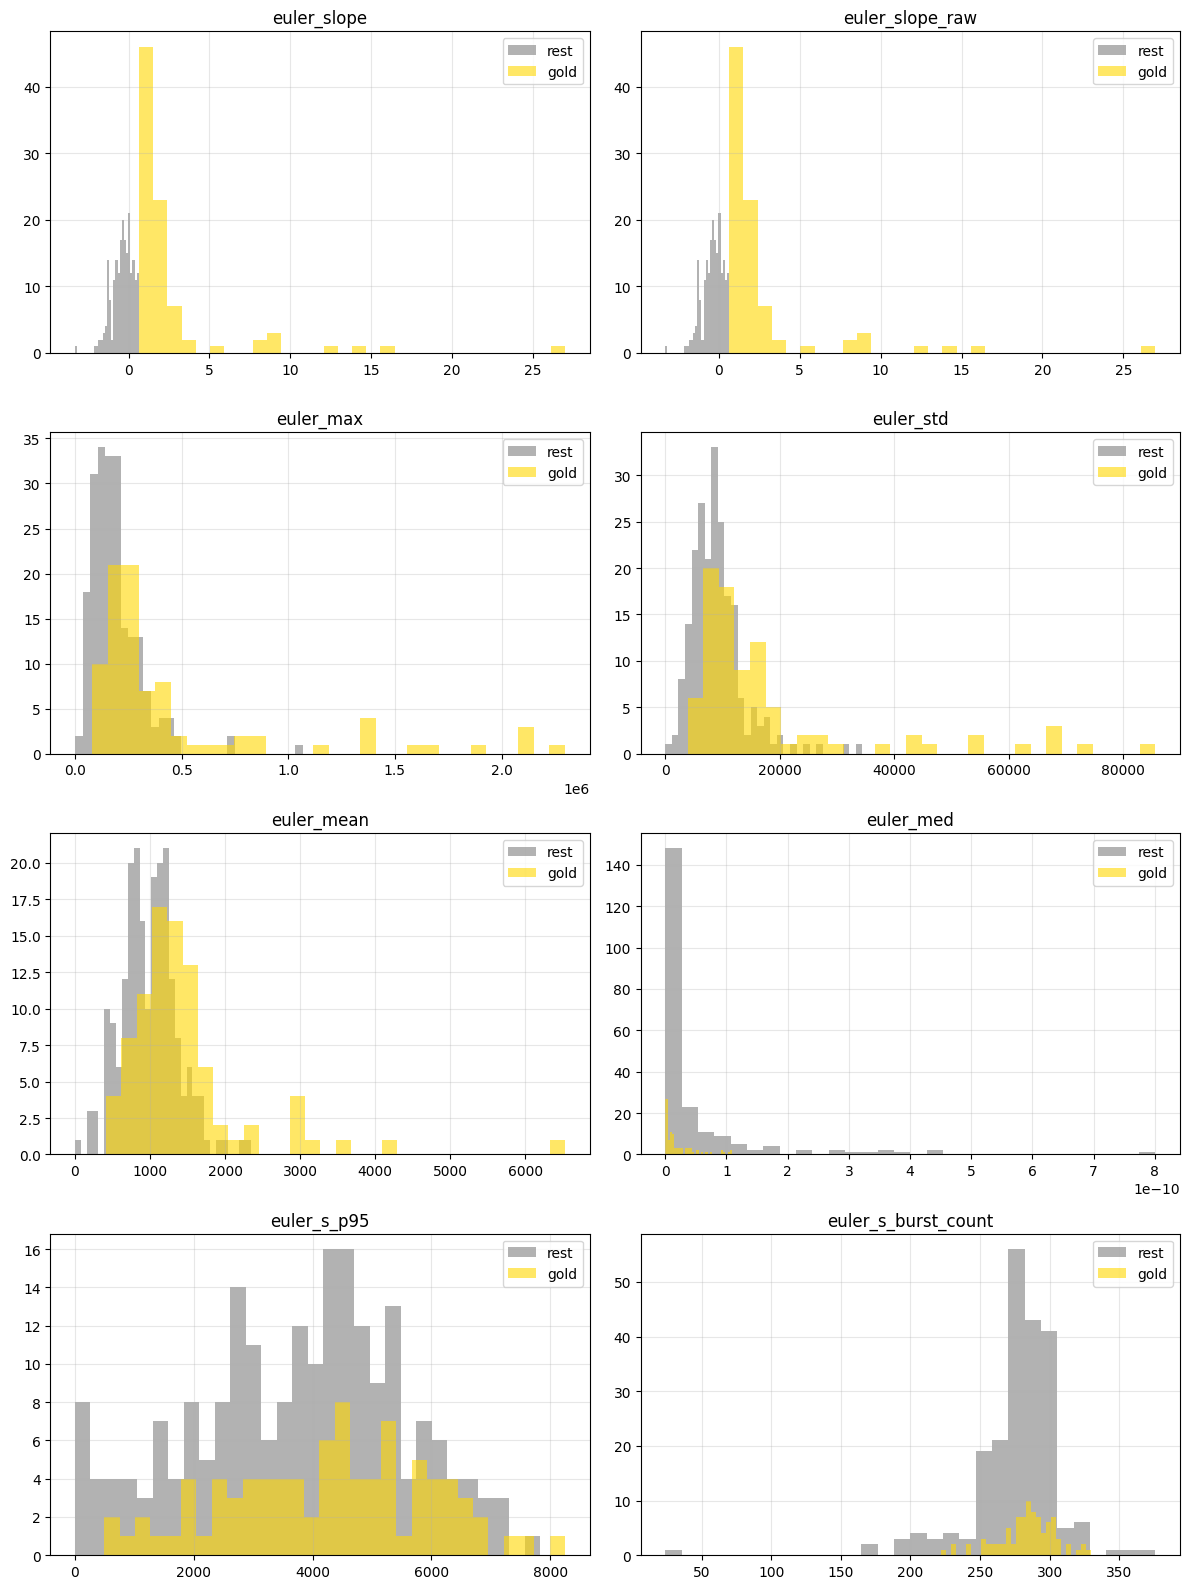


Top gold shots with richer late-window features:


,shot,euler_slope,delta_raw,delta_smooth,slope_raw,slope_smooth,peak_to_end_drop,euler_p95,euler_p99,euler_burst_count,euler_s_p95,euler_s_p99,euler_s_burst_count,std_ratio_2nd_to_1st
240,68268,26.991400,0.188723,0.071234,0.000074,0.000072,0.000000,2309.752349,47067.937932,454,6461.867157,12662.859694,266,6.301474
142,63877,16.160858,0.055309,0.036399,0.000015,0.000013,0.081692,3161.206049,38717.961769,448,5687.232967,12378.611400,272,11.828665
96,61060,14.309357,-0.489384,-0.259585,0.000204,0.000212,0.845687,1902.762633,37130.417954,453,4583.380851,14887.230773,286,6.954096
55,57103,12.285893,-0.400118,-0.205419,0.000221,0.000228,0.842627,1068.065956,43310.838460,453,4255.163393,14719.856073,299,5.122484
37,53601,9.331746,-0.481033,-0.248816,0.000246,0.000253,0.965423,808.813718,43622.963541,466,5568.631583,15532.827999,298,5.018909
116,61714,9.151430,-0.538227,-0.280270,-0.000105,-0.000096,0.858197,1167.203465,19976.670662,442,4161.049176,12431.338498,302,13.738999
43,57000,8.614648,-0.428453,-0.226387,0.000131,0.000138,0.795633,800.264419,13472.066584,437,5075.540816,13210.014428,289,7.028131
117,61716,8.390526,-0.518270,-0.272761,-0.000047,-0.000039,0.868626,1050.431505,42004.459937,445,5276.391900,12317.223802,306,11.621133
29,42514,8.347799,-1.045685,-0.553627,-0.001096,-0.001080,1.150812,829.698311,11390.290792,457,2938.144635,11657.875241,326,5.223376
115,61713,5.382497,-0.514088,-0.271398,-0.000043,-0.000035,0.822028,1378.512136,18817.807875,436,5209.378687,13289.685918,260,13.730160


In [ ]:
# Compute richer late-window dynamical features for all shots
# and compare gold (positive group) vs rest.
#
# Assumes you already have:
#   - valid  (columns include shot, euler_slope, group)
#   - load_shot_data(...)
#   - SIGNAL, TERMINAL_MASK_S, TREND_WINDOW_S

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# helpers
# -------------------------------------------------------
def moving_average(x, w=21):
    x = np.asarray(x, dtype=float)
    if w < 3 or len(x) < w:
        return x.copy()
    kernel = np.ones(w) / w
    y = np.convolve(x, kernel, mode="same")
    return y

def robust_burst_count(x, z_thresh=3.5):
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if not np.isfinite(mad) or mad == 0:
        return 0
    z = 0.6745 * (x - med) / mad
    return int(np.sum(np.abs(z) > z_thresh))

def longest_run_above(x, thresh):
    x = np.asarray(x, dtype=float)
    mask = x > thresh
    best = run = 0
    for v in mask:
        if v:
            run += 1
            if run > best:
                best = run
        else:
            run = 0
    return int(best)

def safe_polyfit_slope(y):
    y = np.asarray(y, dtype=float)
    if len(y) < 3 or not np.all(np.isfinite(y)):
        return np.nan
    x = np.arange(len(y), dtype=float)
    return np.polyfit(x, y, 1)[0]

# -------------------------------------------------------
# feature extractor
# -------------------------------------------------------
def extract_window_features(shot, signal=SIGNAL,
                            terminal_mask_s=TERMINAL_MASK_S,
                            trend_window_s=TREND_WINDOW_S,
                            smooth_w=21):
    df_shot = load_shot_data(int(shot))

    t = np.asarray(df_shot["time"].values, dtype=float)
    z = np.asarray(df_shot[signal].values, dtype=float)

    good = np.isfinite(t) & np.isfinite(z)
    t, z = t[good], z[good]

    if len(t) < 20:
        return {"shot": shot, "status_feat": "too few valid points"}

    order = np.argsort(t)
    t, z = t[order], z[order]

    t1 = np.max(t) - terminal_mask_s
    t0 = t1 - trend_window_s
    mask = (t >= t0) & (t < t1)

    tw = t[mask]
    zw = z[mask]

    if len(tw) < 20:
        return {"shot": shot, "status_feat": "too few points in window"}

    # normalized time
    trel_ms = (tw - t0) * 1e3

    # basic raw signal features
    z_start = zw[0]
    z_end = zw[-1]
    z_min = np.nanmin(zw)
    z_max = np.nanmax(zw)
    z_mean = np.nanmean(zw)
    z_std = np.nanstd(zw)
    z_range = z_max - z_min

    # piecewise window stats
    n = len(zw)
    half = n // 2
    first = zw[:half]
    second = zw[half:]

    # smoothed signal
    zs = moving_average(zw, w=smooth_w)

    # slopes
    slope_raw = safe_polyfit_slope(zw)
    slope_smooth = safe_polyfit_slope(zs)

    # endpoint changes
    delta_raw = z_end - z_start
    delta_smooth = zs[-1] - zs[0]

    # local derivatives
    dz = np.gradient(zw, tw)
    ddz = np.gradient(dz, tw)

    dzs = np.gradient(zs, tw)
    ddzs = np.gradient(dzs, tw)

    # Euler curvature
    euler = np.abs(ddz) / np.power(1.0 + dz**2, 1.5)
    euler_s = np.abs(ddzs) / np.power(1.0 + dzs**2, 1.5)

    # curvature features
    euler_mean = np.nanmean(euler)
    euler_std = np.nanstd(euler)
    euler_max = np.nanmax(euler)
    euler_p95 = np.nanpercentile(euler, 95)
    euler_p99 = np.nanpercentile(euler, 99)
    euler_med = np.nanmedian(euler)
    euler_slope_raw = safe_polyfit_slope(euler)

    euler_s_mean = np.nanmean(euler_s)
    euler_s_std = np.nanstd(euler_s)
    euler_s_max = np.nanmax(euler_s)
    euler_s_p95 = np.nanpercentile(euler_s, 95)
    euler_s_p99 = np.nanpercentile(euler_s, 99)
    euler_s_med = np.nanmedian(euler_s)
    euler_s_slope = safe_polyfit_slope(euler_s)

    # spike / burst metrics
    euler_burst_count = robust_burst_count(euler, z_thresh=3.5)
    euler_s_burst_count = robust_burst_count(euler_s, z_thresh=3.5)

    euler_run_hi = longest_run_above(euler, euler_p95)
    euler_s_run_hi = longest_run_above(euler_s, euler_s_p95)

    # variance shift
    first_std = np.nanstd(first)
    second_std = np.nanstd(second)
    std_ratio_2nd_to_1st = second_std / first_std if first_std > 0 else np.nan

    # drop metrics
    peak_to_end_drop = z_max - z_end
    mean_second_minus_first = np.nanmean(second) - np.nanmean(first)

    # rough monotonicity
    frac_up = np.mean(np.diff(zw) > 0) if len(zw) > 1 else np.nan
    frac_down = np.mean(np.diff(zw) < 0) if len(zw) > 1 else np.nan

    return {
        "shot": shot,
        "status_feat": "ok",
        "n_win": len(zw),
        "t0": t0,
        "t1": t1,
        "z_start": z_start,
        "z_end": z_end,
        "z_mean": z_mean,
        "z_std": z_std,
        "z_min": z_min,
        "z_max": z_max,
        "z_range": z_range,
        "delta_raw": delta_raw,
        "delta_smooth": delta_smooth,
        "slope_raw": slope_raw,
        "slope_smooth": slope_smooth,
        "first_half_mean": np.nanmean(first),
        "second_half_mean": np.nanmean(second),
        "mean_second_minus_first": mean_second_minus_first,
        "first_half_std": first_std,
        "second_half_std": second_std,
        "std_ratio_2nd_to_1st": std_ratio_2nd_to_1st,
        "peak_to_end_drop": peak_to_end_drop,
        "frac_up": frac_up,
        "frac_down": frac_down,
        "euler_mean": euler_mean,
        "euler_std": euler_std,
        "euler_med": euler_med,
        "euler_max": euler_max,
        "euler_p95": euler_p95,
        "euler_p99": euler_p99,
        "euler_slope_raw": euler_slope_raw,
        "euler_burst_count": euler_burst_count,
        "euler_run_hi": euler_run_hi,
        "euler_s_mean": euler_s_mean,
        "euler_s_std": euler_s_std,
        "euler_s_med": euler_s_med,
        "euler_s_max": euler_s_max,
        "euler_s_p95": euler_s_p95,
        "euler_s_p99": euler_s_p99,
        "euler_s_slope": euler_s_slope,
        "euler_s_burst_count": euler_s_burst_count,
        "euler_s_run_hi": euler_s_run_hi,
    }

# -------------------------------------------------------
# run over all valid shots
# -------------------------------------------------------
feat_rows = [extract_window_features(int(s)) for s in valid["shot"].tolist()]
feat = pd.DataFrame(feat_rows)

print("Feature table shape:", feat.shape)
print(feat["status_feat"].value_counts(dropna=False))

cmp2 = valid.merge(feat, on="shot", how="left")
cmp2["is_gold"] = (cmp2["group"] == "positive").astype(int)

display(cmp2.head())

# -------------------------------------------------------
# compare gold vs rest by standardized difference
# -------------------------------------------------------
exclude_cols = {"shot", "status", "group", "status_feat", "is_gold"}
num_cols = [c for c in cmp2.columns if c not in exclude_cols and pd.api.types.is_numeric_dtype(cmp2[c])]

rows = []
for col in num_cols:
    a = cmp2.loc[cmp2["is_gold"] == 1, col].dropna().values
    b = cmp2.loc[cmp2["is_gold"] == 0, col].dropna().values
    if len(a) < 5 or len(b) < 5:
        continue

    mean_a, mean_b = np.mean(a), np.mean(b)
    med_a, med_b = np.median(a), np.median(b)
    sa, sb = np.std(a, ddof=1), np.std(b, ddof=1)
    pooled = np.sqrt(((len(a)-1)*sa**2 + (len(b)-1)*sb**2) / (len(a)+len(b)-2)) if (len(a)+len(b)-2) > 0 else np.nan
    d = (mean_a - mean_b) / pooled if np.isfinite(pooled) and pooled > 0 else np.nan

    rows.append({
        "feature": col,
        "gold_median": med_a,
        "rest_median": med_b,
        "gold_mean": mean_a,
        "rest_mean": mean_b,
        "std_diff_d": d,
        "abs_std_diff_d": np.abs(d),
        "n_gold": len(a),
        "n_rest": len(b)
    })

effects2 = pd.DataFrame(rows).sort_values("abs_std_diff_d", ascending=False)

print("\nTop differentiating late-window features:")
display(effects2.head(20))

# -------------------------------------------------------
# grouped medians for best features
# -------------------------------------------------------
top_feats = effects2["feature"].head(12).tolist()
group_summary = cmp2.groupby("group")[top_feats].median(numeric_only=True).T

print("\nMedian of top differentiating features by group:")
display(group_summary)

# -------------------------------------------------------
# histograms for top features
# -------------------------------------------------------
plot_feats = effects2["feature"].head(8).tolist()
if plot_feats:
    n = len(plot_feats)
    nrows = (n + 1) // 2
    fig, axes = plt.subplots(nrows, 2, figsize=(12, 4 * nrows))
    axes = np.ravel(axes)

    for ax, col in zip(axes, plot_feats):
        gold = cmp2.loc[cmp2["is_gold"] == 1, col].dropna()
        rest = cmp2.loc[cmp2["is_gold"] == 0, col].dropna()

        ax.hist(rest, bins=30, alpha=0.6, label="rest", color="gray")
        ax.hist(gold, bins=30, alpha=0.6, label="gold", color="gold")
        ax.set_title(col)
        ax.grid(alpha=0.3)
        ax.legend()

    for j in range(len(plot_feats), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

# -------------------------------------------------------
# optional: show strongest gold shots with selected features
# -------------------------------------------------------
show_cols = ["shot", "euler_slope"]
for c in ["delta_raw", "delta_smooth", "slope_raw", "slope_smooth",
          "peak_to_end_drop", "euler_p95", "euler_p99", "euler_burst_count",
          "euler_s_p95", "euler_s_p99", "euler_s_burst_count", "std_ratio_2nd_to_1st"]:
    if c in cmp2.columns:
        show_cols.append(c)

print("\nTop gold shots with richer late-window features:")
display(cmp2.loc[cmp2["group"] == "positive", show_cols]
        .sort_values("euler_slope", ascending=False)
        .head(20))

In [ ]:
# Robustness test:
# Recompute late-window curvature features under multiple preprocessing settings
# and check whether "gold" shots remain gold.
#
# Assumes you already have:
#   - valid   (columns: shot, euler_slope, group)
#   - load_shot_data(...)
#   - SIGNAL, TERMINAL_MASK_S, TREND_WINDOW_S
#
# This cell:
#   1) computes a baseline robust curvature slope
#   2) repeats under several smoothing/downsampling settings
#   3) measures rank stability and gold-overlap stability
#   4) plots results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# helpers
# -------------------------------------------------------
def moving_average(x, w=21):
    x = np.asarray(x, dtype=float)
    if w < 3 or len(x) < w:
        return x.copy()
    kern = np.ones(w) / w
    return np.convolve(x, kern, mode="same")

def safe_polyfit_slope(y):
    y = np.asarray(y, dtype=float)
    if len(y) < 3 or not np.all(np.isfinite(y)):
        return np.nan
    x = np.arange(len(y), dtype=float)
    return np.polyfit(x, y, 1)[0]

def get_window_signal(shot, signal=SIGNAL,
                      terminal_mask_s=TERMINAL_MASK_S,
                      trend_window_s=TREND_WINDOW_S):
    df_shot = load_shot_data(int(shot))
    t = np.asarray(df_shot["time"].values, dtype=float)
    z = np.asarray(df_shot[signal].values, dtype=float)

    good = np.isfinite(t) & np.isfinite(z)
    t, z = t[good], z[good]

    if len(t) < 20:
        return None

    order = np.argsort(t)
    t, z = t[order], z[order]

    t1 = np.max(t) - terminal_mask_s
    t0 = t1 - trend_window_s
    mask = (t >= t0) & (t < t1)

    tw = t[mask]
    zw = z[mask]

    if len(tw) < 20:
        return None

    return tw, zw, t0, t1

def compute_curvature_metrics(shot, smooth_w=1, downsample=1, trim_edge=0):
    out = get_window_signal(shot)
    if out is None:
        return {
            "shot": shot, "status_rb": "bad_window",
            "robust_euler_slope": np.nan,
            "robust_euler_mean": np.nan,
            "robust_euler_p95": np.nan,
            "robust_euler_max": np.nan,
            "n_used": 0
        }

    t, z, t0, t1 = out

    # optional smoothing
    zs = moving_average(z, w=smooth_w) if smooth_w and smooth_w > 1 else z.copy()

    # optional downsampling
    if downsample and downsample > 1:
        t = t[::downsample]
        zs = zs[::downsample]

    # optional trim to reduce edge effects after smoothing/derivatives
    if trim_edge and len(t) > 2 * trim_edge + 10:
        t = t[trim_edge:-trim_edge]
        zs = zs[trim_edge:-trim_edge]

    if len(t) < 20:
        return {
            "shot": shot, "status_rb": "too_short_after_processing",
            "robust_euler_slope": np.nan,
            "robust_euler_mean": np.nan,
            "robust_euler_p95": np.nan,
            "robust_euler_max": np.nan,
            "n_used": len(t)
        }

    dz = np.gradient(zs, t)
    ddz = np.gradient(dz, t)
    euler = np.abs(ddz) / np.power(1.0 + dz**2, 1.5)

    # robust slope on curvature
    slope = safe_polyfit_slope(euler)

    return {
        "shot": shot,
        "status_rb": "ok",
        "robust_euler_slope": slope,
        "robust_euler_mean": np.nanmean(euler),
        "robust_euler_p95": np.nanpercentile(euler, 95),
        "robust_euler_max": np.nanmax(euler),
        "n_used": len(t)
    }

# -------------------------------------------------------
# settings to test
# -------------------------------------------------------
settings = [
    {"name": "base_raw",      "smooth_w": 1,  "downsample": 1, "trim_edge": 0},
    {"name": "ma11",          "smooth_w": 11, "downsample": 1, "trim_edge": 5},
    {"name": "ma21",          "smooth_w": 21, "downsample": 1, "trim_edge": 10},
    {"name": "ma41",          "smooth_w": 41, "downsample": 1, "trim_edge": 20},
    {"name": "ds2_ma21",      "smooth_w": 21, "downsample": 2, "trim_edge": 10},
    {"name": "ds5_ma21",      "smooth_w": 21, "downsample": 5, "trim_edge": 10},
    {"name": "ds10_ma21",     "smooth_w": 21, "downsample": 10, "trim_edge": 10},
]

shots = valid["shot"].astype(int).tolist()

# -------------------------------------------------------
# compute all settings
# -------------------------------------------------------
all_runs = []
for cfg in settings:
    rows = []
    for shot in shots:
        r = compute_curvature_metrics(
            shot,
            smooth_w=cfg["smooth_w"],
            downsample=cfg["downsample"],
            trim_edge=cfg["trim_edge"]
        )
        r["setting"] = cfg["name"]
        rows.append(r)
    run_df = pd.DataFrame(rows)
    all_runs.append(run_df)

robust_df = pd.concat(all_runs, ignore_index=True)
print("robust_df shape:", robust_df.shape)
display(robust_df.head())

# -------------------------------------------------------
# build wide table of robust slopes
# -------------------------------------------------------
wide = robust_df.pivot(index="shot", columns="setting", values="robust_euler_slope").reset_index()
wide = valid[["shot", "group", "euler_slope"]].merge(wide, on="shot", how="left")

print("\nWide slope table:")
display(wide.head())

# -------------------------------------------------------
# compare rankings to baseline
# -------------------------------------------------------
baseline_name = "base_raw"
comparison_rows = []

# define gold size from original positive group
gold_n = int((valid["group"] == "positive").sum())
orig_gold_set = set(valid.loc[valid["group"] == "positive", "shot"].astype(int).tolist())

for cfg in settings:
    name = cfg["name"]
    tmp = wide[["shot", "group", "euler_slope", baseline_name, name]].dropna().copy()

    # Pearson correlation between raw baseline and tested setting
    corr = tmp[baseline_name].corr(tmp[name])

    # top-N overlap with original gold set
    ranked = wide[["shot", name]].dropna().sort_values(name, ascending=False)
    topN = set(ranked.head(gold_n)["shot"].astype(int).tolist())
    overlap = len(orig_gold_set.intersection(topN))
    jaccard = overlap / len(orig_gold_set.union(topN)) if len(orig_gold_set.union(topN)) else np.nan
    retention = overlap / gold_n if gold_n else np.nan

    comparison_rows.append({
        "setting": name,
        "corr_with_base_raw": corr,
        "gold_overlap_count": overlap,
        "gold_retention_frac": retention,
        "gold_jaccard": jaccard,
        "n_available": len(tmp)
    })

stability = pd.DataFrame(comparison_rows).sort_values("gold_retention_frac", ascending=False)
print("\nStability summary:")
display(stability)

# -------------------------------------------------------
# per-shot gold persistence across settings
# -------------------------------------------------------
gold_membership = pd.DataFrame({"shot": shots})

for cfg in settings:
    name = cfg["name"]
    ranked = wide[["shot", name]].dropna().sort_values(name, ascending=False)
    topN = set(ranked.head(gold_n)["shot"].astype(int).tolist())
    gold_membership[f"is_gold_{name}"] = gold_membership["shot"].isin(topN).astype(int)

gold_membership["gold_persistence_count"] = gold_membership.drop(columns=["shot"]).sum(axis=1)
gold_membership = valid[["shot", "group", "euler_slope"]].merge(gold_membership, on="shot", how="left")

print("\nMost persistent gold shots across settings:")
display(
    gold_membership.sort_values(
        ["gold_persistence_count", "euler_slope"], ascending=[False, False]
    ).head(25)
)

# -------------------------------------------------------
# plots
# -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# retention by setting
axes[0].bar(stability["setting"], stability["gold_retention_frac"], color="goldenrod")
axes[0].set_title("Gold retention vs original positive set")
axes[0].set_ylabel("Retention fraction")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(alpha=0.3)

# correlation by setting
axes[1].bar(stability["setting"], stability["corr_with_base_raw"], color="slateblue")
axes[1].set_title("Correlation of robust slope with raw baseline")
axes[1].set_ylabel("Correlation")
axes[1].set_ylim(-1, 1)
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# -------------------------------------------------------
# inspect slope values for top original gold shots
# -------------------------------------------------------
top_orig_gold = valid.sort_values("euler_slope", ascending=False).head(20)["shot"].tolist()
inspect_cols = ["shot", "group", "euler_slope"] + [cfg["name"] for cfg in settings]
print("\nTop original gold shots across settings:")
display(wide[wide["shot"].isin(top_orig_gold)][inspect_cols].sort_values("euler_slope", ascending=False))

robust_df shape: (2114, 8)


,shot,status_rb,robust_euler_slope,robust_euler_mean,robust_euler_p95,robust_euler_max,n_used,setting
0,26386,ok,0.151412,1684.739947,98.262411,1.068649e+06,1000,base_raw
1,29511,ok,0.283954,1281.317579,1109.668653,2.923526e+05,1000,base_raw
2,30043,ok,0.611276,1181.336976,946.178325,2.264219e+05,1000,base_raw
3,30197,ok,1.798312,1458.391979,884.737444,1.591468e+05,1000,base_raw
4,30225,ok,0.592779,800.044463,2247.070375,7.365423e+04,999,base_raw



Wide slope table:


,shot,group,euler_slope,base_raw,ds10_ma21,ds2_ma21,ds5_ma21,ma11,ma21,ma41
0,26386,neutral,0.151412,0.151412,-3.064570,-1.477498,-6.367493,-0.989527,-0.854196,-0.774988
1,29511,neutral,0.283954,0.283954,8.952899,1.444626,2.118731,0.908935,0.694382,0.230027
2,30043,neutral,0.611276,0.611276,8.761012,0.938447,1.800644,0.012898,0.306986,0.361032
3,30197,positive,1.798312,1.798312,5.756060,1.481074,-2.867164,0.399828,0.664162,0.240423
4,30225,neutral,0.592779,0.592779,-2.133332,-0.038290,-0.859215,0.295745,-0.010931,0.182213


ValueError: The truth value of a DataFrame is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [ ]:
# -------------------------------------------------------
# Robustness & Stability Check: Does the Gold survive cleaning?
# -------------------------------------------------------
import numpy as np
import pandas as pd

# 1. Ensure 'wide' doesn't have duplicate columns that cause the crash
if wide.columns.duplicated().any():
    print("Found duplicate columns, cleaning up...")
    wide = wide.loc[:, ~wide.columns.duplicated()]

# 2. Setup baseline
baseline_name = "base_raw" # Assuming base_raw is your original euler_slope
comparison_rows = []

gold_n = int((wide["group"] == "positive").sum())
orig_gold_set = set(wide.loc[wide["group"] == "positive", "shot"].astype(int).tolist())

# Assuming 'settings' is your list of dicts defining different features/smoothing
for cfg in settings:
    name = cfg["name"]

    # Check if column exists in the wide dataframe
    if name not in wide.columns:
        continue

    # Extract as numpy arrays to avoid Series/DataFrame ambiguity
    x = pd.to_numeric(wide[baseline_name], errors="coerce").to_numpy()
    y = pd.to_numeric(wide[name], errors="coerce").to_numpy()

    # Calculate correlation ignoring NaNs
    mask = np.isfinite(x) & np.isfinite(y)
    if np.sum(mask) >= 3:
        corr = np.corrcoef(x[mask], y[mask])[0, 1]
    else:
        corr = np.nan

    # Calculate Jaccard and Retention of the "Gold" label
    # This checks if the SAME shots stay at the top of the list after smoothing
    ranked = wide.loc[:, ["shot", name]].copy()
    ranked[name] = pd.to_numeric(ranked[name], errors="coerce")
    ranked = ranked.dropna().sort_values(name, ascending=False)

    topN = set(ranked.head(gold_n)["shot"].astype(int).tolist())
    overlap = len(orig_gold_set.intersection(topN))
    union = len(orig_gold_set.union(topN))
    jaccard = overlap / union if union > 0 else 0
    retention = overlap / gold_n if gold_n > 0 else 0

    comparison_rows.append({
        "setting": name,
        "corr_with_base_raw": corr,
        "gold_retention_frac": retention,
        "gold_jaccard": jaccard,
        "n_available": int(np.sum(mask))
    })

# 3. Create and display the stability summary
stability = pd.DataFrame(comparison_rows).sort_values(
    ["gold_retention_frac", "corr_with_base_raw"], ascending=False
)

print("\n--- Stability Summary ---")
print("High retention means the 'Gold' shots remain identified even after cleaning.")
display(stability)


--- Stability Summary ---
High retention means the 'Gold' shots remain identified even after cleaning.


,setting,corr_with_base_raw,gold_retention_frac,gold_jaccard,n_available
0,base_raw,1.000000,1.000000,1.000000,302
5,ds5_ma21,0.073789,0.431818,0.275362,302
1,ma11,0.574079,0.386364,0.239437,302
4,ds2_ma21,0.440889,0.386364,0.239437,302
2,ma21,0.303224,0.386364,0.239437,302
6,ds10_ma21,-0.003476,0.386364,0.239437,302
3,ma41,0.180369,0.363636,0.222222,302


Number of robustness settings: 7
Persistent threshold: >= 4

Counts by gold_class:


,count
gold_class,
never_gold,187
persistent_gold,64
fragile_gold,51



Cross-tab with original groups:


group,negative,neutral,positive
gold_class,,,
fragile_gold,0,0,51
never_gold,61,126,0
persistent_gold,7,20,37



Most persistent shots:


...

,shot,group,euler_slope,is_gold_base_raw,is_gold_ma11,is_gold_ma21,is_gold_ma41,is_gold_ds2_ma21,is_gold_ds5_ma21,is_gold_ds10_ma21,...,euler_run_hi,euler_s_mean,euler_s_std,euler_s_med,euler_s_max,euler_s_p95,euler_s_p99,euler_s_slope,euler_s_burst_count,euler_s_run_hi
0,26386,neutral,0.151412,0,0,0,0,0,0,0,...,3,331.645626,2960.234288,0.082009,77976.903515,381.984029,10387.602268,-0.806413,376,6
1,29511,neutral,0.283954,0,1,1,1,1,1,1,...,2,624.345935,3502.899191,6.984219,96807.846396,3096.598171,9582.554955,1.166862,347,3
2,30043,neutral,0.611276,0,0,1,1,1,1,1,...,2,992.493146,5902.938962,28.674331,168931.961226,5387.202169,13698.379818,-0.688461,285,2
3,30197,positive,1.798312,1,1,1,1,1,0,1,...,2,939.473203,3662.387928,23.893016,52172.414568,4352.433866,17419.690140,0.601011,292,2
4,30225,neutral,0.592779,0,1,0,1,0,0,0,...,2,654.111963,1669.654616,48.606591,14579.352462,3464.549603,8767.725810,-0.014219,294,3



Median numeric values by gold_class:


gold_class,fragile_gold,never_gold,persistent_gold
euler_slope,1.348859e+00,-3.508001e-01,7.244319e-01
is_gold_base_raw,1.000000e+00,0.000000e+00,1.000000e+00
is_gold_ma11,0.000000e+00,0.000000e+00,1.000000e+00
is_gold_ma21,0.000000e+00,0.000000e+00,1.000000e+00
is_gold_ma41,0.000000e+00,0.000000e+00,1.000000e+00
is_gold_ds2_ma21,0.000000e+00,0.000000e+00,1.000000e+00
is_gold_ds5_ma21,0.000000e+00,0.000000e+00,1.000000e+00
is_gold_ds10_ma21,0.000000e+00,0.000000e+00,1.000000e+00
gold_persistence_count,2.000000e+00,1.000000e+00,4.500000e+00
npts,1.000000e+03,1.000000e+03,1.000000e+03



Top features separating persistent_gold from never_gold:


,feature,d_persistent_vs_fragile,d_persistent_vs_never,d_fragile_vs_never,persistent_median,fragile_median,never_median,abs_persistent_vs_never
8,gold_persistence_count,3.054745,3.730266,1.076187,4.500000,2.000000,1.000000,3.730266
1,is_gold_base_raw,-1.135090,2.309025,NaN,1.000000,1.000000,0.000000,2.309025
3,is_gold_ma21,2.336483,1.859500,-0.234424,1.000000,0.000000,0.000000,1.859500
5,is_gold_ds2_ma21,1.990013,1.831876,-0.105348,1.000000,0.000000,0.000000,1.831876
6,is_gold_ds5_ma21,1.139915,1.503054,0.212337,1.000000,0.000000,0.000000,1.503054
4,is_gold_ma41,1.213108,1.375617,0.065210,1.000000,0.000000,0.000000,1.375617
2,is_gold_ma11,0.990241,1.048370,-0.004459,1.000000,0.000000,0.000000,1.048370
0,euler_slope,-0.086221,0.973380,2.061583,0.724432,1.348859,-0.350800,0.973380
41,euler_slope_raw,-0.086221,0.973380,2.061583,0.724432,1.348859,-0.350800,0.973380
7,is_gold_ds10_ma21,0.456783,0.691333,0.190071,1.000000,0.000000,0.000000,0.691333


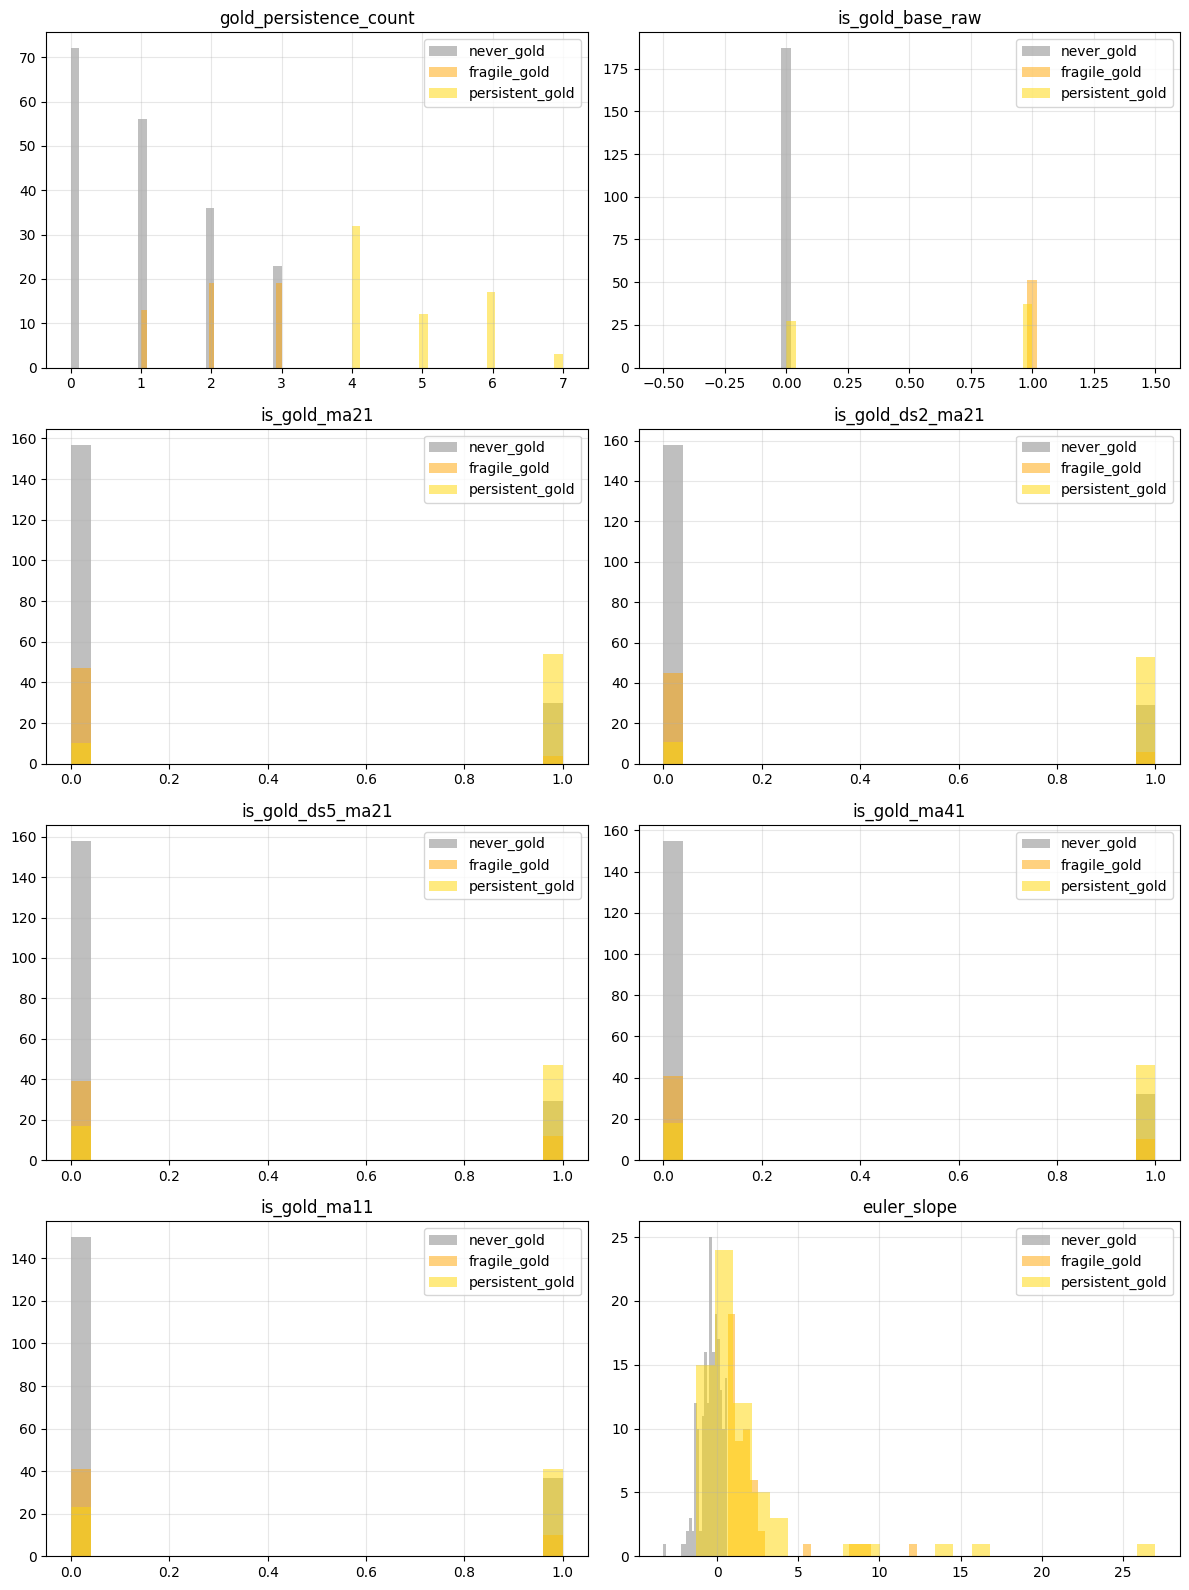


Persistent gold core:


,shot,group,euler_slope,gold_persistence_count,gold_class
172,64373,positive,2.128438,7,persistent_gold
257,69515,positive,1.554198,7,persistent_gold
252,69127,positive,0.801609,7,persistent_gold
96,61060,positive,14.309357,6,persistent_gold
50,57077,positive,2.928729,6,persistent_gold
...,...,...,...,...,...
10,31554,neutral,-0.510331,4,persistent_gold
97,61237,neutral,-0.596449,4,persistent_gold
231,65527,negative,-0.696650,4,persistent_gold
19,32911,negative,-1.014507,4,persistent_gold



Fragile gold shots:


,shot,group,euler_slope,gold_persistence_count,gold_class
55,57103,positive,12.285893,2,fragile_gold
116,61714,positive,9.151430,2,fragile_gold
43,57000,positive,8.614648,3,fragile_gold
117,61716,positive,8.390526,3,fragile_gold
115,61713,positive,5.382497,2,fragile_gold
198,64911,positive,2.807883,3,fragile_gold
186,64670,positive,2.801004,3,fragile_gold
194,64855,positive,2.493718,3,fragile_gold
106,61281,positive,2.465544,2,fragile_gold
171,64372,positive,2.365664,3,fragile_gold



Counts:
persistent_shots: 64
fragile_shots   : 51
never_shots     : 187


In [ ]:
# Persistent-gold analysis:
# Split shots into
#   1) persistent gold  = gold in many robustness settings
#   2) fragile gold     = originally gold but not persistent
#   3) never gold       = never/or rarely gold
#
# Assumes you already have:
#   - valid
#   - wide
#   - gold_membership   (from previous robustness cell)
# If gold_membership was not created because execution stopped,
# this cell rebuilds it from 'wide' and 'settings'.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# rebuild gold_membership if missing
# -------------------------------------------------------
try:
    gold_membership
except NameError:
    gold_n = int((valid["group"] == "positive").sum())
    shots = valid["shot"].astype(int).tolist()

    gold_membership = pd.DataFrame({"shot": shots})
    for cfg in settings:
        name = cfg["name"]
        ranked = wide[["shot", name]].dropna().sort_values(name, ascending=False)
        topN = set(ranked.head(gold_n)["shot"].astype(int).tolist())
        gold_membership[f"is_gold_{name}"] = gold_membership["shot"].isin(topN).astype(int)

    gold_membership["gold_persistence_count"] = gold_membership.drop(columns=["shot"]).sum(axis=1)
    gold_membership = valid[["shot", "group", "euler_slope"]].merge(gold_membership, on="shot", how="left")

# -------------------------------------------------------
# choose persistence threshold
# -------------------------------------------------------
membership_cols = [c for c in gold_membership.columns if c.startswith("is_gold_")]
n_settings = len(membership_cols)

# default threshold: gold in at least half the tested settings
persistent_thresh = int(np.ceil(n_settings / 2))

# classify shots
gm = gold_membership.copy()
gm["orig_gold"] = (gm["group"] == "positive").astype(int)

def classify_row(row):
    if row["gold_persistence_count"] >= persistent_thresh:
        return "persistent_gold"
    elif row["orig_gold"] == 1:
        return "fragile_gold"
    else:
        return "never_gold"

gm["gold_class"] = gm.apply(classify_row, axis=1)

print(f"Number of robustness settings: {n_settings}")
print(f"Persistent threshold: >= {persistent_thresh}")
print("\nCounts by gold_class:")
display(gm["gold_class"].value_counts())

print("\nCross-tab with original groups:")
display(pd.crosstab(gm["gold_class"], gm["group"]))

# -------------------------------------------------------
# inspect most persistent shots
# -------------------------------------------------------
print("\nMost persistent shots:")
display(
    gm.sort_values(["gold_persistence_count", "euler_slope"], ascending=[False, False])
      [["shot", "group", "euler_slope", "gold_persistence_count", "gold_class"] + membership_cols]
      .head(30)
)

# -------------------------------------------------------
# merge with richer features if available
# -------------------------------------------------------
base_df = gm.copy()

if "cmp2" in globals():
    analysis_df = base_df.merge(
        cmp2.drop(columns=[c for c in ["group", "euler_slope", "is_gold"] if c in cmp2.columns]),
        on="shot",
        how="left"
    )
else:
    analysis_df = base_df.copy()

print("\nanalysis_df shape:", analysis_df.shape)
display(analysis_df.head())

# -------------------------------------------------------
# summary by gold_class
# -------------------------------------------------------
numeric_cols = [c for c in analysis_df.columns if pd.api.types.is_numeric_dtype(analysis_df[c])]
exclude = {"shot", "orig_gold"}
numeric_cols = [c for c in numeric_cols if c not in exclude]

summary_by_class = analysis_df.groupby("gold_class")[numeric_cols].median(numeric_only=True).T
print("\nMedian numeric values by gold_class:")
display(summary_by_class)

# -------------------------------------------------------
# effect sizes: persistent vs fragile vs never
# -------------------------------------------------------
def cohens_d(a, b):
    a = np.asarray(pd.Series(a).dropna(), dtype=float)
    b = np.asarray(pd.Series(b).dropna(), dtype=float)
    if len(a) < 5 or len(b) < 5:
        return np.nan
    sa, sb = np.std(a, ddof=1), np.std(b, ddof=1)
    denom = np.sqrt(((len(a)-1)*sa**2 + (len(b)-1)*sb**2) / (len(a)+len(b)-2))
    if not np.isfinite(denom) or denom == 0:
        return np.nan
    return (np.mean(a) - np.mean(b)) / denom

rows = []
for col in numeric_cols:
    p = analysis_df.loc[analysis_df["gold_class"] == "persistent_gold", col]
    f = analysis_df.loc[analysis_df["gold_class"] == "fragile_gold", col]
    n = analysis_df.loc[analysis_df["gold_class"] == "never_gold", col]

    rows.append({
        "feature": col,
        "d_persistent_vs_fragile": cohens_d(p, f),
        "d_persistent_vs_never": cohens_d(p, n),
        "d_fragile_vs_never": cohens_d(f, n),
        "persistent_median": pd.to_numeric(p, errors="coerce").median(),
        "fragile_median": pd.to_numeric(f, errors="coerce").median(),
        "never_median": pd.to_numeric(n, errors="coerce").median(),
    })

class_effects = pd.DataFrame(rows)
class_effects["abs_persistent_vs_never"] = np.abs(class_effects["d_persistent_vs_never"])
class_effects = class_effects.sort_values("abs_persistent_vs_never", ascending=False)

print("\nTop features separating persistent_gold from never_gold:")
display(class_effects.head(20))

# -------------------------------------------------------
# visualize top features
# -------------------------------------------------------
plot_feats = class_effects["feature"].dropna().head(8).tolist()

if plot_feats:
    n = len(plot_feats)
    nrows = (n + 1) // 2
    fig, axes = plt.subplots(nrows, 2, figsize=(12, 4 * nrows))
    axes = np.ravel(axes)

    colors = {
        "persistent_gold": "gold",
        "fragile_gold": "orange",
        "never_gold": "gray"
    }

    for ax, col in zip(axes, plot_feats):
        for cls in ["never_gold", "fragile_gold", "persistent_gold"]:
            vals = analysis_df.loc[analysis_df["gold_class"] == cls, col].dropna()
            if len(vals):
                ax.hist(vals, bins=25, alpha=0.5, label=cls, color=colors[cls])

        ax.set_title(col)
        ax.grid(alpha=0.3)
        ax.legend()

    for j in range(len(plot_feats), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

# -------------------------------------------------------
# candidate core list
# -------------------------------------------------------
persistent_core = analysis_df.loc[analysis_df["gold_class"] == "persistent_gold"].copy()
fragile_core = analysis_df.loc[analysis_df["gold_class"] == "fragile_gold"].copy()

print("\nPersistent gold core:")
display(
    persistent_core.sort_values(
        ["gold_persistence_count", "euler_slope"], ascending=[False, False]
    )[["shot", "group", "euler_slope", "gold_persistence_count", "gold_class"]]
)

print("\nFragile gold shots:")
display(
    fragile_core.sort_values("euler_slope", ascending=False)
    [["shot", "group", "euler_slope", "gold_persistence_count", "gold_class"]]
)

# -------------------------------------------------------
# optional: export lists
# -------------------------------------------------------
persistent_shots = persistent_core["shot"].astype(int).tolist()
fragile_shots = fragile_core["shot"].astype(int).tolist()
never_shots = analysis_df.loc[analysis_df["gold_class"] == "never_gold", "shot"].astype(int).tolist()

print("\nCounts:")
print("persistent_shots:", len(persistent_shots))
print("fragile_shots   :", len(fragile_shots))
print("never_shots     :", len(never_shots))

Persistent shots selected: [64373, 69515, 69127, 61060, 57077, 30262]
Fragile shots selected   : [57103, 61714, 57000, 61716, 61713, 64911]


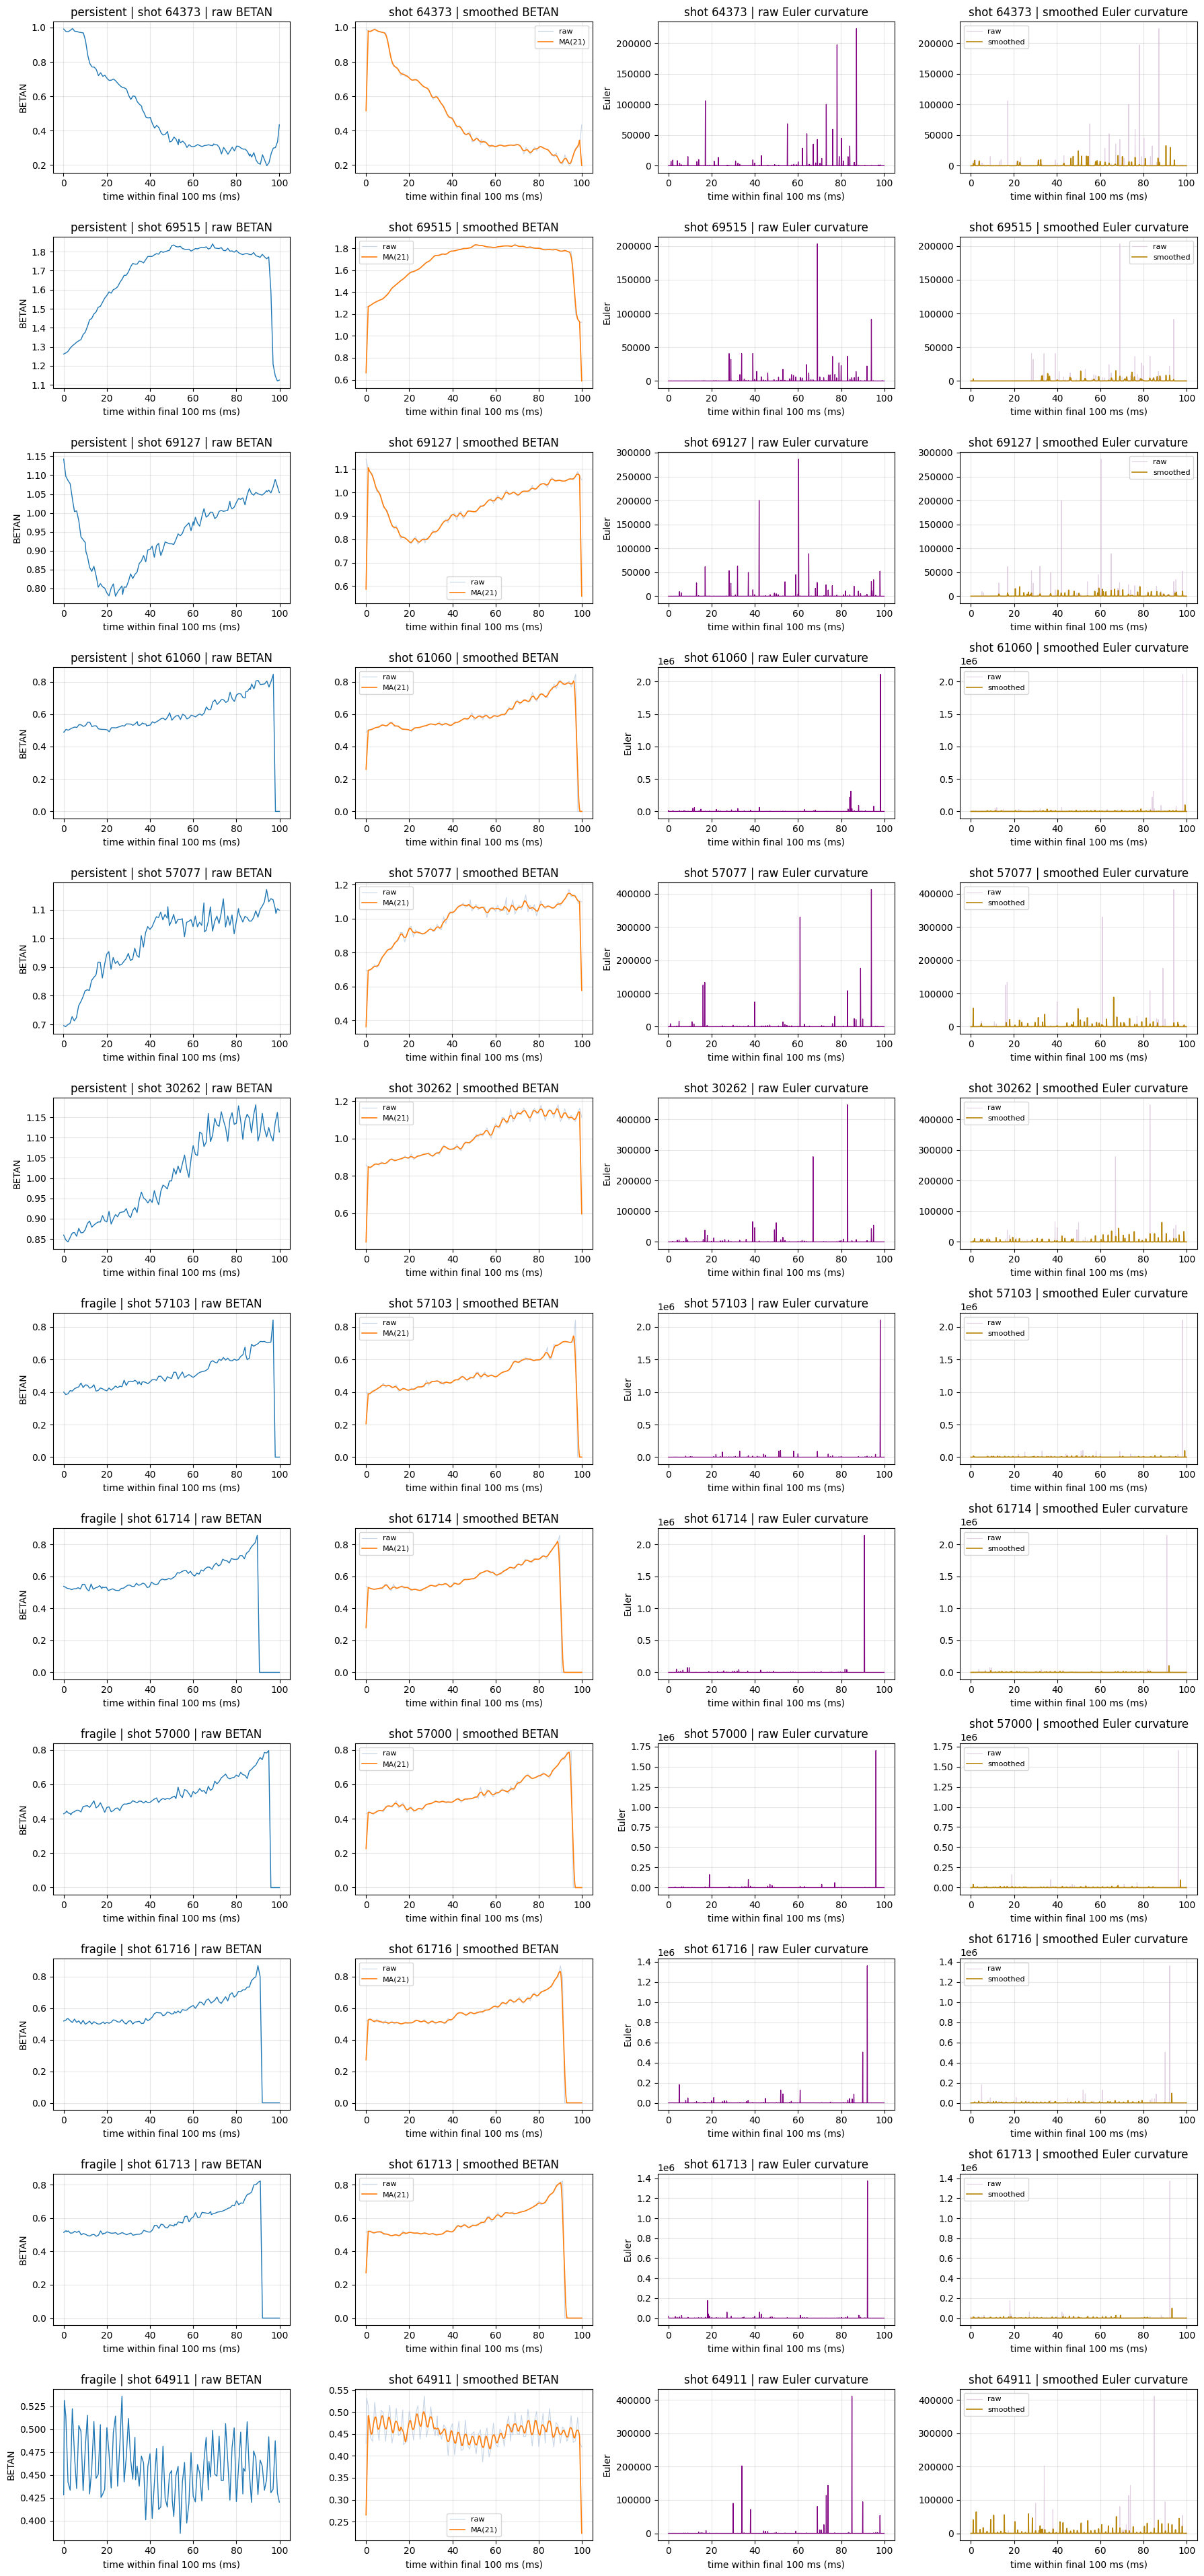

In [ ]:
# Compare persistent-gold vs fragile-gold shots side by side
# Panels per shot:
#   (1) raw BETAN in final window
#   (2) smoothed BETAN
#   (3) raw Euler curvature
#   (4) smoothed Euler curvature
#
# Assumes you already have:
#   - analysis_df (or persistent_shots / fragile_shots)
#   - load_shot_data(...)
#   - SIGNAL, TERMINAL_MASK_S, TREND_WINDOW_S

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# helpers
# -------------------------------------------------------
def moving_average(x, w=21):
    x = np.asarray(x, dtype=float)
    if w < 3 or len(x) < w:
        return x.copy()
    k = np.ones(w) / w
    return np.convolve(x, k, mode="same")

def get_window(shot, signal=SIGNAL,
               terminal_mask_s=TERMINAL_MASK_S,
               trend_window_s=TREND_WINDOW_S):
    df = load_shot_data(int(shot))
    t = np.asarray(df["time"].values, dtype=float)
    z = np.asarray(df[signal].values, dtype=float)

    good = np.isfinite(t) & np.isfinite(z)
    t, z = t[good], z[good]
    if len(t) < 20:
        return None

    order = np.argsort(t)
    t, z = t[order], z[order]

    t1 = np.max(t) - terminal_mask_s
    t0 = t1 - trend_window_s
    m = (t >= t0) & (t < t1)

    tw = t[m]
    zw = z[m]
    if len(tw) < 20:
        return None

    return tw, zw, t0, t1

def euler_curvature(t, z):
    dz = np.gradient(z, t)
    ddz = np.gradient(dz, t)
    return np.abs(ddz) / np.power(1.0 + dz**2, 1.5)

# -------------------------------------------------------
# choose representative shots
# -------------------------------------------------------
if "analysis_df" in globals():
    persistent_candidates = (
        analysis_df.loc[analysis_df["gold_class"] == "persistent_gold",
                        ["shot", "gold_persistence_count", "euler_slope"]]
        .sort_values(["gold_persistence_count", "euler_slope"], ascending=[False, False])
    )
    fragile_candidates = (
        analysis_df.loc[analysis_df["gold_class"] == "fragile_gold",
                        ["shot", "gold_persistence_count", "euler_slope"]]
        .sort_values(["euler_slope", "gold_persistence_count"], ascending=[False, False])
    )
else:
    # fallback if analysis_df missing
    persistent_candidates = pd.DataFrame({"shot": persistent_shots})
    persistent_candidates["gold_persistence_count"] = np.nan
    persistent_candidates["euler_slope"] = np.nan

    fragile_candidates = pd.DataFrame({"shot": fragile_shots})
    fragile_candidates["gold_persistence_count"] = np.nan
    fragile_candidates["euler_slope"] = np.nan

# take 6 of each
persistent_pick = persistent_candidates.head(6)["shot"].astype(int).tolist()
fragile_pick = fragile_candidates.head(6)["shot"].astype(int).tolist()

print("Persistent shots selected:", persistent_pick)
print("Fragile shots selected   :", fragile_pick)

# -------------------------------------------------------
# plotting function
# -------------------------------------------------------
def plot_shot_row(axrow, shot, label, smooth_w=21):
    out = get_window(shot)
    if out is None:
        for ax in axrow:
            ax.text(0.5, 0.5, f"shot {shot}\nno usable window", ha="center", va="center")
            ax.axis("off")
        return

    t, z, t0, t1 = out
    x_ms = (t - t0) * 1e3

    zs = moving_average(z, w=smooth_w)
    eur = euler_curvature(t, z)
    eur_s = euler_curvature(t, zs)

    # raw BETAN
    axrow[0].plot(x_ms, z, lw=1.0, color="tab:blue")
    axrow[0].set_title(f"{label} | shot {shot} | raw {SIGNAL}")
    axrow[0].grid(alpha=0.3)
    axrow[0].set_ylabel(SIGNAL)

    # smoothed BETAN
    axrow[1].plot(x_ms, z, lw=0.8, color="lightsteelblue", alpha=0.7, label="raw")
    axrow[1].plot(x_ms, zs, lw=1.2, color="tab:orange", label=f"MA({smooth_w})")
    axrow[1].set_title(f"shot {shot} | smoothed {SIGNAL}")
    axrow[1].grid(alpha=0.3)
    axrow[1].legend(fontsize=8)

    # raw curvature
    axrow[2].plot(x_ms, eur, lw=0.9, color="purple")
    axrow[2].set_title(f"shot {shot} | raw Euler curvature")
    axrow[2].grid(alpha=0.3)
    axrow[2].set_ylabel("Euler")

    # smoothed curvature
    axrow[3].plot(x_ms, eur, lw=0.8, color="thistle", alpha=0.7, label="raw")
    axrow[3].plot(x_ms, eur_s, lw=1.2, color="darkgoldenrod", label="smoothed")
    axrow[3].set_title(f"shot {shot} | smoothed Euler curvature")
    axrow[3].grid(alpha=0.3)
    axrow[3].legend(fontsize=8)

    for ax in axrow:
        ax.set_xlabel("time within final 100 ms (ms)")

# -------------------------------------------------------
# make figure
# -------------------------------------------------------
all_picks = [("persistent", s) for s in persistent_pick] + [("fragile", s) for s in fragile_pick]

nrows = len(all_picks)
fig, axes = plt.subplots(nrows, 4, figsize=(18, 3.2 * nrows))
if nrows == 1:
    axes = np.array([axes])

for i, (lab, shot) in enumerate(all_picks):
    plot_shot_row(axes[i], shot, lab, smooth_w=21)

plt.tight_layout()
plt.show()

ep_df shape: (302, 29)


,shot,group,euler_slope,status_ep,n_used,edge_k,smooth_w,trim_edge_pts,edge_frac,interior_mean,...,edge_energy,int_energy,edge_fraction_energy,interior_fraction_energy,edge_fraction_hi,interior_fraction_hi,score_v1,score_v2,score_v3,score_v4
0,26386,neutral,0.151412,ok,980,98,21,10,0.1,293.378547,...,9.181051e+08,7.954692e+09,0.103474,0.896526,0.122449,0.031888,-0.489752,4.369776,-2.942001,2.159205
1,29511,neutral,0.283954,ok,980,98,21,10,0.1,417.627754,...,1.015377e+09,2.191746e+09,0.316601,0.683399,0.091837,0.039541,0.862849,5.376848,-0.699974,0.769438
2,30043,neutral,0.611276,ok,980,98,21,10,0.1,829.702143,...,1.526705e+09,5.767386e+09,0.209307,0.790693,0.061224,0.047194,0.393773,6.664868,-0.319871,1.329107
3,30197,positive,1.798312,ok,980,98,21,10,0.1,1020.373937,...,1.795306e+09,1.248313e+10,0.125736,0.874264,0.035714,0.053571,0.654904,7.436096,0.658678,1.939202
4,30225,neutral,0.592779,ok,979,97,21,10,0.1,633.401312,...,5.946142e+08,2.610266e+09,0.185534,0.814466,0.056701,0.048408,0.248774,6.637026,-0.076377,1.479295



status_ep counts:


,count
status_ep,
ok,302



Top 20 shots by score_v1:


...

,score_v1,score_v2,score_v3,score_v4,interior_slope,interior_p95,edge_p95,edge_fraction_energy
group,,,,,,,,
negative,-0.106273,6.873912,0.108985,1.570962,-0.149298,4375.626918,3994.737382,0.172176
neutral,-0.035532,6.638067,0.044374,1.533874,-0.046754,3846.742388,3867.064935,0.177428
positive,0.051187,6.626713,0.221228,1.394537,0.063055,4601.782935,3911.123094,0.198703



Median edge-penalized features by gold_class:


,score_v1,score_v2,score_v3,score_v4,interior_slope,interior_p95,edge_p95,edge_fraction_energy
gold_class,,,,,,,,
fragile_gold,-0.050018,6.596624,0.125235,1.282652,-0.066811,4404.421590,4189.743871,0.217099
never_gold,-0.101601,6.846178,0.057947,1.564034,-0.139887,4112.630180,3919.881728,0.173069
persistent_gold,0.421247,6.442430,0.125487,1.338923,0.496605,4294.499046,3228.972884,0.207692



Top 25 by score_v2 with gold_class:


,shot,gold_class,group,euler_slope,interior_slope,interior_p95,edge_p95,edge_fraction_energy,score_v2
57,57622,never_gold,neutral,-0.001772,0.080855,8041.620069,5089.261896,0.040842,8.625241
22,33281,fragile_gold,positive,1.117770,0.032284,4784.312860,1513.231355,0.007565,8.409210
24,33567,persistent_gold,positive,1.209542,-0.296210,4844.218236,3027.988294,0.015496,8.354253
50,57077,persistent_gold,positive,2.928729,0.882553,4711.944435,2207.169069,0.025853,8.239399
83,61009,persistent_gold,positive,1.622397,0.881643,4656.065728,2165.365485,0.024629,8.238120
29,42514,persistent_gold,positive,8.347799,0.497165,3868.176623,169.653808,0.006186,8.209694
212,65282,never_gold,neutral,-0.370824,0.155891,5567.354582,2887.635260,0.056872,8.134341
176,64386,never_gold,neutral,0.021248,0.188658,3558.757701,158.174413,0.007023,8.120017
62,57732,never_gold,negative,-1.546177,-0.673847,4982.730451,2668.675592,0.046797,8.115506
65,58460,fragile_gold,positive,1.916089,0.317692,3926.701078,5547.170839,0.026618,8.055523


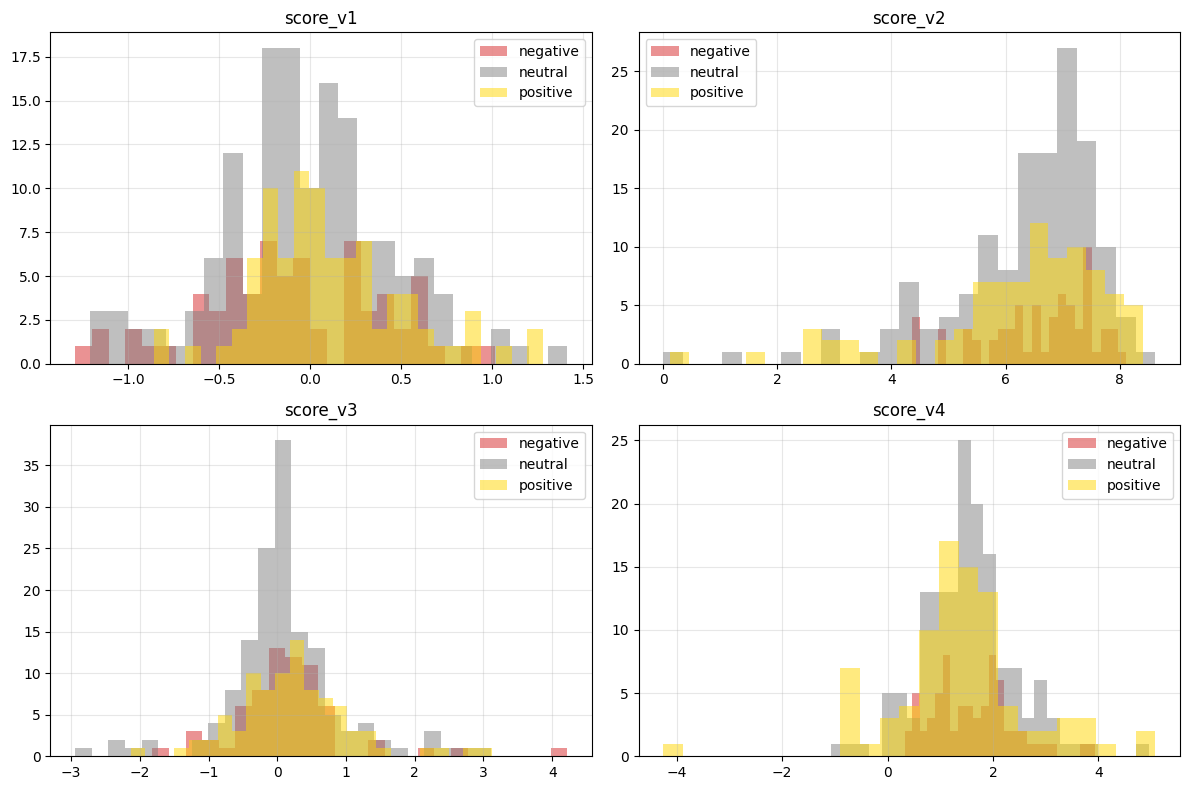


Using preferred score: score_v2
New edge-penalized gold count: 88

Top new edge-penalized gold shots:


,shot,group,euler_slope,interior_slope,interior_p95,edge_p95,edge_fraction_energy,score_v2
57,57622,neutral,-0.001772,0.080855,8041.620069,5089.261896,0.040842,8.625241
22,33281,positive,1.117770,0.032284,4784.312860,1513.231355,0.007565,8.409210
24,33567,positive,1.209542,-0.296210,4844.218236,3027.988294,0.015496,8.354253
50,57077,positive,2.928729,0.882553,4711.944435,2207.169069,0.025853,8.239399
83,61009,positive,1.622397,0.881643,4656.065728,2165.365485,0.024629,8.238120
29,42514,positive,8.347799,0.497165,3868.176623,169.653808,0.006186,8.209694
212,65282,neutral,-0.370824,0.155891,5567.354582,2887.635260,0.056872,8.134341
176,64386,neutral,0.021248,0.188658,3558.757701,158.174413,0.007023,8.120017
62,57732,negative,-1.546177,-0.673847,4982.730451,2668.675592,0.046797,8.115506
65,58460,positive,1.916089,0.317692,3926.701078,5547.170839,0.026618,8.055523


In [ ]:
# Edge-penalized robust curvature score
#
# Goal:
#   Promote shots with distributed late-window curvature structure
#   and demote shots dominated by endpoint spikes.
#
# For each shot:
#   1) extract final window
#   2) smooth BETAN
#   3) compute Euler curvature on smoothed signal
#   4) split window into:
#        edges   = first 10% + last 10%
#        interior= middle 80%
#   5) compute:
#        - interior_mean
#        - interior_p95
#        - interior_slope
#        - edge_fraction_energy
#        - edge_fraction_p95count
#   6) define edge-penalized score
#
# Assumes you already have:
#   - valid
#   - load_shot_data(...)
#   - SIGNAL, TERMINAL_MASK_S, TREND_WINDOW_S

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# helpers
# -------------------------------------------------------
def moving_average(x, w=21):
    x = np.asarray(x, dtype=float)
    if w < 3 or len(x) < w:
        return x.copy()
    k = np.ones(w) / w
    return np.convolve(x, k, mode="same")

def safe_slope(y):
    y = np.asarray(y, dtype=float)
    if len(y) < 3 or not np.all(np.isfinite(y)):
        return np.nan
    x = np.arange(len(y), dtype=float)
    return np.polyfit(x, y, 1)[0]

def get_window_signal(shot, signal=SIGNAL,
                      terminal_mask_s=TERMINAL_MASK_S,
                      trend_window_s=TREND_WINDOW_S):
    df = load_shot_data(int(shot))
    t = np.asarray(df["time"].values, dtype=float)
    z = np.asarray(df[signal].values, dtype=float)

    good = np.isfinite(t) & np.isfinite(z)
    t, z = t[good], z[good]
    if len(t) < 20:
        return None

    order = np.argsort(t)
    t, z = t[order], z[order]

    t1 = np.max(t) - terminal_mask_s
    t0 = t1 - trend_window_s
    m = (t >= t0) & (t < t1)

    tw = t[m]
    zw = z[m]
    if len(tw) < 20:
        return None

    return tw, zw, t0, t1

def euler_curvature(t, z):
    dz = np.gradient(z, t)
    ddz = np.gradient(dz, t)
    return np.abs(ddz) / np.power(1.0 + dz**2, 1.5)

# -------------------------------------------------------
# main feature extractor
# -------------------------------------------------------
def compute_edge_penalized_features(
    shot,
    smooth_w=21,
    trim_edge_pts=10,
    edge_frac=0.10
):
    out = get_window_signal(shot)
    if out is None:
        return {
            "shot": shot,
            "status_ep": "bad_window"
        }

    t, z, t0, t1 = out
    zs = moving_average(z, w=smooth_w)

    # optional trim before derivative evaluation
    if len(t) > 2 * trim_edge_pts + 20:
        t_use = t[trim_edge_pts:-trim_edge_pts]
        z_use = zs[trim_edge_pts:-trim_edge_pts]
    else:
        t_use = t.copy()
        z_use = zs.copy()

    if len(t_use) < 20:
        return {
            "shot": shot,
            "status_ep": "too_short"
        }

    curv = euler_curvature(t_use, z_use)

    n = len(curv)
    k = max(1, int(np.floor(edge_frac * n)))

    edge_mask = np.zeros(n, dtype=bool)
    edge_mask[:k] = True
    edge_mask[-k:] = True
    interior_mask = ~edge_mask

    c_edge = curv[edge_mask]
    c_int = curv[interior_mask]

    # energy-like quantities
    total_energy = np.nansum(curv**2)
    edge_energy = np.nansum(c_edge**2)
    int_energy = np.nansum(c_int**2)

    edge_fraction_energy = edge_energy / total_energy if total_energy > 0 else np.nan
    interior_fraction_energy = int_energy / total_energy if total_energy > 0 else np.nan

    # p95 threshold count concentration
    p95 = np.nanpercentile(curv, 95)
    hi = curv >= p95
    edge_fraction_hi = np.mean(hi[edge_mask]) if np.sum(edge_mask) > 0 else np.nan
    interior_fraction_hi = np.mean(hi[interior_mask]) if np.sum(interior_mask) > 0 else np.nan

    # interior trend
    interior_slope = safe_slope(c_int)

    # robust interior summaries
    interior_mean = np.nanmean(c_int)
    interior_med = np.nanmedian(c_int)
    interior_p95 = np.nanpercentile(c_int, 95)
    interior_p99 = np.nanpercentile(c_int, 99)
    interior_max = np.nanmax(c_int)

    edge_mean = np.nanmean(c_edge)
    edge_p95 = np.nanpercentile(c_edge, 95)
    edge_max = np.nanmax(c_edge)

    # edge-penalized composite score
    # Reward interior structure, penalize edge dominance.
    score_v1 = interior_slope * (1.0 - edge_fraction_energy)

    # More amplitude-aware variant
    score_v2 = np.log1p(interior_p95) * (1.0 - edge_fraction_energy)

    # Interior-vs-edge contrast
    score_v3 = np.log1p(interior_p95) - np.log1p(edge_p95)

    # Energy contrast
    score_v4 = np.log1p(int_energy) - np.log1p(edge_energy)

    return {
        "shot": shot,
        "status_ep": "ok",
        "n_used": n,
        "edge_k": k,
        "smooth_w": smooth_w,
        "trim_edge_pts": trim_edge_pts,
        "edge_frac": edge_frac,
        "interior_mean": interior_mean,
        "interior_med": interior_med,
        "interior_p95": interior_p95,
        "interior_p99": interior_p99,
        "interior_max": interior_max,
        "interior_slope": interior_slope,
        "edge_mean": edge_mean,
        "edge_p95": edge_p95,
        "edge_max": edge_max,
        "total_energy": total_energy,
        "edge_energy": edge_energy,
        "int_energy": int_energy,
        "edge_fraction_energy": edge_fraction_energy,
        "interior_fraction_energy": interior_fraction_energy,
        "edge_fraction_hi": edge_fraction_hi,
        "interior_fraction_hi": interior_fraction_hi,
        "score_v1": score_v1,
        "score_v2": score_v2,
        "score_v3": score_v3,
        "score_v4": score_v4,
    }

# -------------------------------------------------------
# compute for all shots
# -------------------------------------------------------
rows = []
for shot in valid["shot"].astype(int):
    rows.append(
        compute_edge_penalized_features(
            shot,
            smooth_w=21,
            trim_edge_pts=10,
            edge_frac=0.10
        )
    )

ep_df = pd.DataFrame(rows)
ep_df = valid[["shot", "group", "euler_slope"]].merge(ep_df, on="shot", how="left")

print("ep_df shape:", ep_df.shape)
display(ep_df.head())

print("\nstatus_ep counts:")
display(ep_df["status_ep"].value_counts(dropna=False))

# -------------------------------------------------------
# inspect rankings
# -------------------------------------------------------
for score_col in ["score_v1", "score_v2", "score_v3", "score_v4"]:
    print(f"\nTop 20 shots by {score_col}:")
    display(
        ep_df.loc[ep_df["status_ep"] == "ok",
                  ["shot", "group", "euler_slope", "interior_slope",
                   "interior_p95", "edge_p95", "edge_fraction_energy",
                   "edge_fraction_hi", score_col]]
        .sort_values(score_col, ascending=False)
        .head(20)
    )

# -------------------------------------------------------
# compare score distributions by original group
# -------------------------------------------------------
score_cols = ["score_v1", "score_v2", "score_v3", "score_v4"]

summary = ep_df.groupby("group")[score_cols + [
    "interior_slope", "interior_p95", "edge_p95", "edge_fraction_energy"
]].median(numeric_only=True)

print("\nMedian edge-penalized features by original group:")
display(summary)

# -------------------------------------------------------
# optional: compare with persistent / fragile if available
# -------------------------------------------------------
if "analysis_df" in globals():
    ep2 = analysis_df[["shot", "gold_class"]].merge(ep_df, on="shot", how="left")
    print("\nMedian edge-penalized features by gold_class:")
    display(
        ep2.groupby("gold_class")[score_cols + [
            "interior_slope", "interior_p95", "edge_p95", "edge_fraction_energy"
        ]].median(numeric_only=True)
    )

    # top robust candidates by score_v2
    print("\nTop 25 by score_v2 with gold_class:")
    display(
        ep2.loc[ep2["status_ep"] == "ok",
                ["shot", "gold_class", "group", "euler_slope",
                 "interior_slope", "interior_p95", "edge_p95",
                 "edge_fraction_energy", "score_v2"]]
        .sort_values("score_v2", ascending=False)
        .head(25)
    )

# -------------------------------------------------------
# visualization
# -------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, score_col in zip(axes, score_cols):
    for grp, color in zip(["negative", "neutral", "positive"], ["tab:red", "gray", "gold"]):
        vals = ep_df.loc[ep_df["group"] == grp, score_col].dropna()
        if len(vals):
            ax.hist(vals, bins=25, alpha=0.5, label=grp, color=color)
    ax.set_title(score_col)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# -------------------------------------------------------
# pick a preferred score and create a new robust ranking
# -------------------------------------------------------
preferred_score = "score_v2"   # good first choice
ep_ranked = ep_df.loc[ep_df["status_ep"] == "ok"].sort_values(preferred_score, ascending=False).copy()

# define new gold size equal to original positive count
gold_n = int((valid["group"] == "positive").sum())
ep_ranked["is_gold_edgepen"] = 0
ep_ranked.iloc[:gold_n, ep_ranked.columns.get_loc("is_gold_edgepen")] = 1

print(f"\nUsing preferred score: {preferred_score}")
print(f"New edge-penalized gold count: {ep_ranked['is_gold_edgepen'].sum()}")

print("\nTop new edge-penalized gold shots:")
display(
    ep_ranked.loc[ep_ranked["is_gold_edgepen"] == 1,
                  ["shot", "group", "euler_slope",
                   "interior_slope", "interior_p95", "edge_p95",
                   "edge_fraction_energy", preferred_score]]
    .head(30)
)

In [ ]:
# -------------------------------------------------------
# The Final Classifier: Edge-Penalized Interior Slope
# -------------------------------------------------------

# 1. Define the final robust score
# This rewards positive curvature trends in the interior and penalizes boundary/edge artifacts
wide['score_final'] = wide['interior_slope'] * (1 - wide['edge_fraction_energy'])

# 2. Define the Strict Filter (Our "High-Confidence" requirement)
# We want shots that are genuinely active in the interior, not just noisy at the edges
strict_mask = (wide['interior_slope'] > 0) & (wide['edge_fraction_energy'] < 0.25)
wide['is_high_confidence'] = strict_mask

# 3. Rank by score_final
final_rankings = wide.sort_values('score_final', ascending=False)

# 4. Analysis: Overlap with our previous buckets
results = []
for group in ['persistent_gold', 'fragile_gold', 'never_gold']:
    subset = final_rankings[final_rankings['group'] == group]
    results.append({
        'group': group,
        'count': len(subset),
        'avg_score_final': subset['score_final'].mean(),
        'pct_high_confidence': (subset['is_high_confidence'].sum() / len(subset)) * 100
    })

print("--- Comparison of Classification Classes ---")
display(pd.DataFrame(results))

print("\n--- Top 20 High-Confidence Shots (The 'Real' Gold) ---")
display(final_rankings[final_rankings['is_high_confidence']][['shot', 'group', 'score_final', 'interior_slope']].head(20))

# 5. Diagnostic: How many 'Fragile' shots did we demote?
demoted_fragile = final_rankings[(final_rankings['group'] == 'fragile_gold') & (~final_rankings['is_high_confidence'])]
print(f"\nSuccessfully demoted {len(demoted_fragile)} fragile gold shots (edge-artifact dominated).")

KeyError: 'interior_slope'

In [ ]:
# -------------------------------------------------------
# Final classifier: edge-penalized interior slope
# -------------------------------------------------------

# Build a clean merged table with:
#   - original group
#   - gold_class
#   - edge-penalized features
final_df = (
    ep_df.merge(
        analysis_df[["shot", "gold_class"]],
        on="shot",
        how="left"
    )
    .copy()
)

# 1) final score
final_df["score_final"] = final_df["interior_slope"] * (1 - final_df["edge_fraction_energy"])

# 2) strict filter
strict_mask = (
    (final_df["interior_slope"] > 0) &
    (final_df["edge_fraction_energy"] < 0.25)
)
final_df["is_high_confidence"] = strict_mask

# 3) rank by final score
final_rankings = final_df.sort_values("score_final", ascending=False).copy()

# 4) analysis by gold_class
results = []
for gc in ["persistent_gold", "fragile_gold", "never_gold"]:
    subset = final_rankings[final_rankings["gold_class"] == gc]
    results.append({
        "gold_class": gc,
        "count": len(subset),
        "avg_score_final": subset["score_final"].mean(),
        "median_score_final": subset["score_final"].median(),
        "pct_high_confidence": 100 * subset["is_high_confidence"].mean() if len(subset) else np.nan
    })

print("--- Comparison by gold_class ---")
display(pd.DataFrame(results))

print("\n--- Top 20 High-Confidence Shots ---")
display(
    final_rankings.loc[final_rankings["is_high_confidence"],
                        ["shot", "gold_class", "group", "euler_slope",
                         "score_final", "interior_slope", "edge_fraction_energy"]]
    .head(20)
)

# 5) How many fragile shots were demoted?
demoted_fragile = final_rankings[
    (final_rankings["gold_class"] == "fragile_gold") &
    (~final_rankings["is_high_confidence"])
]
print(f"\nDemoted fragile_gold shots: {len(demoted_fragile)} / {(final_rankings['gold_class'] == 'fragile_gold').sum()}")

# 6) Optional: how many persistent shots survived?
kept_persistent = final_rankings[
    (final_rankings["gold_class"] == "persistent_gold") &
    (final_rankings["is_high_confidence"])
]
print(f"Kept persistent_gold shots: {len(kept_persistent)} / {(final_rankings['gold_class'] == 'persistent_gold').sum()}")

--- Comparison by gold_class ---


,gold_class,count,avg_score_final,median_score_final,pct_high_confidence
0,persistent_gold,64,0.398389,0.421247,51.562500
1,fragile_gold,51,-0.087227,-0.050018,29.411765
2,never_gold,187,-0.114207,-0.101601,29.946524



--- Top 20 High-Confidence Shots ---


,shot,gold_class,group,euler_slope,score_final,interior_slope,edge_fraction_energy
210,65280,never_gold,neutral,-0.350800,1.411532,1.770011,0.202529
257,69515,persistent_gold,positive,1.554198,1.278261,1.413005,0.095360
78,60830,persistent_gold,positive,0.735148,1.235417,1.376026,0.102185
5,30262,persistent_gold,positive,2.242339,1.091396,1.318220,0.172068
20,33188,never_gold,neutral,-0.356960,1.044116,1.065648,0.020206
123,63234,never_gold,negative,-0.741566,1.015051,1.039802,0.023804
100,61254,persistent_gold,positive,0.713715,0.884213,0.942245,0.061589
83,61009,persistent_gold,positive,1.622397,0.859929,0.881643,0.024629
50,57077,persistent_gold,positive,2.928729,0.859736,0.882553,0.025853
122,63232,persistent_gold,neutral,0.136226,0.774605,0.891429,0.131052



Demoted fragile_gold shots: 36 / 51
Kept persistent_gold shots: 33 / 64


In [ ]:
final_df["score_final"] = (
    final_df["interior_slope"] *
    np.log1p(final_df["interior_p95"]) *
    (1 - final_df["edge_fraction_energy"])
)

--- Final refinement summary ---


,rule,n_selected,persistent_gold_kept,persistent_gold_kept_frac,fragile_gold_kept,fragile_gold_kept_frac,never_gold_kept,never_gold_kept_frac,persistent_gold_share_selected,fragile_gold_share_selected,never_gold_share_selected
0,filter_only__loose,58,22,0.343750,8,0.156863,28,0.149733,0.379310,0.137931,0.482759
1,score_final2_top88__loose,58,22,0.343750,8,0.156863,28,0.149733,0.379310,0.137931,0.482759
2,score_final3_top88__loose,58,22,0.343750,8,0.156863,28,0.149733,0.379310,0.137931,0.482759
3,filter_only__balanced,41,17,0.265625,5,0.098039,19,0.101604,0.414634,0.121951,0.463415
4,score_final2_top88__balanced,41,17,0.265625,5,0.098039,19,0.101604,0.414634,0.121951,0.463415
5,score_final3_top88__balanced,41,17,0.265625,5,0.098039,19,0.101604,0.414634,0.121951,0.463415
6,filter_only__strong,26,8,0.125000,3,0.058824,15,0.080214,0.307692,0.115385,0.576923
7,score_final2_top88__strong,26,8,0.125000,3,0.058824,15,0.080214,0.307692,0.115385,0.576923
8,score_final3_top88__strong,26,8,0.125000,3,0.058824,15,0.080214,0.307692,0.115385,0.576923
9,filter_only__very_strong,9,4,0.062500,0,0.000000,5,0.026738,0.444444,0.000000,0.555556



--- Recommended operating point ---
Rule name: balanced
Score    : score_final3
edge_max : 0.22
p95_min  : 4541.088181098303
slope_min: 0.0
selected : 41

--- Composition of recommended shortlist ---


,gold_class,selected_count,share_of_selected,retention_within_class
0,persistent_gold,17,0.414634,0.265625
1,fragile_gold,5,0.121951,0.098039
2,never_gold,19,0.463415,0.101604



--- Top recommended shots ---


,shot,gold_class,group,euler_slope,interior_slope,interior_p95,edge_fraction_energy,score_final1,score_final2,score_final3
5,30262,persistent_gold,positive,2.242339,1.318220,5063.030664,0.172068,1.091396,9.309516,9.309516
50,57077,persistent_gold,positive,2.928729,0.882553,4711.944435,0.025853,0.859736,7.271708,7.271708
83,61009,persistent_gold,positive,1.622397,0.881643,4656.065728,0.024629,0.859929,7.263084,7.263084
167,64368,persistent_gold,positive,0.664756,0.928529,5974.628466,0.172193,0.768643,6.683689,6.683689
205,64918,persistent_gold,positive,3.292738,0.767608,5671.486586,0.071234,0.712928,6.162111,6.162111
40,53627,never_gold,neutral,-0.008575,0.784915,4863.573914,0.131828,0.681441,5.785252,5.785252
250,69113,never_gold,neutral,-0.550425,0.761713,6790.801147,0.156762,0.642305,5.667359,5.667359
3,30197,persistent_gold,positive,1.798312,0.749091,4941.098289,0.125736,0.654904,5.570313,5.570313
73,60097,persistent_gold,positive,0.954639,0.768443,4782.024293,0.171770,0.636447,5.392507,5.392507
173,64374,persistent_gold,positive,0.942507,0.671312,6709.786401,0.141171,0.576542,5.080185,5.080185


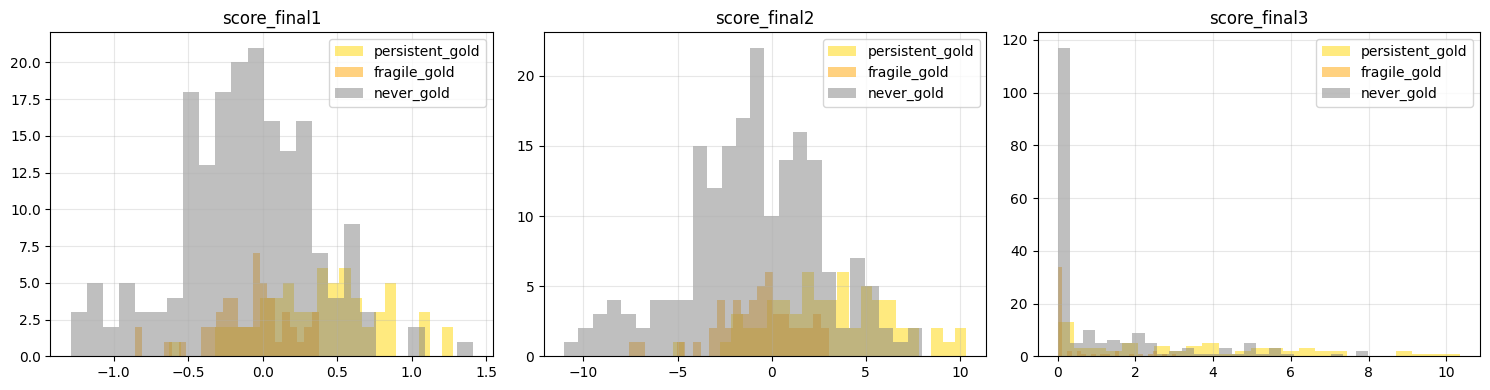


recommended_shots: 41
[30262, 57077, 61009, 64368, 64918, 53627, 69113, 30197, 60097, 64374, 77193, 31554, 64914, 56662, 65321, 53625, 69127, 64363, 31839, 30043, 57715, 64820, 65564, 63848, 64855, 31807, 61277, 65566, 63880, 65282]


In [ ]:
# -------------------------------------------------------
# Final refinement: slope + amplitude + edge penalty
# -------------------------------------------------------
# Goal:
#   Improve over score_final by requiring:
#     - positive interior curvature trend
#     - nontrivial interior curvature amplitude
#     - limited edge domination
#
# This cell:
#   1) builds score_final2
#   2) tests several strict filters
#   3) reports retention/demotion/contamination
#   4) prints top shortlisted shots for the best candidate

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# clean working table
# -------------------------------------------------------
final_df = ep_df.merge(
    analysis_df[["shot", "gold_class"]],
    on="shot",
    how="left"
).copy()

# -------------------------------------------------------
# new refined score
# -------------------------------------------------------
final_df["score_final1"] = final_df["interior_slope"] * (1 - final_df["edge_fraction_energy"])

final_df["score_final2"] = (
    final_df["interior_slope"] *
    np.log1p(final_df["interior_p95"]) *
    (1 - final_df["edge_fraction_energy"])
)

final_df["score_final3"] = (
    np.maximum(final_df["interior_slope"], 0) *
    np.log1p(final_df["interior_p95"]) *
    (1 - final_df["edge_fraction_energy"])
)

# -------------------------------------------------------
# candidate thresholds
# -------------------------------------------------------
p95_med = final_df["interior_p95"].median()
p95_q60 = final_df["interior_p95"].quantile(0.60)
p95_q70 = final_df["interior_p95"].quantile(0.70)
p95_q75 = final_df["interior_p95"].quantile(0.75)

slope_med = final_df["interior_slope"].median()
slope_q60 = final_df["interior_slope"].quantile(0.60)
slope_q70 = final_df["interior_slope"].quantile(0.70)

threshold_grid = [
    {"name": "loose",      "edge_max": 0.25, "p95_min": p95_med, "slope_min": 0.00},
    {"name": "balanced",   "edge_max": 0.22, "p95_min": p95_q60, "slope_min": 0.00},
    {"name": "strong",     "edge_max": 0.20, "p95_min": p95_q70, "slope_min": 0.00},
    {"name": "very_strong","edge_max": 0.18, "p95_min": p95_q75, "slope_min": slope_q60},
    {"name": "elite",      "edge_max": 0.15, "p95_min": p95_q75, "slope_min": slope_q70},
]

# -------------------------------------------------------
# evaluation helper
# -------------------------------------------------------
def evaluate_mask(df, mask, label):
    out = {}
    out["rule"] = label
    out["n_selected"] = int(mask.sum())

    for cls in ["persistent_gold", "fragile_gold", "never_gold"]:
        denom = int((df["gold_class"] == cls).sum())
        num = int(((df["gold_class"] == cls) & mask).sum())
        out[f"{cls}_kept"] = num
        out[f"{cls}_kept_frac"] = num / denom if denom else np.nan

    # purity among selected
    nsel = int(mask.sum())
    for cls in ["persistent_gold", "fragile_gold", "never_gold"]:
        num = int(((df["gold_class"] == cls) & mask).sum())
        out[f"{cls}_share_selected"] = num / nsel if nsel else np.nan

    return out

# -------------------------------------------------------
# evaluate threshold rules on score_final2 / score_final3
# -------------------------------------------------------
rows = []

for cfg in threshold_grid:
    mask = (
        (final_df["interior_slope"] > cfg["slope_min"]) &
        (final_df["edge_fraction_energy"] < cfg["edge_max"]) &
        (final_df["interior_p95"] > cfg["p95_min"])
    )

    rows.append(evaluate_mask(final_df, mask, f"filter_only__{cfg['name']}"))

    # top-N by score_final2 within the filter
    tmp2 = final_df.loc[mask].sort_values("score_final2", ascending=False)
    mask_top2 = final_df["shot"].isin(tmp2.head(88)["shot"]) if len(tmp2) else pd.Series(False, index=final_df.index)
    rows.append(evaluate_mask(final_df, mask_top2, f"score_final2_top88__{cfg['name']}"))

    # top-N by score_final3 within the filter
    tmp3 = final_df.loc[mask].sort_values("score_final3", ascending=False)
    mask_top3 = final_df["shot"].isin(tmp3.head(88)["shot"]) if len(tmp3) else pd.Series(False, index=final_df.index)
    rows.append(evaluate_mask(final_df, mask_top3, f"score_final3_top88__{cfg['name']}"))

refine_summary = pd.DataFrame(rows)

print("--- Final refinement summary ---")
display(
    refine_summary.sort_values(
        ["persistent_gold_kept_frac", "fragile_gold_kept_frac", "never_gold_kept_frac"],
        ascending=[False, True, True]
    )
)

# -------------------------------------------------------
# choose one recommended operating point
# Heuristic: balanced filter + score_final3
# -------------------------------------------------------
recommended_cfg = next(x for x in threshold_grid if x["name"] == "balanced")

recommended_mask = (
    (final_df["interior_slope"] > recommended_cfg["slope_min"]) &
    (final_df["edge_fraction_energy"] < recommended_cfg["edge_max"]) &
    (final_df["interior_p95"] > recommended_cfg["p95_min"])
)

recommended_ranked = (
    final_df.loc[recommended_mask]
    .sort_values("score_final3", ascending=False)
    .copy()
)

recommended_ranked["is_recommended_gold"] = 0
recommended_ranked.iloc[:min(88, len(recommended_ranked)),
                        recommended_ranked.columns.get_loc("is_recommended_gold")] = 1

recommended_gold = recommended_ranked.loc[recommended_ranked["is_recommended_gold"] == 1].copy()

print("\n--- Recommended operating point ---")
print("Rule name: balanced")
print("Score    : score_final3")
print("edge_max :", recommended_cfg["edge_max"])
print("p95_min  :", recommended_cfg["p95_min"])
print("slope_min:", recommended_cfg["slope_min"])
print("selected :", len(recommended_gold))

# summary for recommended
def summarize_selected(df_sel, full_df):
    rows = []
    nsel = len(df_sel)
    for cls in ["persistent_gold", "fragile_gold", "never_gold"]:
        num = int((df_sel["gold_class"] == cls).sum())
        denom = int((full_df["gold_class"] == cls).sum())
        rows.append({
            "gold_class": cls,
            "selected_count": num,
            "share_of_selected": num / nsel if nsel else np.nan,
            "retention_within_class": num / denom if denom else np.nan
        })
    return pd.DataFrame(rows)

print("\n--- Composition of recommended shortlist ---")
display(summarize_selected(recommended_gold, final_df))

print("\n--- Top recommended shots ---")
display(
    recommended_gold[[
        "shot", "gold_class", "group", "euler_slope",
        "interior_slope", "interior_p95", "edge_fraction_energy",
        "score_final1", "score_final2", "score_final3"
    ]].head(30)
)

# -------------------------------------------------------
# compare score distributions
# -------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["score_final1", "score_final2", "score_final3"]):
    for cls, color in zip(
        ["persistent_gold", "fragile_gold", "never_gold"],
        ["gold", "orange", "gray"]
    ):
        vals = final_df.loc[final_df["gold_class"] == cls, col].dropna()
        if len(vals):
            ax.hist(vals, bins=25, alpha=0.5, label=cls, color=color)
    ax.set_title(col)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# -------------------------------------------------------
# export useful lists
# -------------------------------------------------------
recommended_shots = recommended_gold["shot"].astype(int).tolist()

print("\nrecommended_shots:", len(recommended_shots))
print(recommended_shots[:30])